In [1]:
import warnings
from pathlib import Path
import sys
from contextlib import ExitStack
from importlib import resources

try:
    from proteomicscopylot.notebook_functions import * 
    print("Functions source: pip package proteomicscopylot.notebook_functions")
except ModuleNotFoundError:
    project_root = Path.cwd().resolve()
    if not (project_root / "notebook_functions.py").exists():
        project_root = project_root.parent
    if str(project_root) not in sys.path:
        sys.path.insert(0, str(project_root))
    from notebook_functions import *
    print(f"Functions source: local checkout ({project_root / 'notebook_functions.py'})")

warnings.filterwarnings("ignore")
warnings.simplefilter("ignore")


Functions source: pip package proteomicscopylot.notebook_functions


In [2]:
_DATA_FILES = {
    "data": "20260511_144120_20240822_JM_HEK293_WP_Report_PG.tsv",
    "data3": "20260511_144129_20240822_JM_HEK293_PP_Report_collapsed.tsv",
    "data4": "phosprot_filtered_data_full.csv",
    "meta": "protein_metadata_full.csv",
    "meta2": "phospho_metadata_full.csv",
}

_DATA_RESOURCE_STACK = ExitStack()
_DATA_PATHS = {}
_DATA_SOURCE = None

for _package_name, _subdir in [
    ("proteomicscopylot.example_data", None),
    ("proteomicscopylot.data.example_data", None),
    ("proteomicscopylot", "example_data"),
]:
    try:
        _root = resources.files(_package_name)
        if _subdir is not None:
            _root = _root / _subdir
        _candidate_paths = {key: _root / filename for key, filename in _DATA_FILES.items()}
        if all(path.is_file() for path in _candidate_paths.values()):
            _DATA_PATHS = {
                key: _DATA_RESOURCE_STACK.enter_context(resources.as_file(path))
                for key, path in _candidate_paths.items()
            }
            _DATA_SOURCE = f"pip package {_package_name}" + (f"/{_subdir}" if _subdir else "")
            break
    except ModuleNotFoundError:
        pass

if _DATA_SOURCE is None:
    project_root = Path.cwd().resolve()
    if not (project_root / "example_data").exists():
        project_root = project_root.parent
    _root = project_root / "example_data"
    _DATA_PATHS = {key: _root / filename for key, filename in _DATA_FILES.items()}
    _missing = [str(path) for path in _DATA_PATHS.values() if not path.exists()]
    if _missing:
        raise FileNotFoundError("Missing example data files: " + ", ".join(_missing))
    _DATA_SOURCE = f"local checkout ({_root})"

print(f"Data source: {_DATA_SOURCE}")

data = read_data(_DATA_PATHS["data"])
data3 = read_data(_DATA_PATHS["data3"])
data4 = read_data(_DATA_PATHS["data4"])
meta = read_data(_DATA_PATHS["meta"])
meta2 = read_data(_DATA_PATHS["meta2"])


Data source: pip package proteomicscopylot.example_data


In [3]:
org_data = inverse_log2_transform_data(data, meta)
org_data3 = inverse_log2_transform_data(data3, meta2)
org_data4 = inverse_log2_transform_data(data4, meta2)

conditions = ["WT", "GRK"]

data_by_protein = data.set_index("ProteinNames", drop=False)
data3_by_site = data3.set_index("PTM_Collapse_key", drop=False)
data4_by_phosprot = data4.set_index("Phosphoprotein", drop=False)

protein_id = data["ProteinNames"].dropna().astype(str).iloc[0]
phosphosite_id = data3["PTM_Collapse_key"].dropna().astype(str).iloc[0]
phospho_protein_id = data3["Protein_group"].dropna().astype(str).iloc[0]
phosphoprotein_id = data4["Phosphoprotein"].dropna().astype(str).iloc[0]

print(f"Protein example: {protein_id}")
print(f"Phosphosite example: {phosphosite_id}")
print(f"Phospho protein example: {phospho_protein_id}")


Protein example: TMA7B_HUMAN;TMA7_HUMAN
Phosphosite example: A0A590UK10~ARHGEF18_S1035_M1
Phospho protein example: A0A590UK10


# Protein


## Completeness


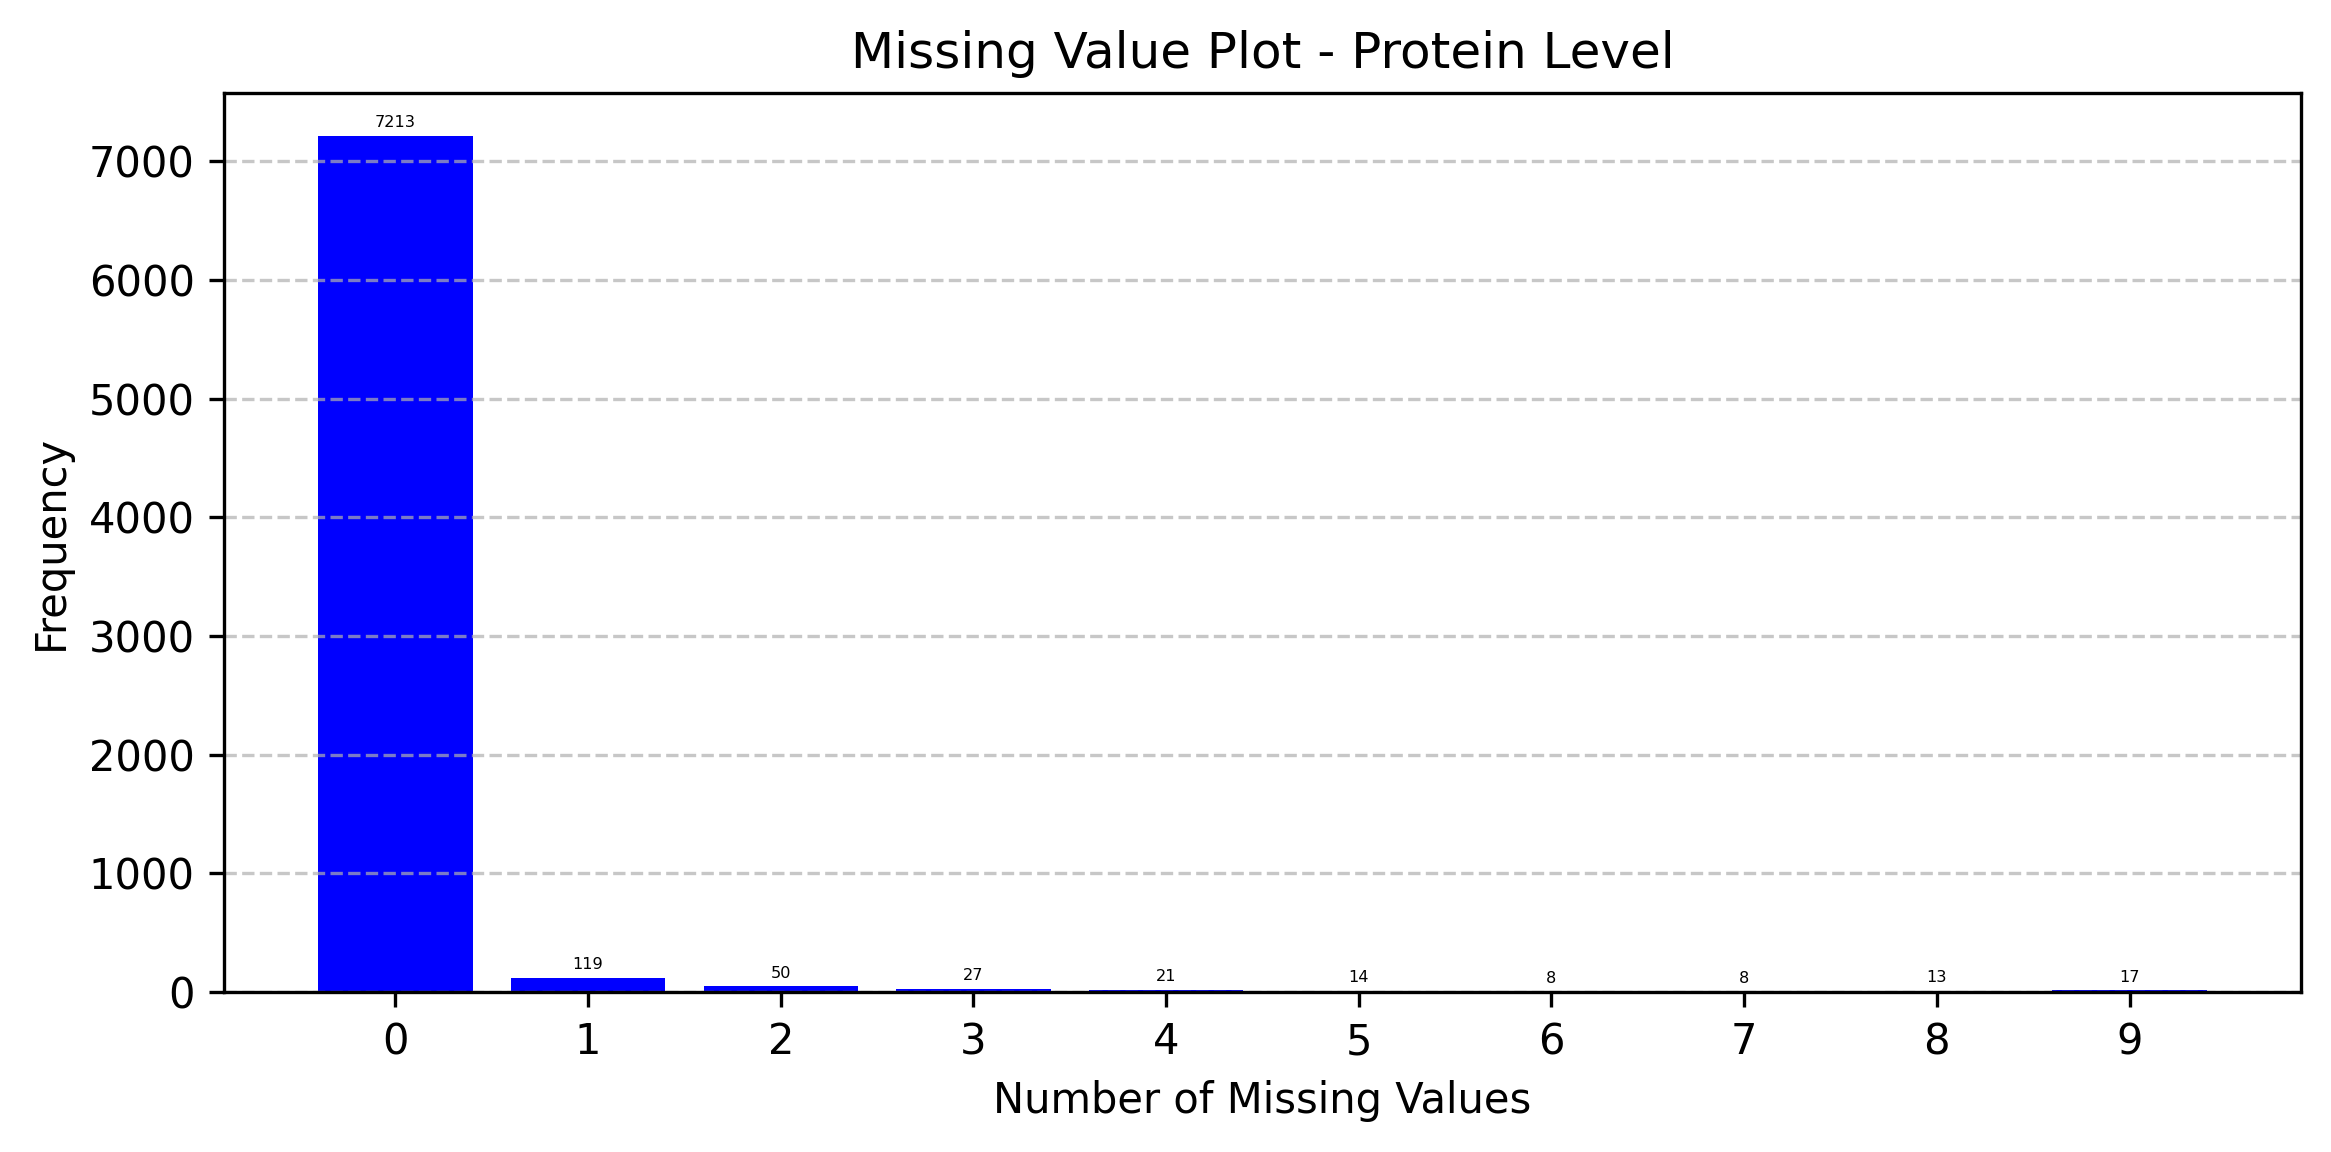

In [4]:
fig = missing_value_plot(data, meta)

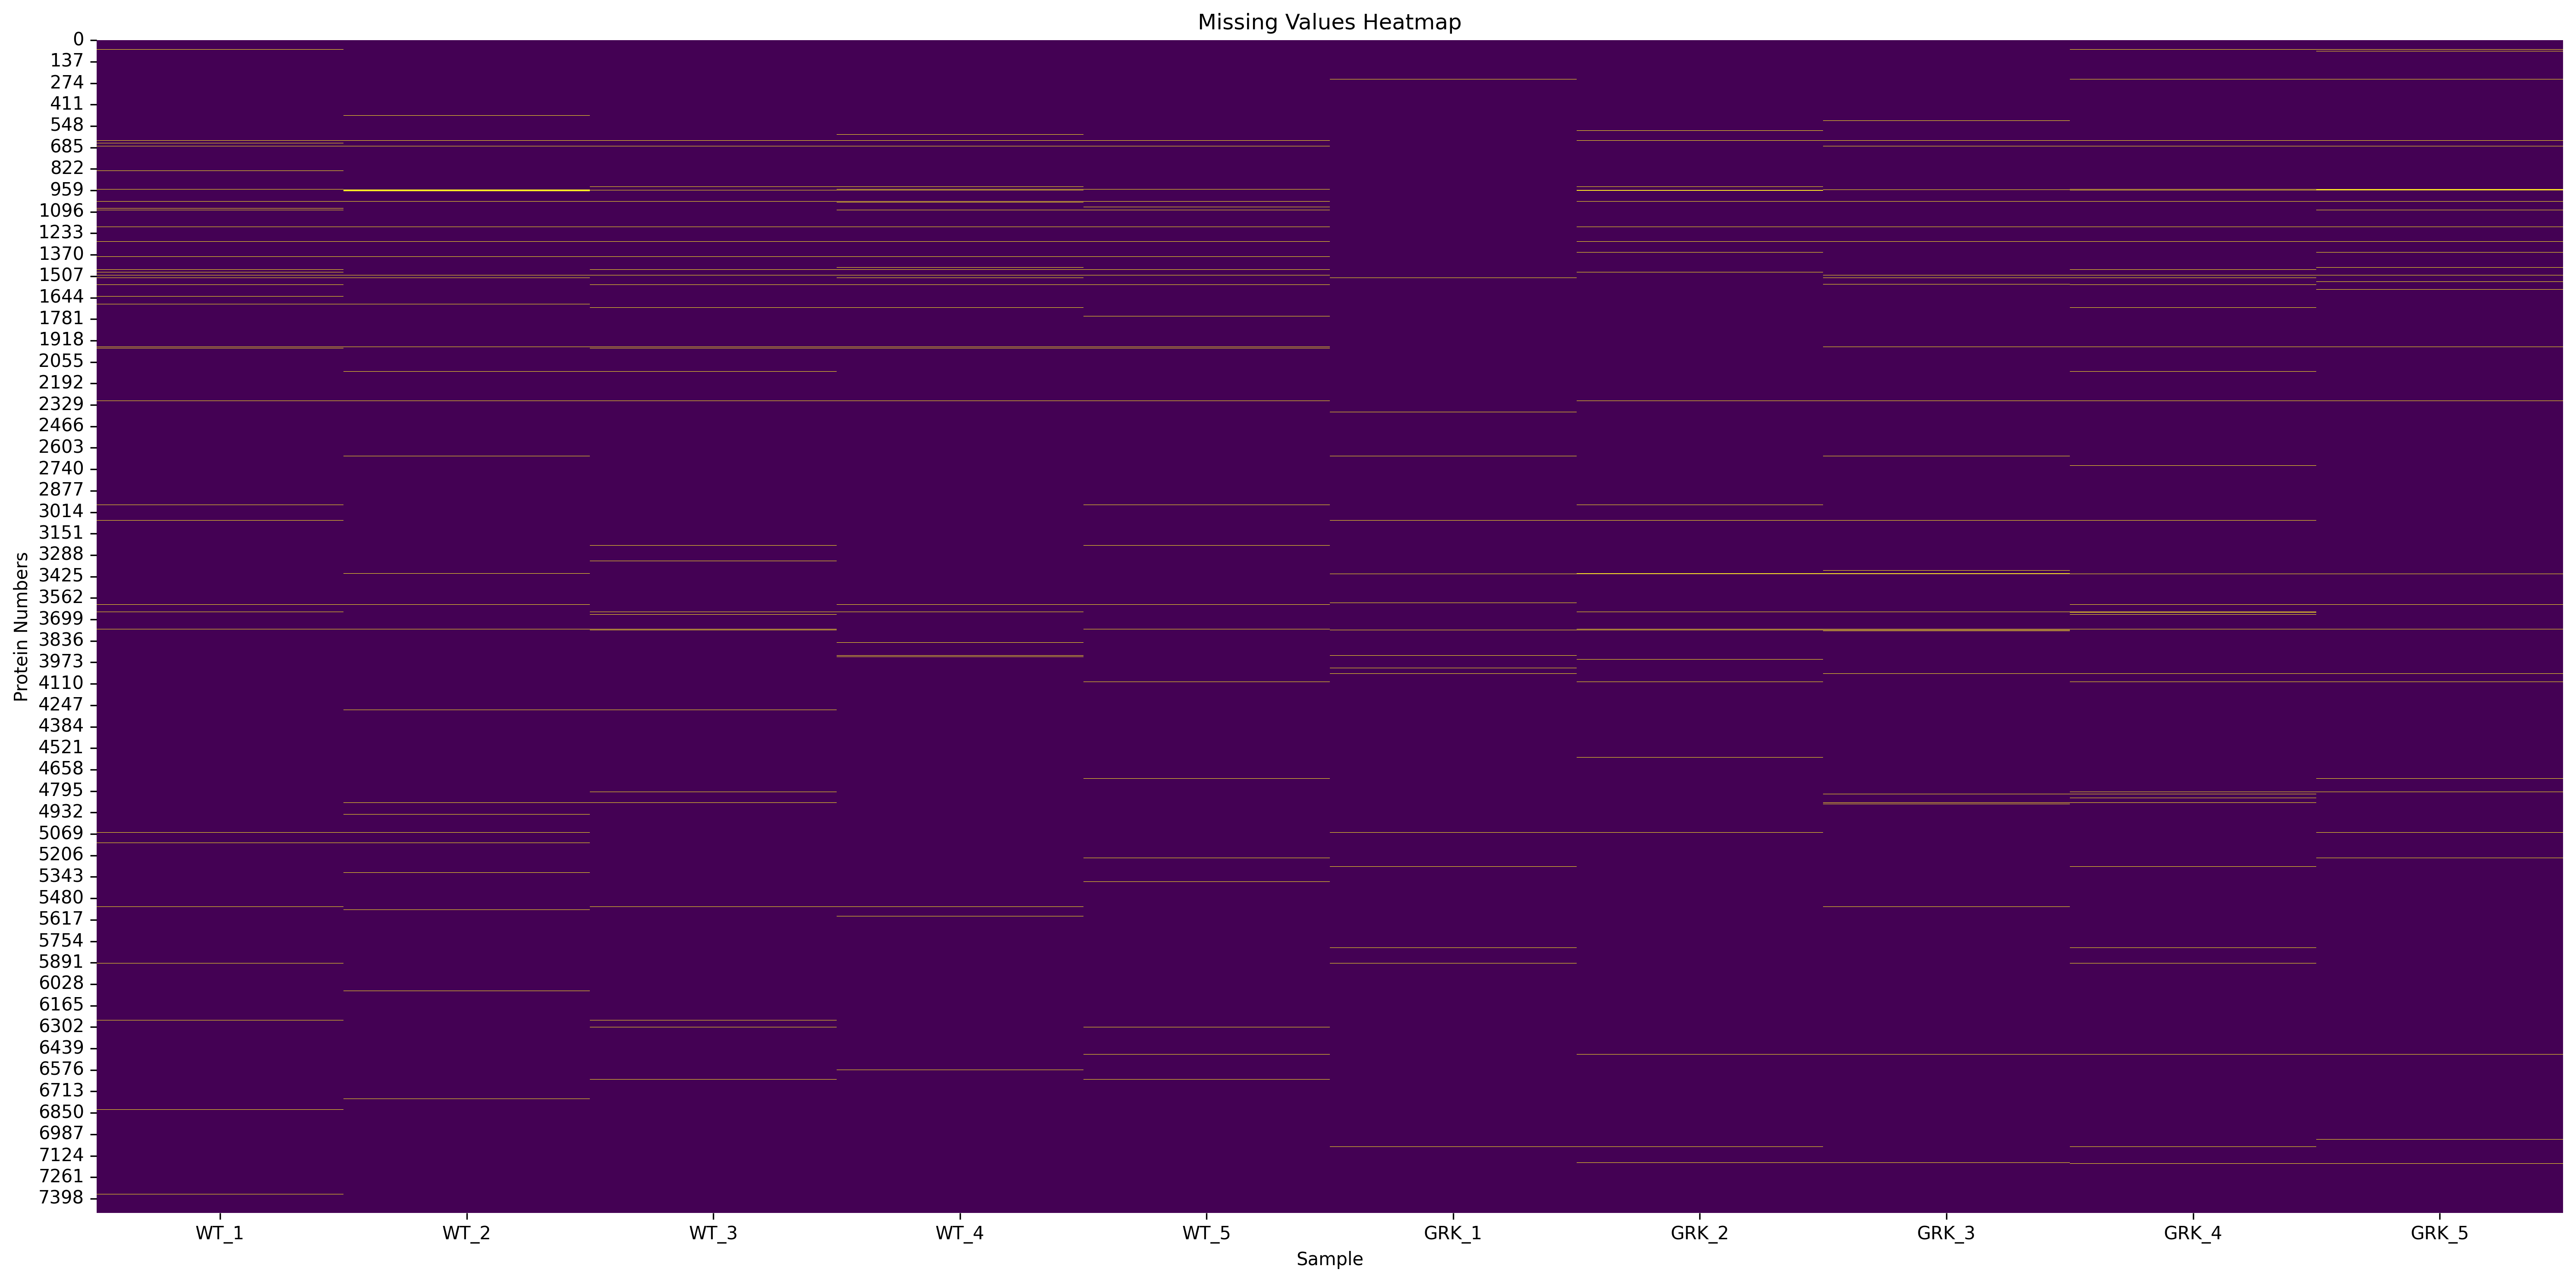

In [5]:
fig = missing_value_heatmap(data, meta, id=False)

In [6]:
missing_protein_table(data, meta, id=False)

,n_MissingProteinValues,Counts,%_missing_values
0,0,7213,96.301736
1,1,119,1.588785
2,2,50,0.667557
3,3,27,0.360481
4,4,21,0.280374
5,5,14,0.186916
6,6,8,0.106809
7,7,8,0.106809
8,8,13,0.173565
9,9,17,0.226969


In [7]:
missing_sample_table(data, meta, id=False)

,Sample,Counts,%_missing_values
0,WT_1,80,1.068091
1,WT_2,88,1.174900
2,WT_3,83,1.108144
3,WT_4,85,1.134846
4,WT_5,81,1.081442
5,GRK_1,50,0.667557
6,GRK_2,71,0.947931
7,GRK_3,78,1.041389
8,GRK_4,99,1.321762
9,GRK_5,100,1.335113


## QC Pipeline


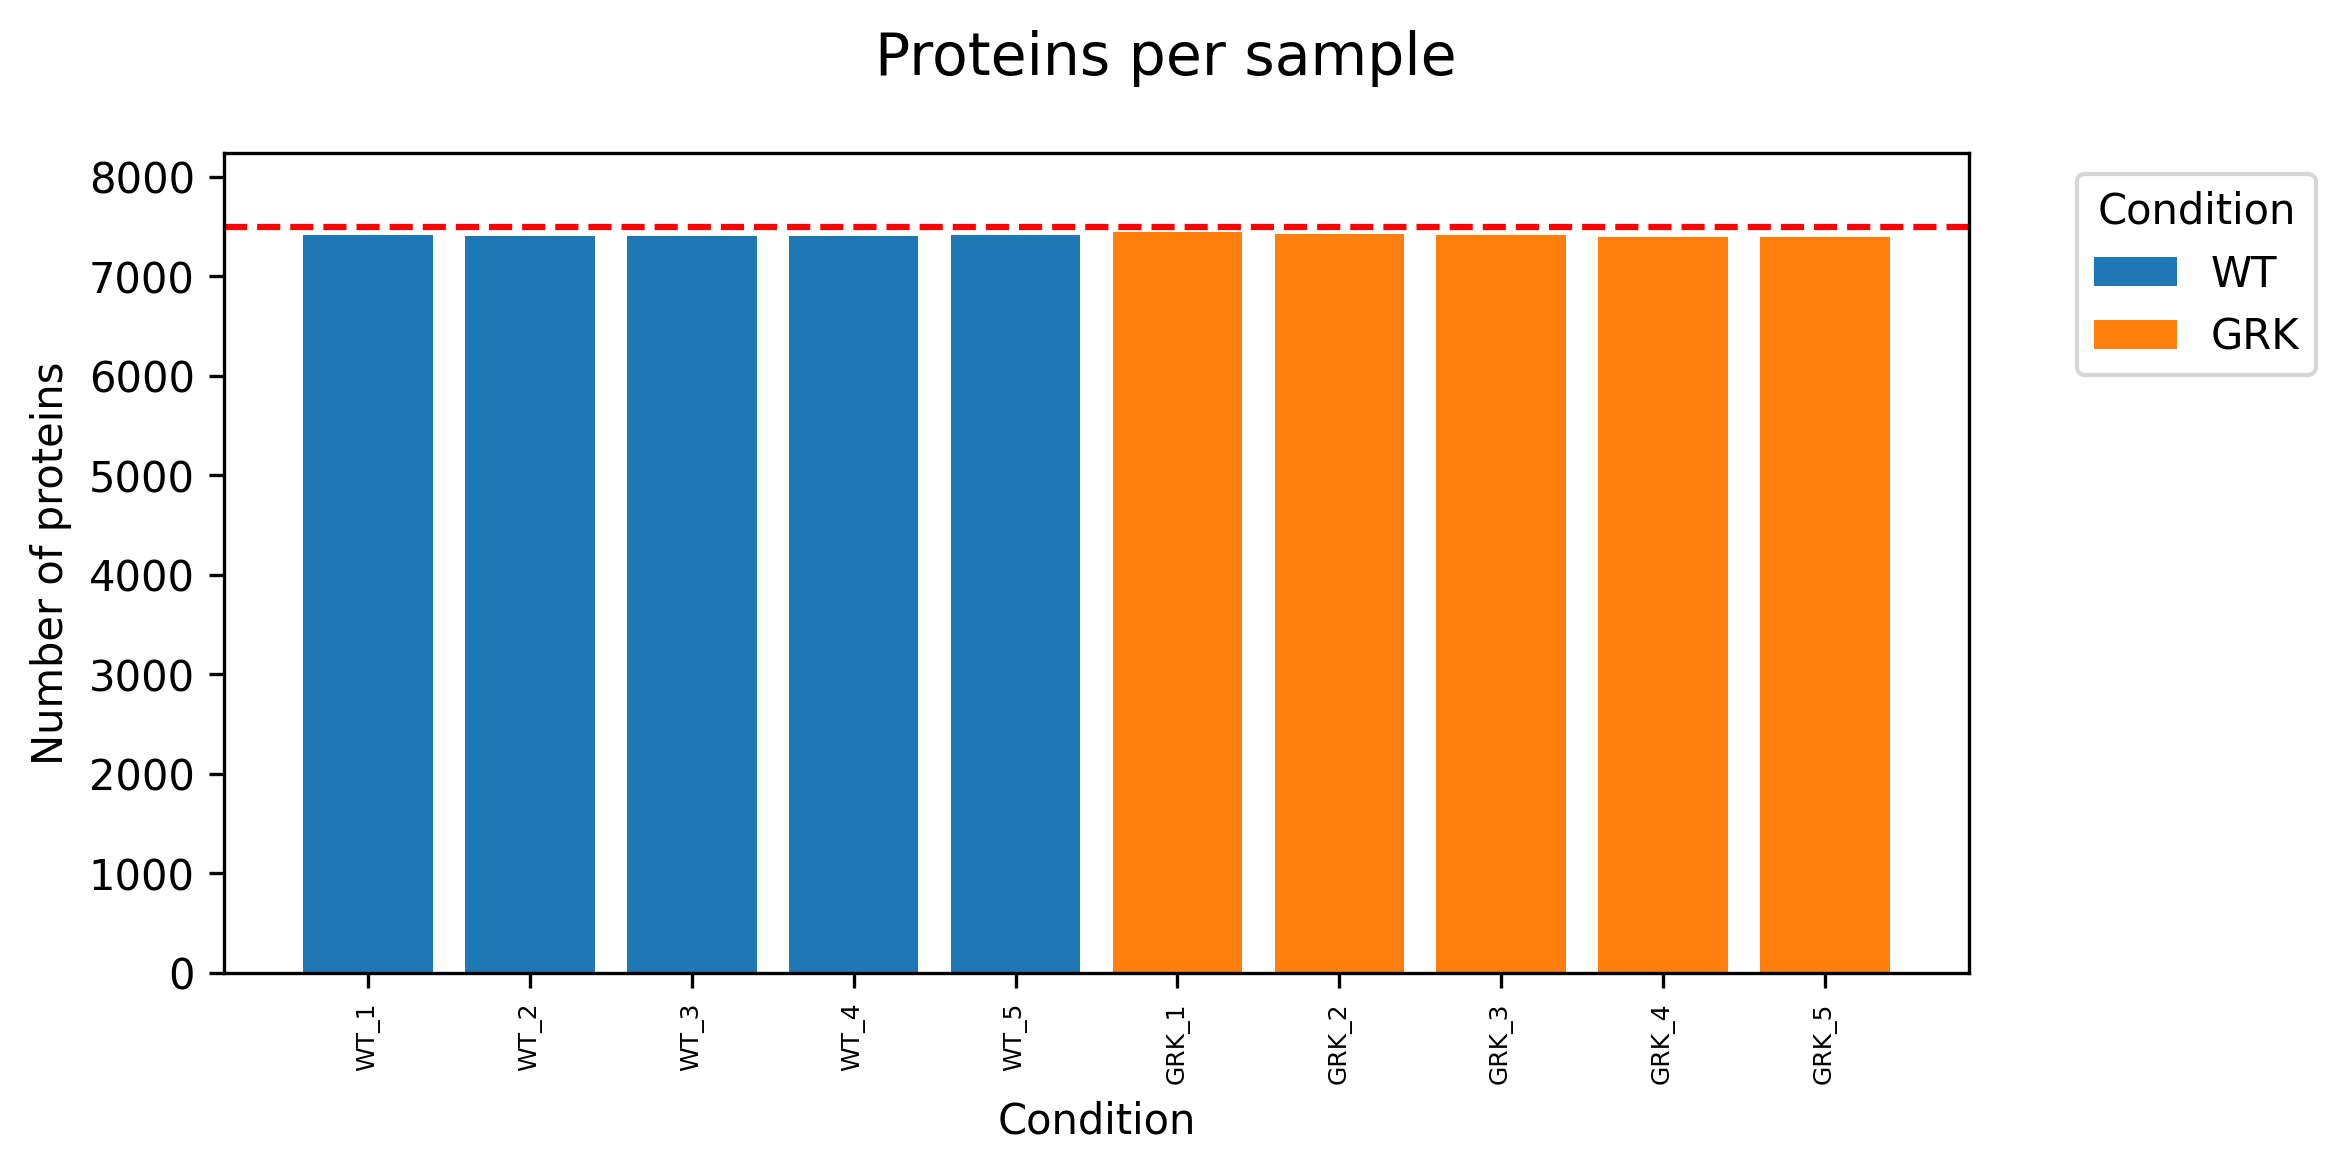

In [8]:
fig = coverage_plot(data, meta, id=False)

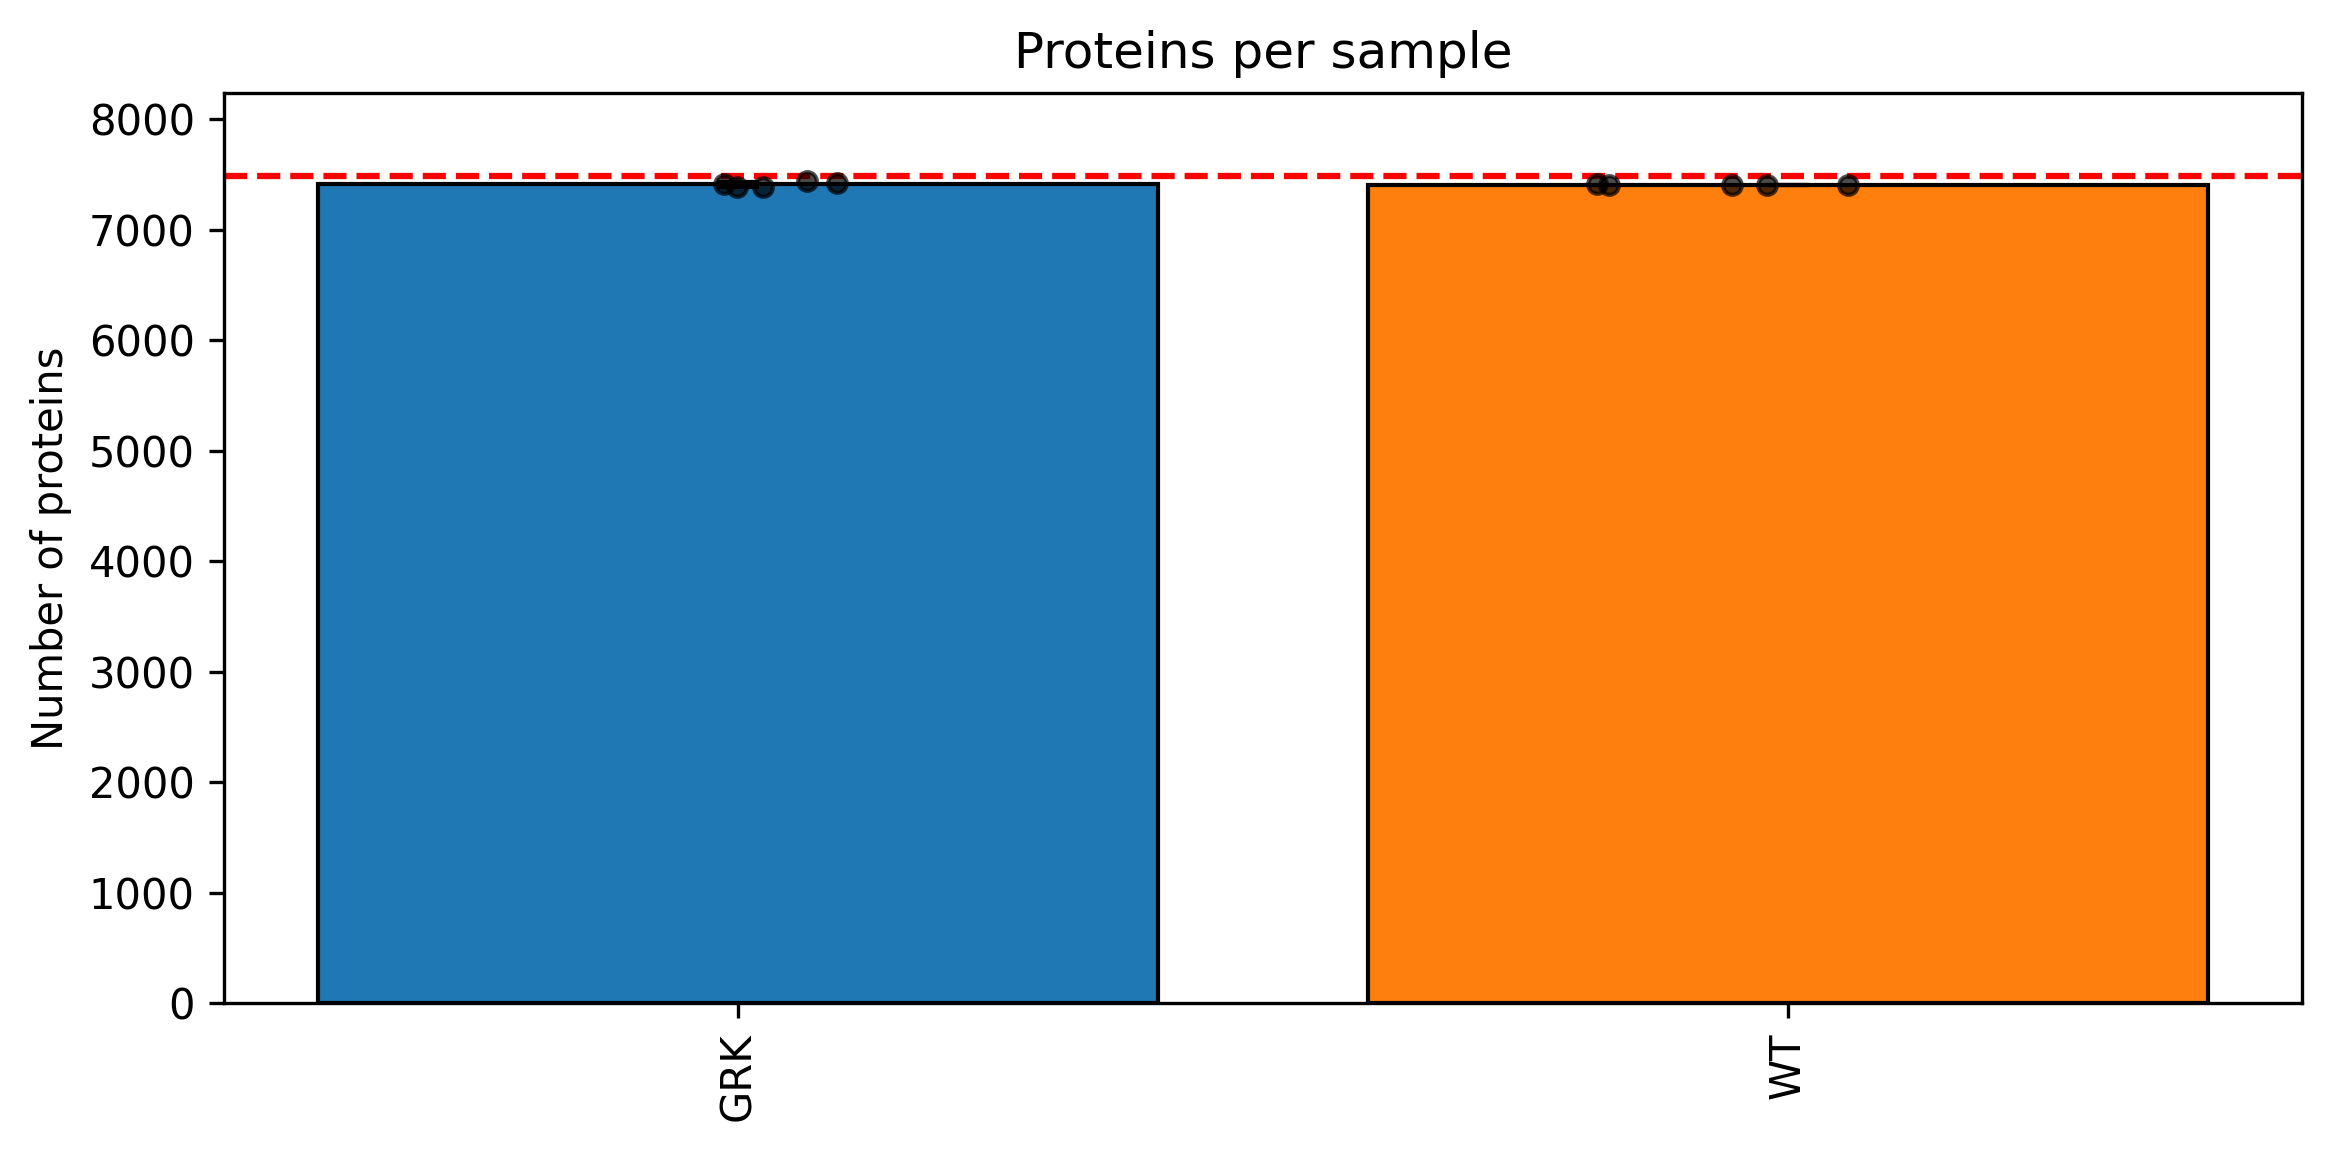

In [9]:
fig = coverage_plot_summary(data, meta)

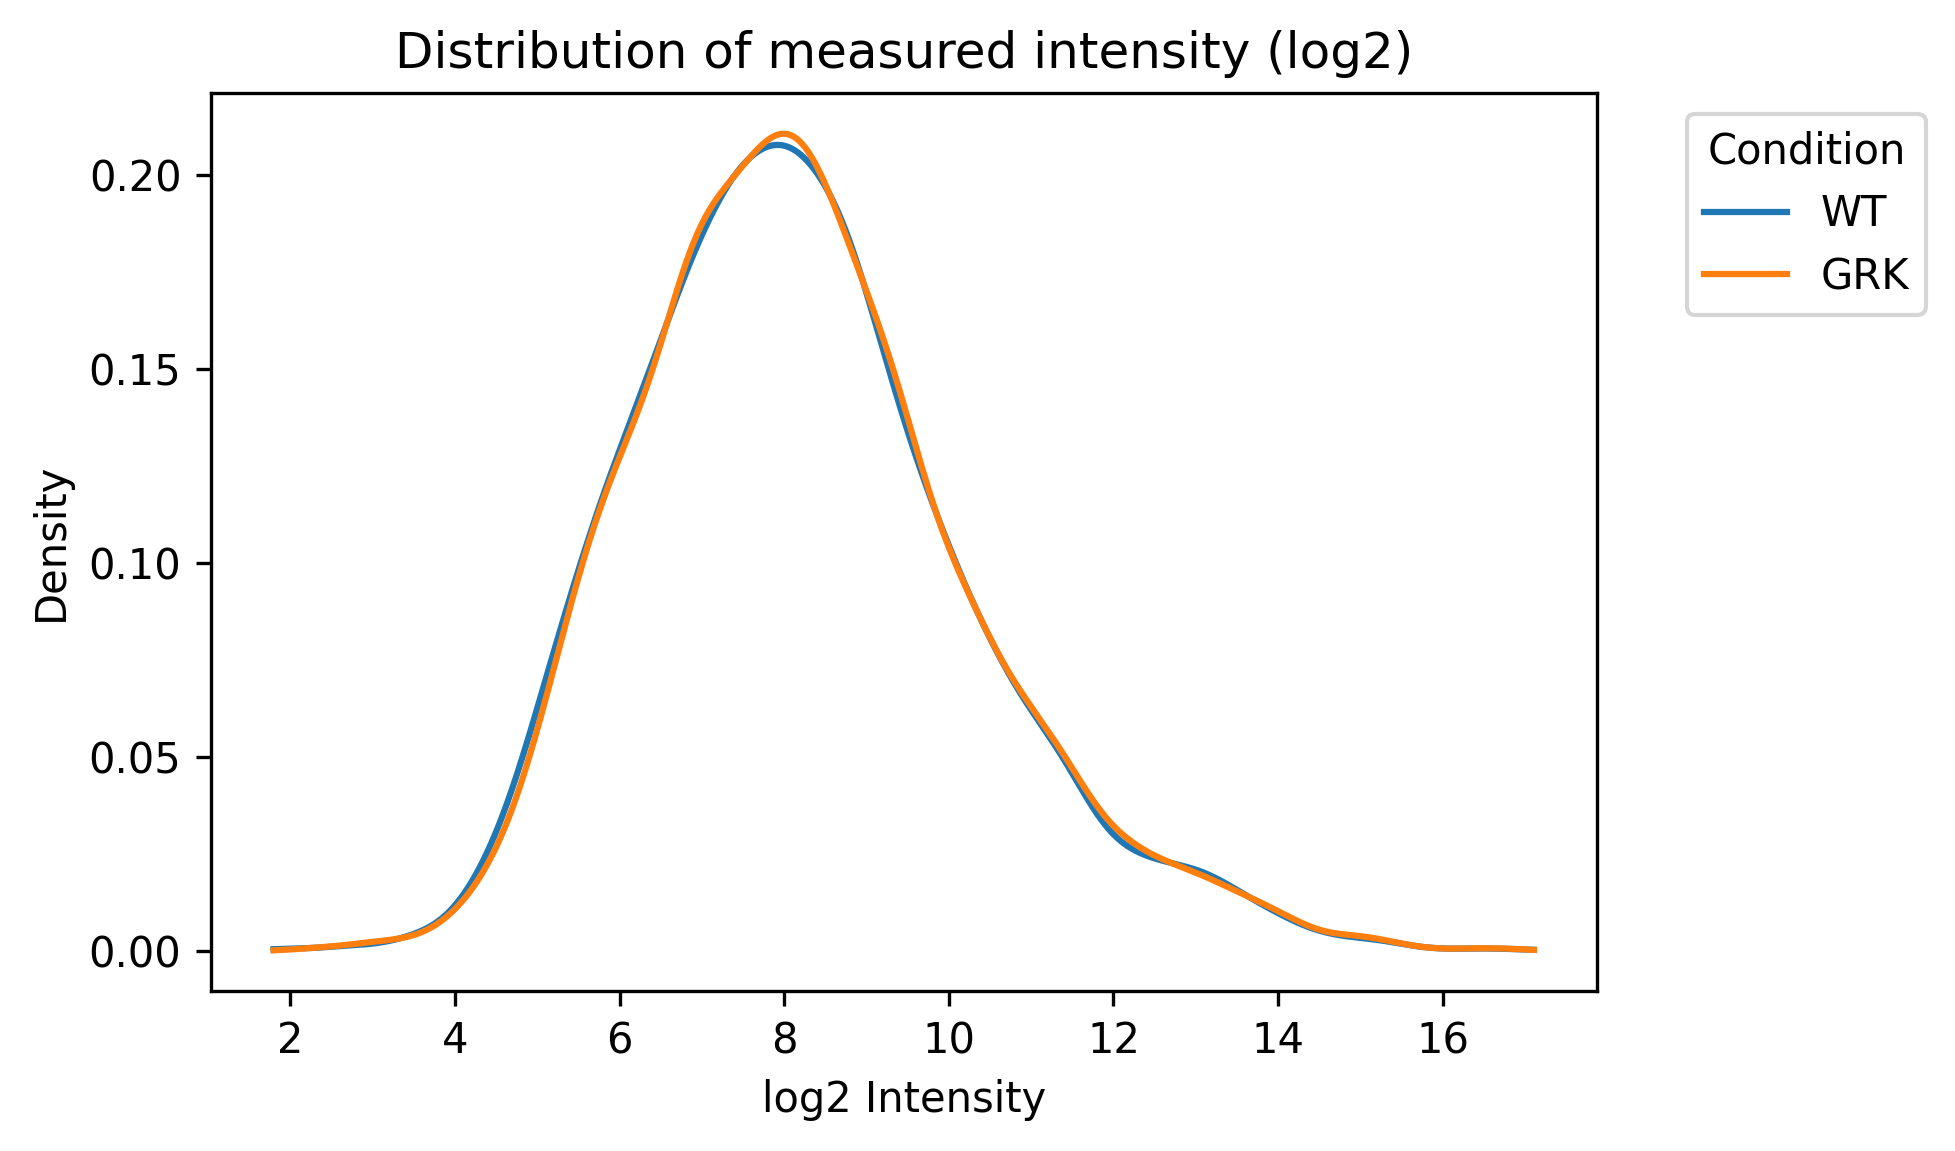

In [10]:
fig = histo_int(data, meta)

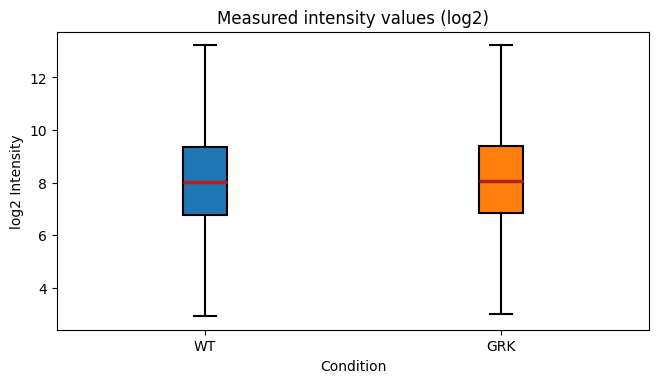

In [11]:
fig = boxplot_int(data, meta)

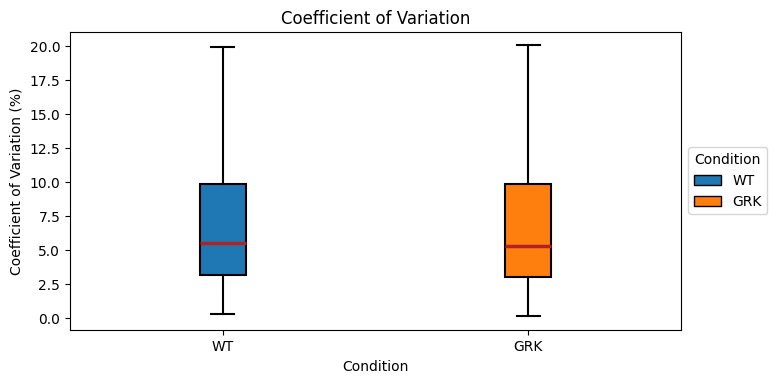

In [12]:
fig = cov_plot(org_data, meta)

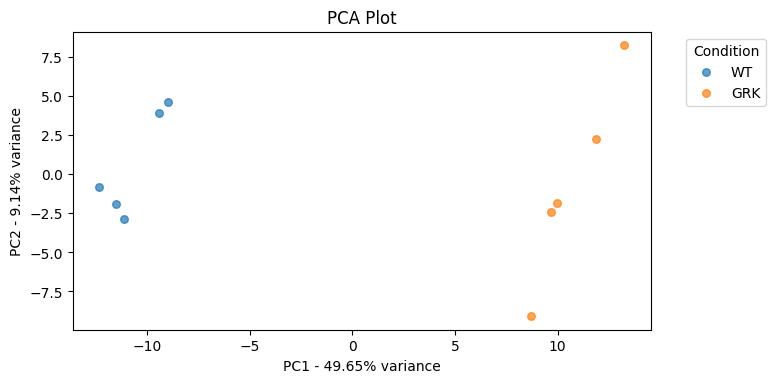

In [13]:
fig = pca_plot(data, meta)

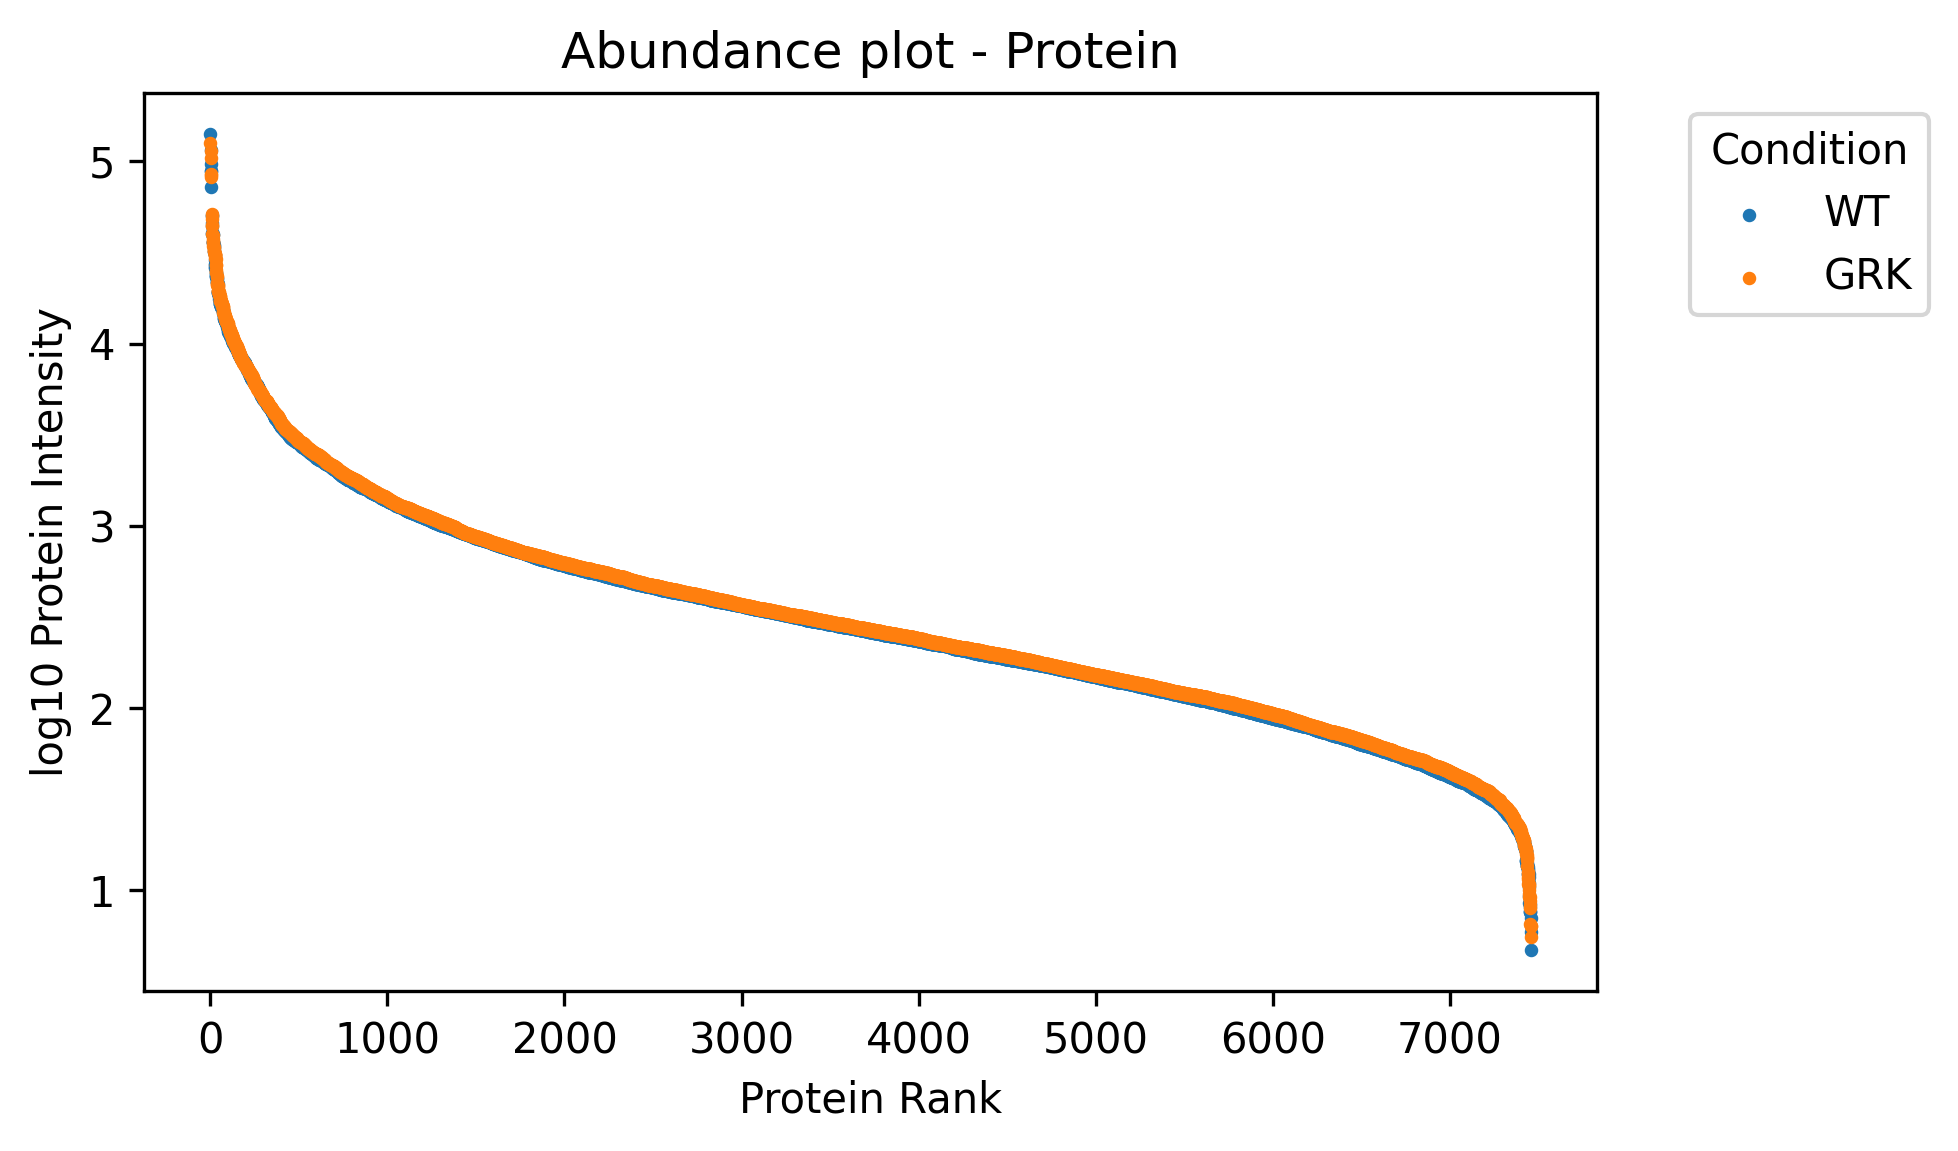

In [14]:
fig = abundance_plot(org_data, meta, workflow="Protein")

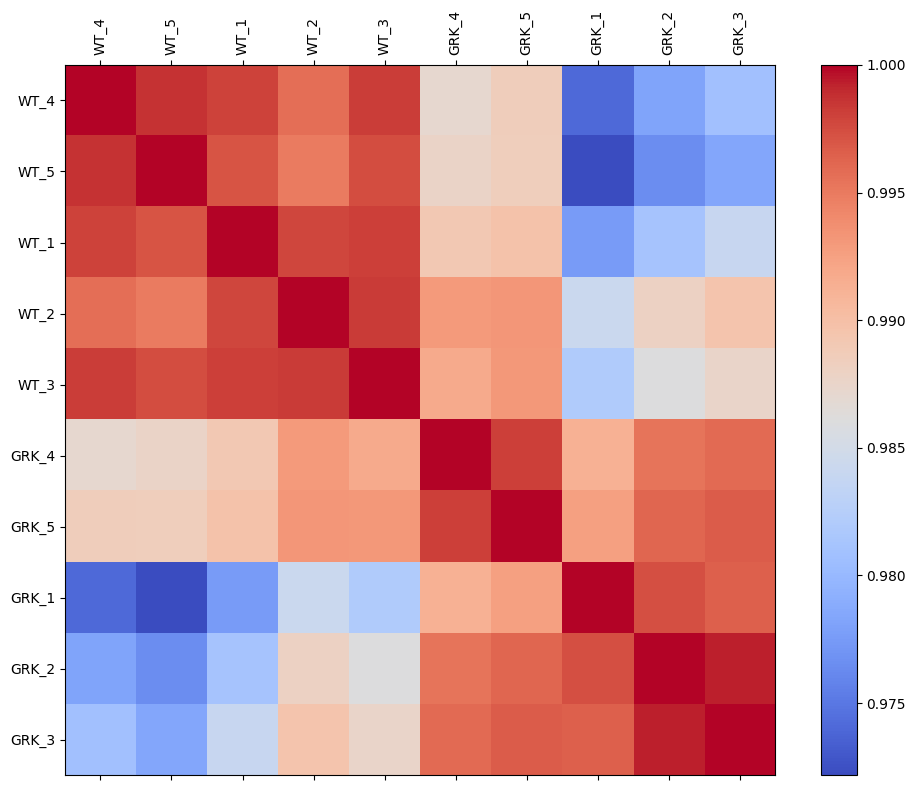

In [15]:
fig = corr_plot(org_data, meta, id=False)

## Volcano Plot


In [16]:
volcano_data = volcano_data_f(data, meta, "WT", "GRK", workflow="Protein")
volcano_data.head()

,ProteinNames,log2FC,pval,adj_pval,significance,neg_log10_adj_pval
0,TMA7B_HUMAN;TMA7_HUMAN,-0.101455,0.482330,0.598185,Not significant,0.223164
1,NUD4B_HUMAN,0.018550,0.877902,0.916099,Not significant,0.038058
2,SIM26_HUMAN,0.564747,0.162496,0.261724,Not significant,0.582156
3,PAL4C_HUMAN,-0.124443,0.017538,0.045752,Not significant,1.339592
4,GAL3B_HUMAN;GAL3A_HUMAN,-0.136213,0.002264,0.009153,Not significant,2.038445


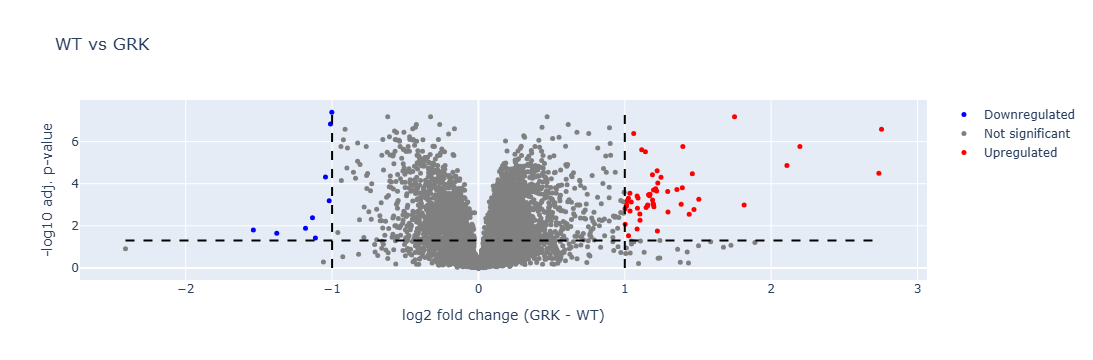

In [17]:
fig = volcano_plot(volcano_data, "WT", "GRK")
fig.show()

## Single Protein


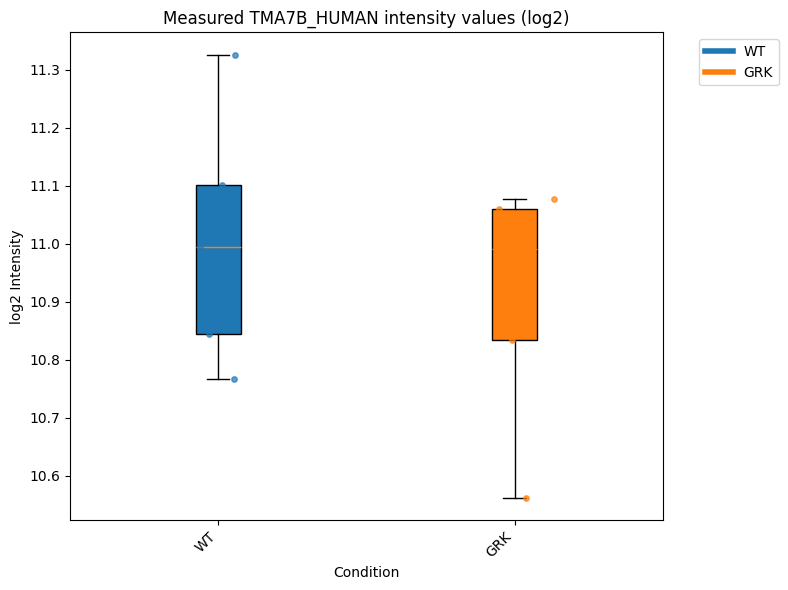

In [18]:
fig = boxplot_int_single_prot(data_by_protein, meta, protein_id, dots=True)

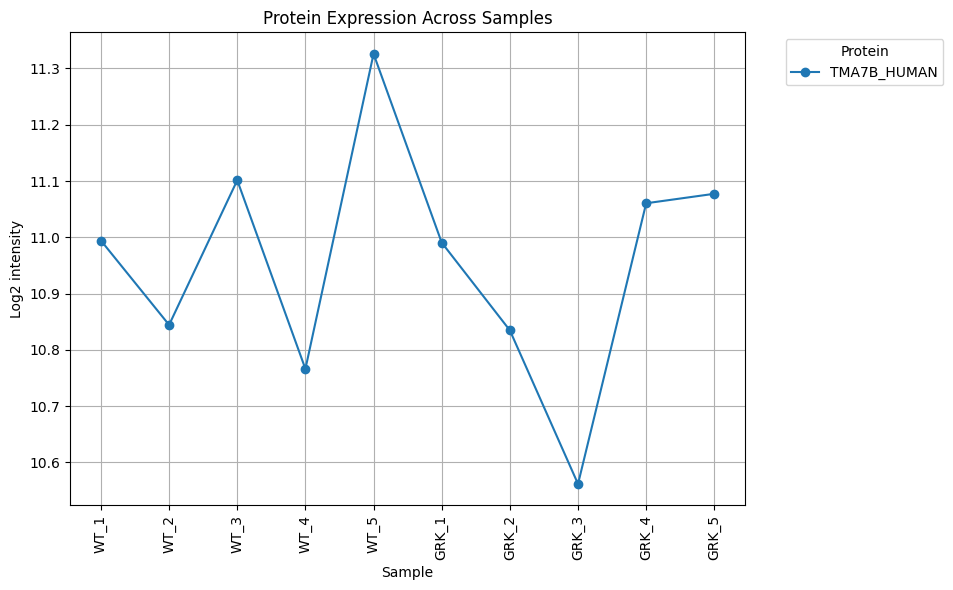

In [19]:
fig = compare_prot_line(data, meta, conditions, [protein_id], workflow="Protein", id=False)

## Comparison


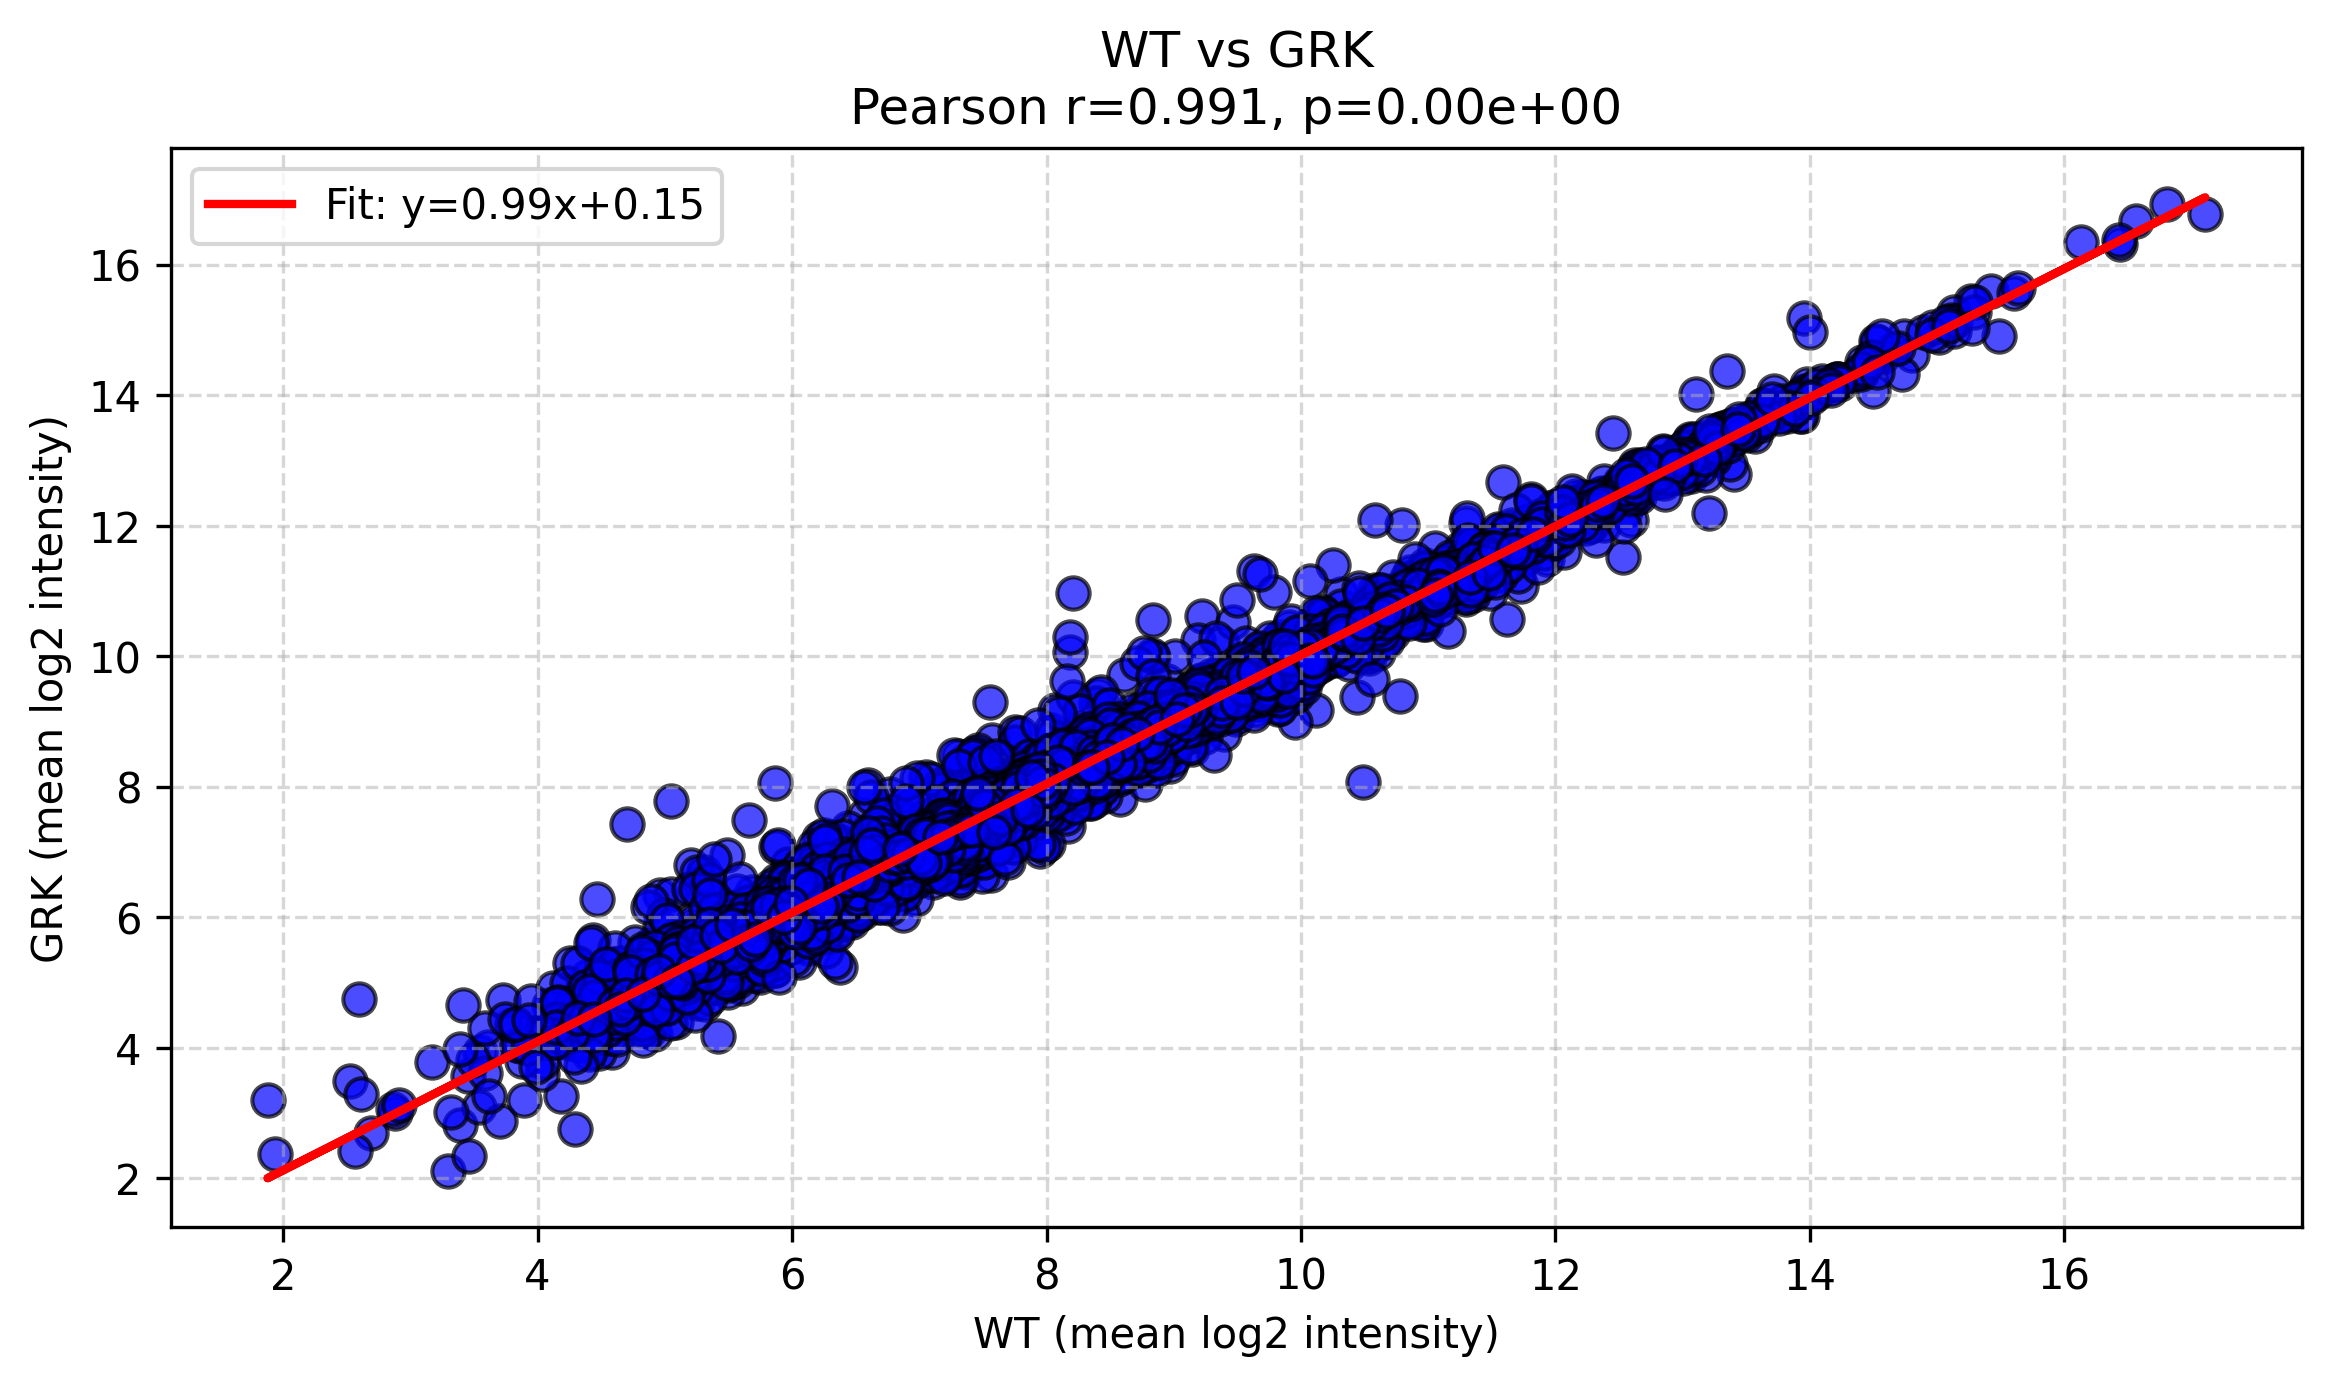

In [20]:
fig = correlation_xy_intensity(data, meta, "WT", "GRK")

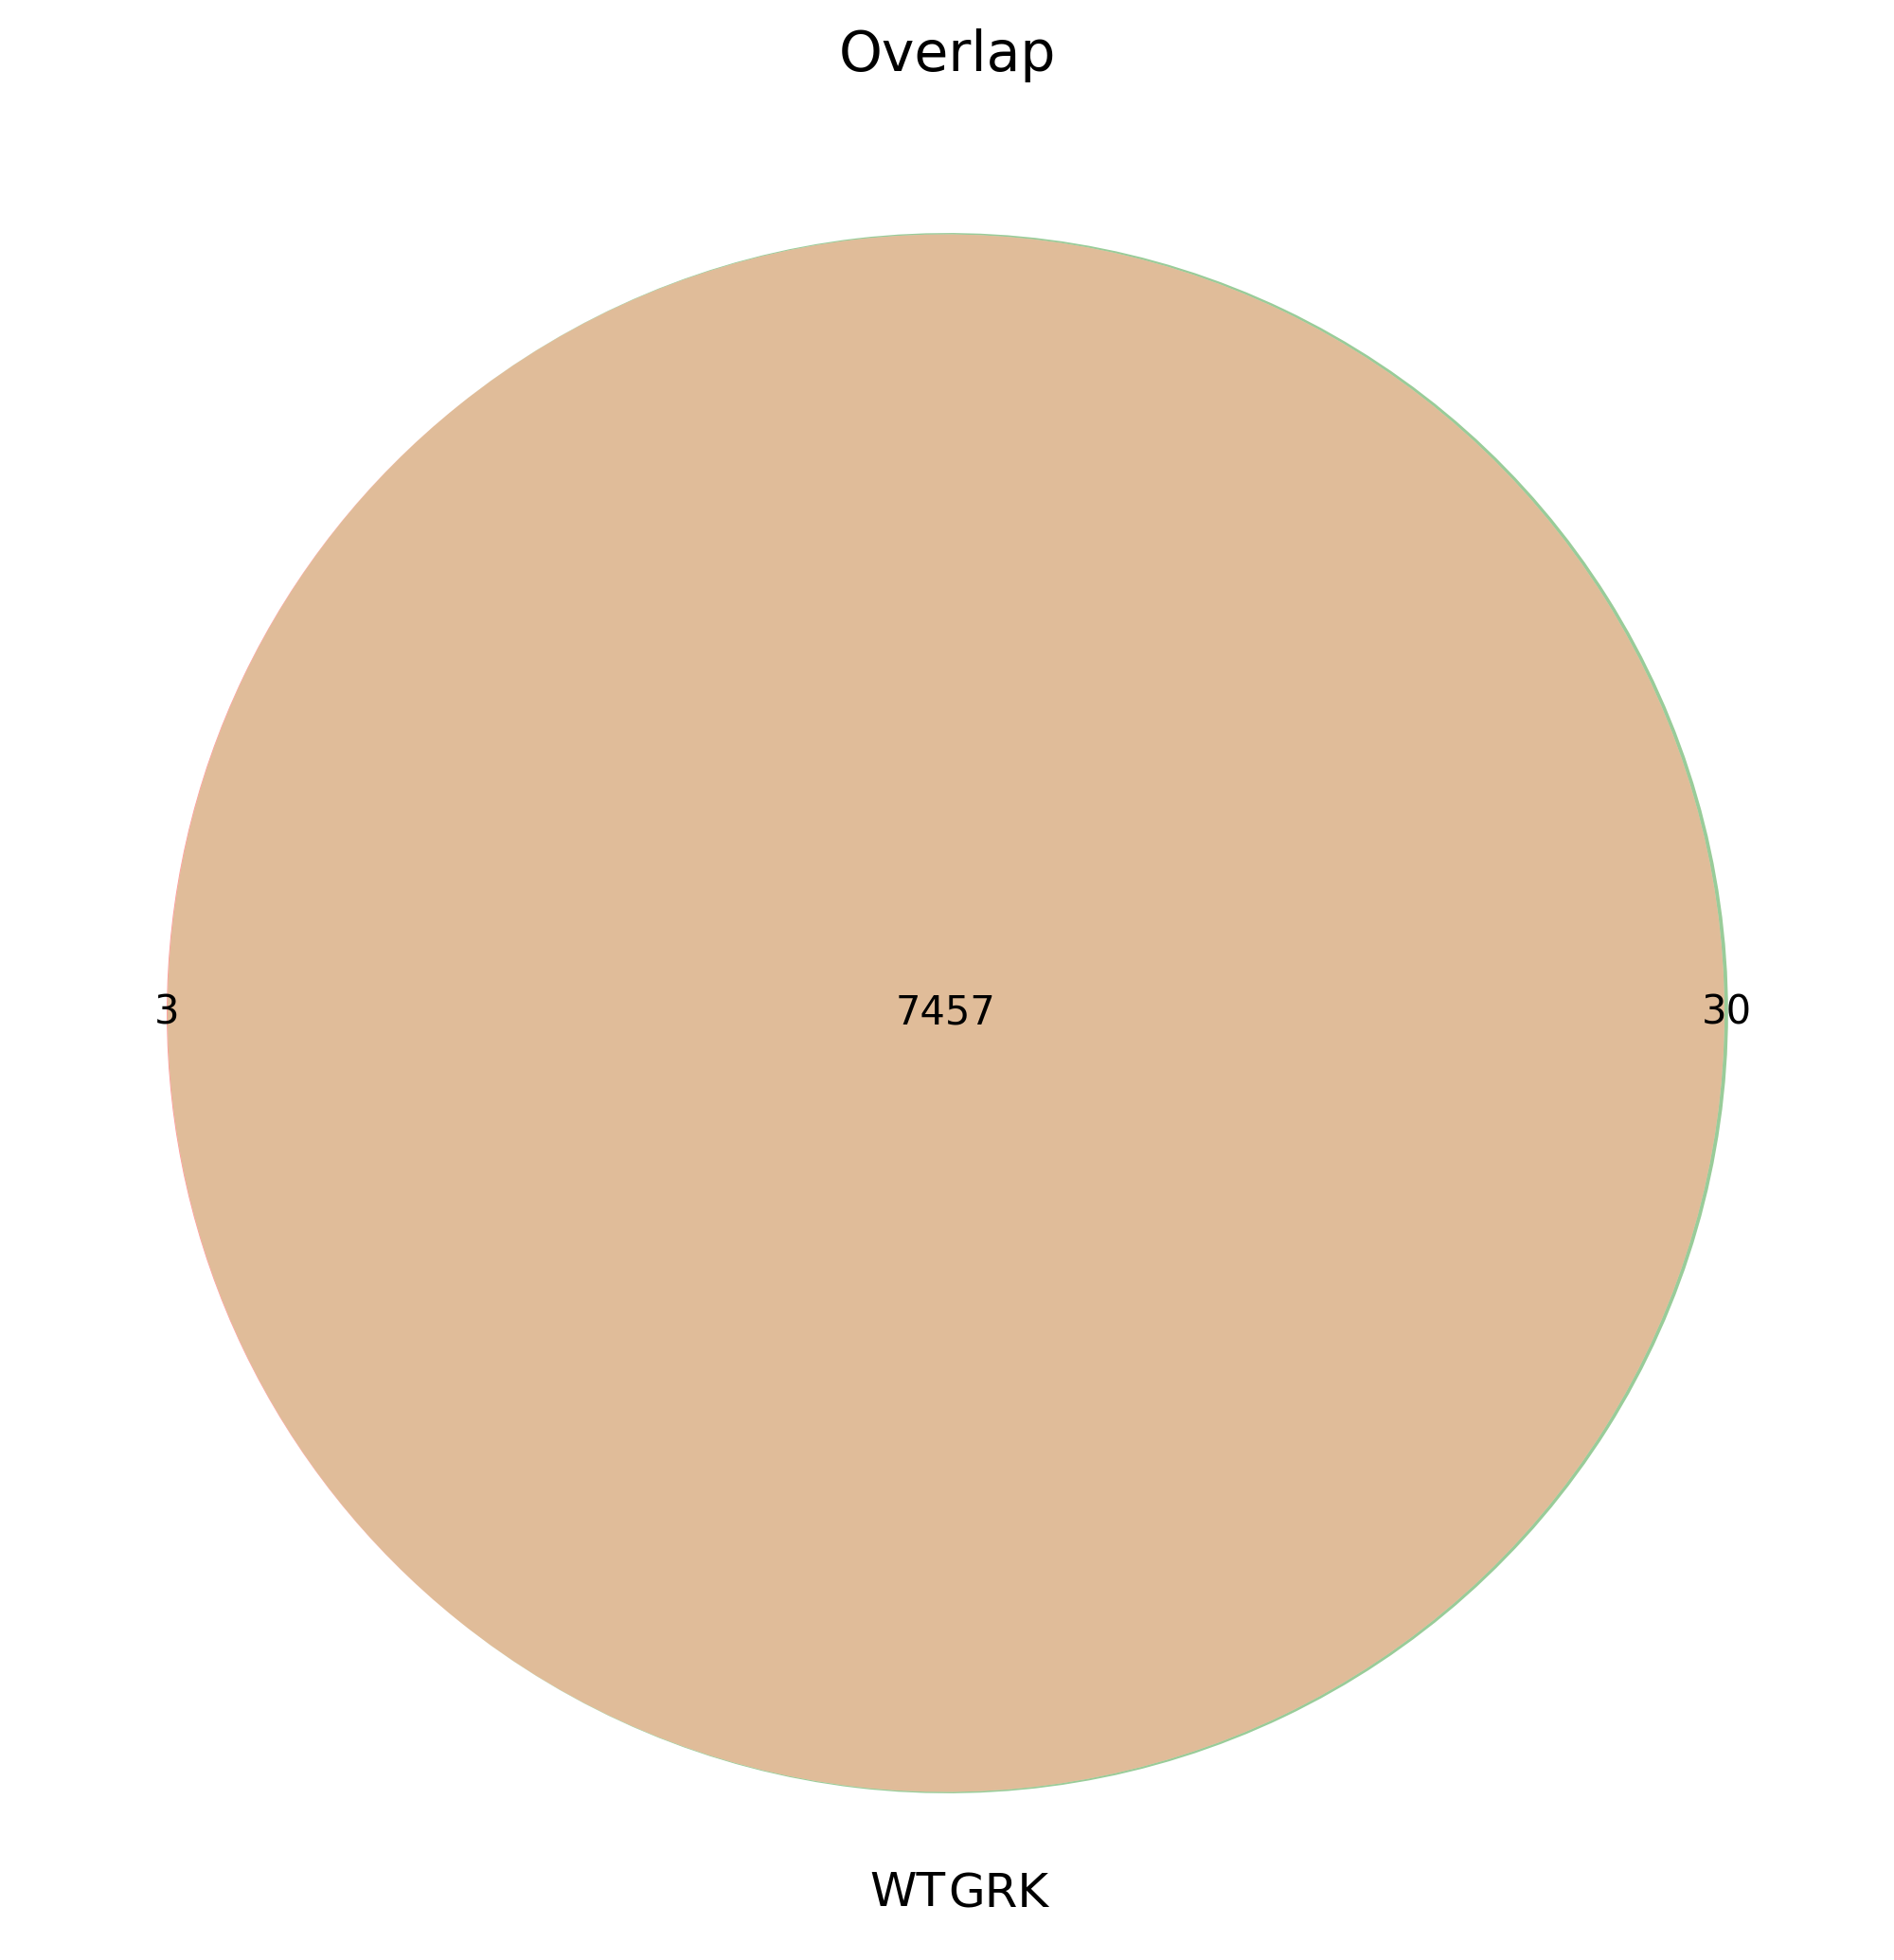

In [21]:
fig = overlap_plot_condition(data_by_protein, meta, "WT", "GRK")

# Phospho


## Phospho-Specific


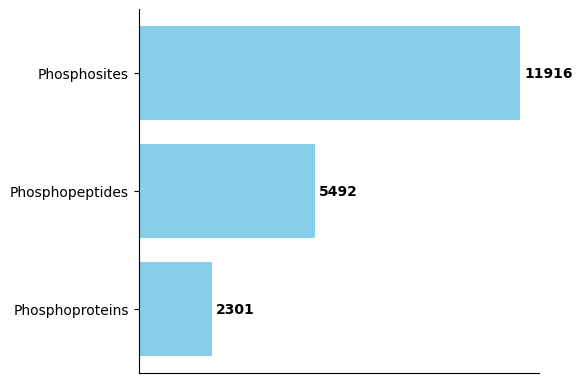

In [22]:
fig = simple_phos_site_plot(data3)

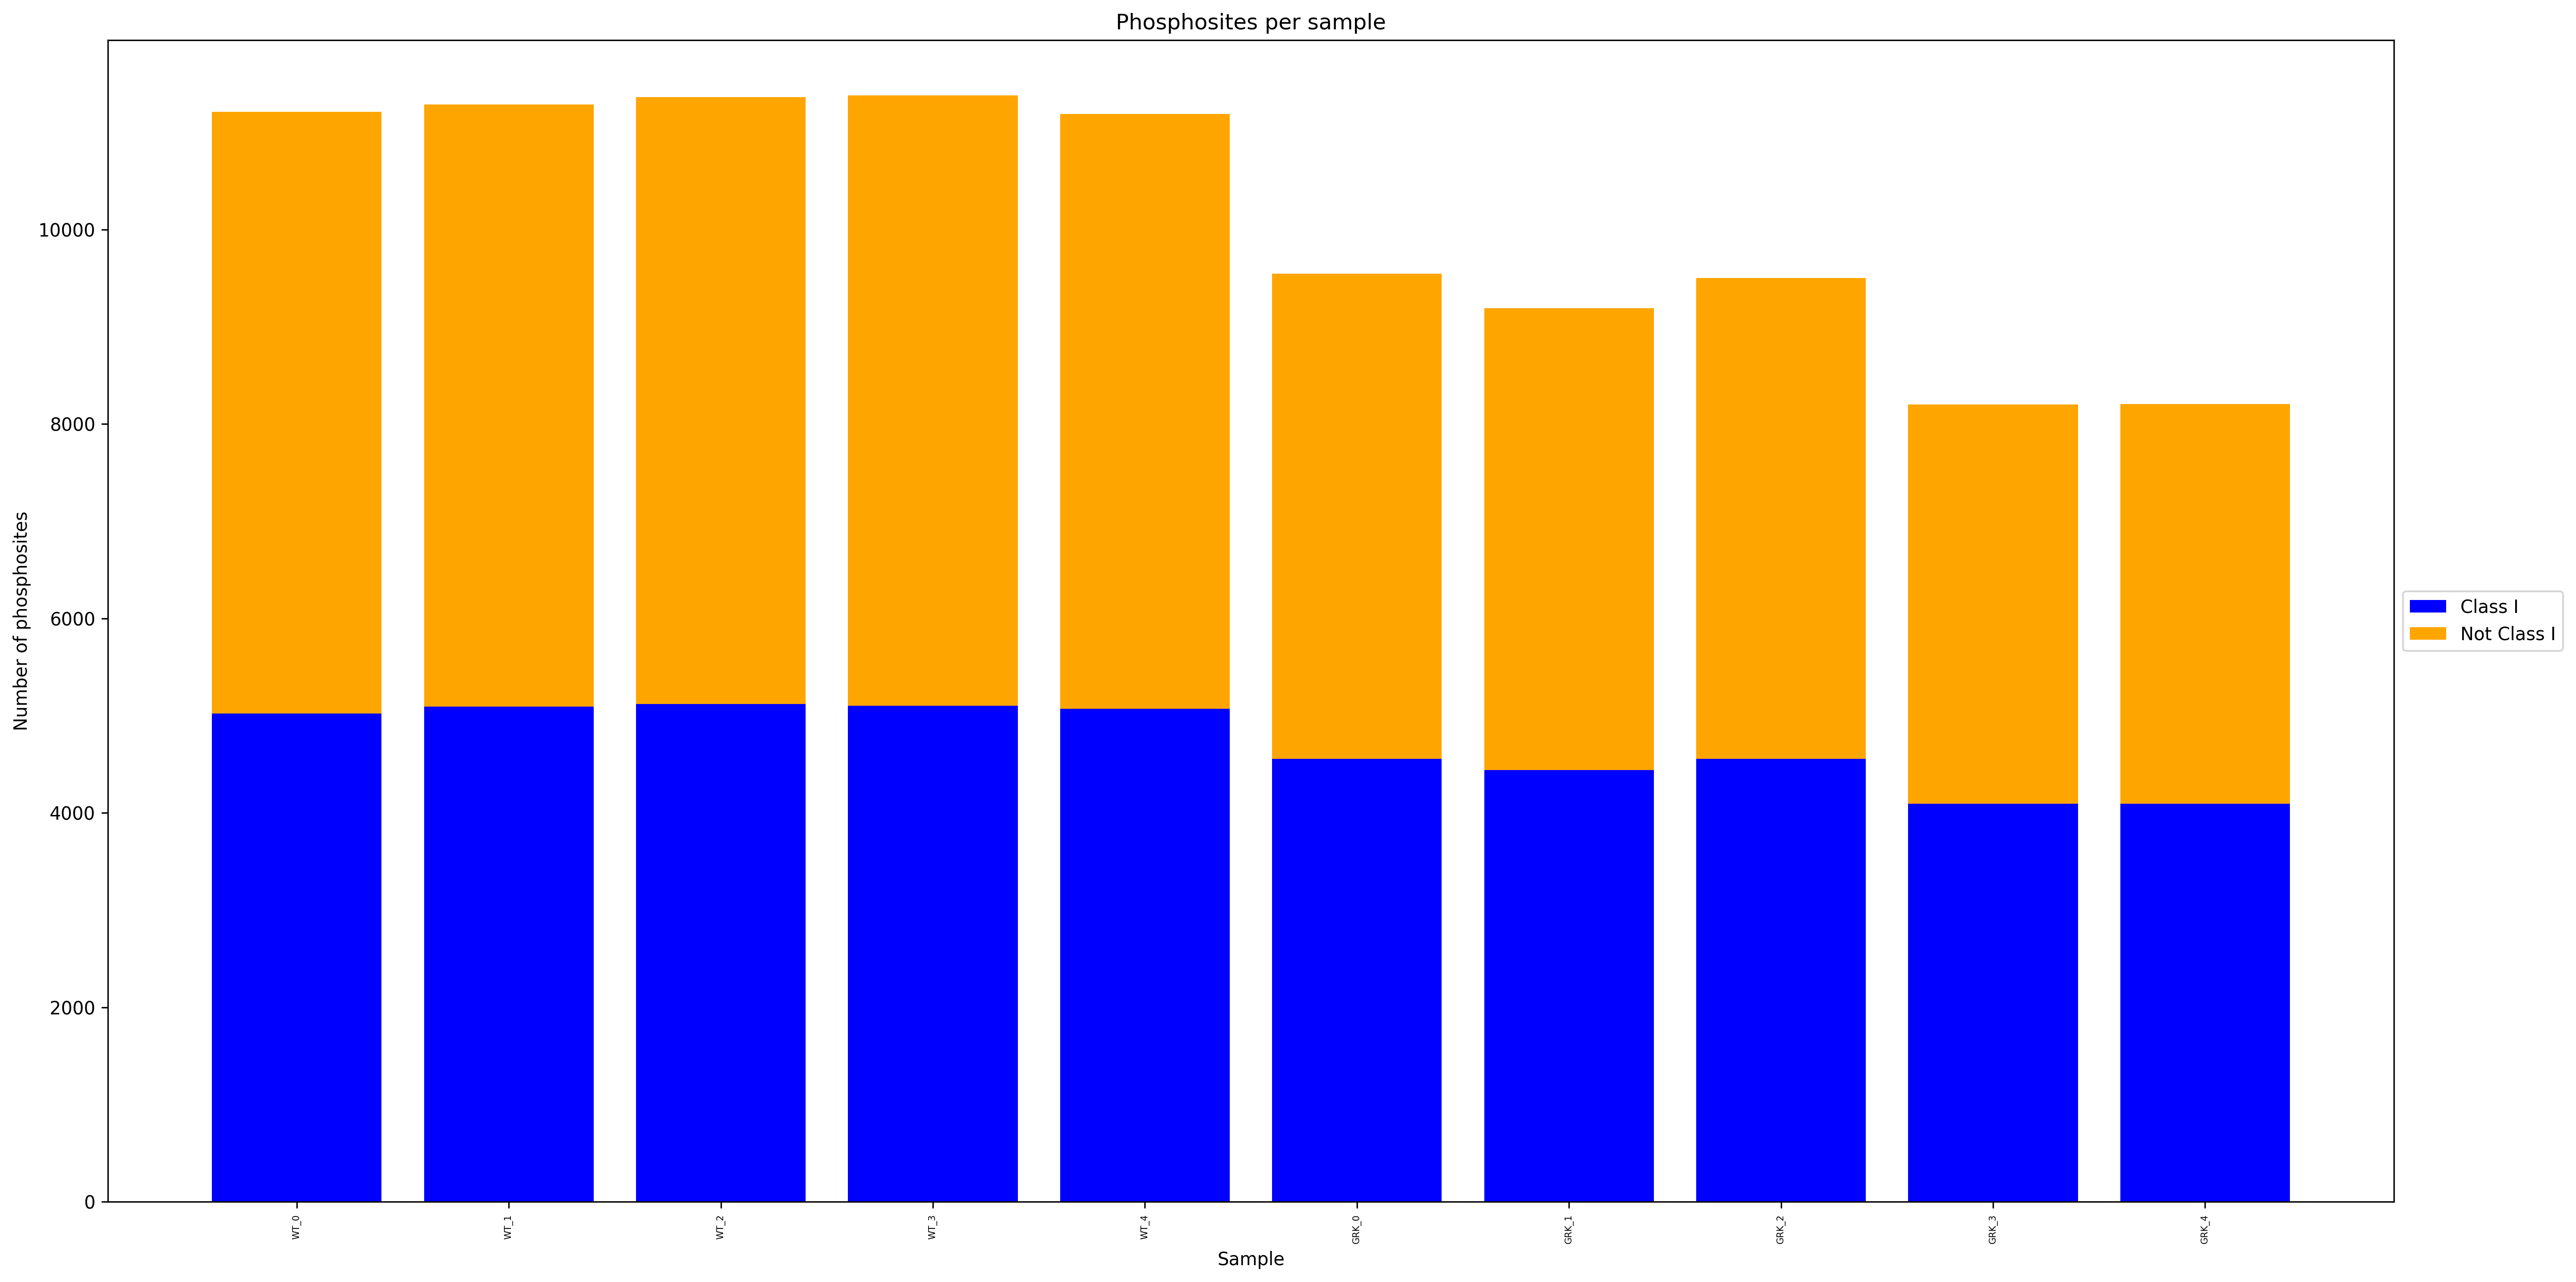

In [23]:
fig = phossite_coverage_plot(data3, meta2, id=False)

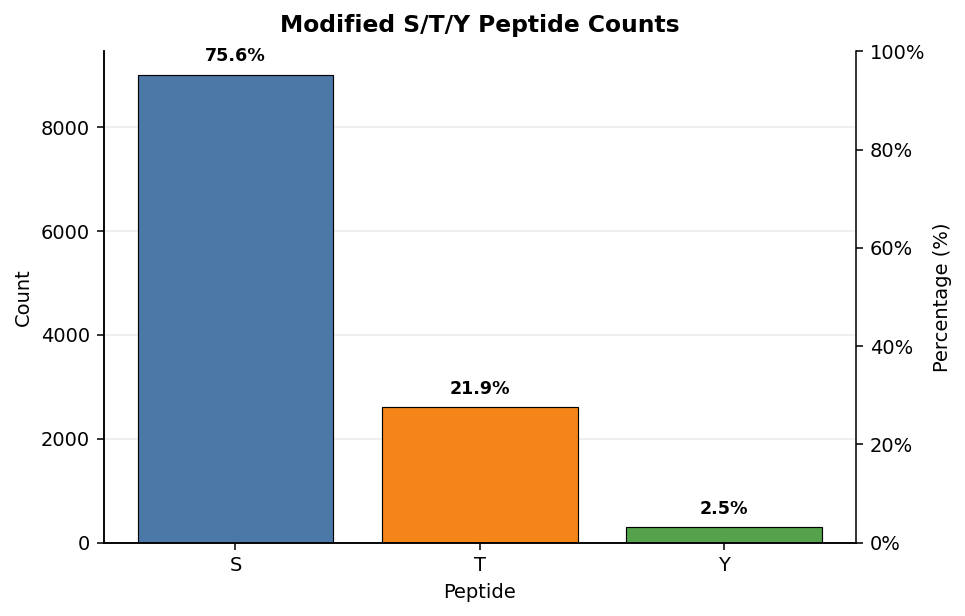

In [24]:
fig = sty_plot(data3)

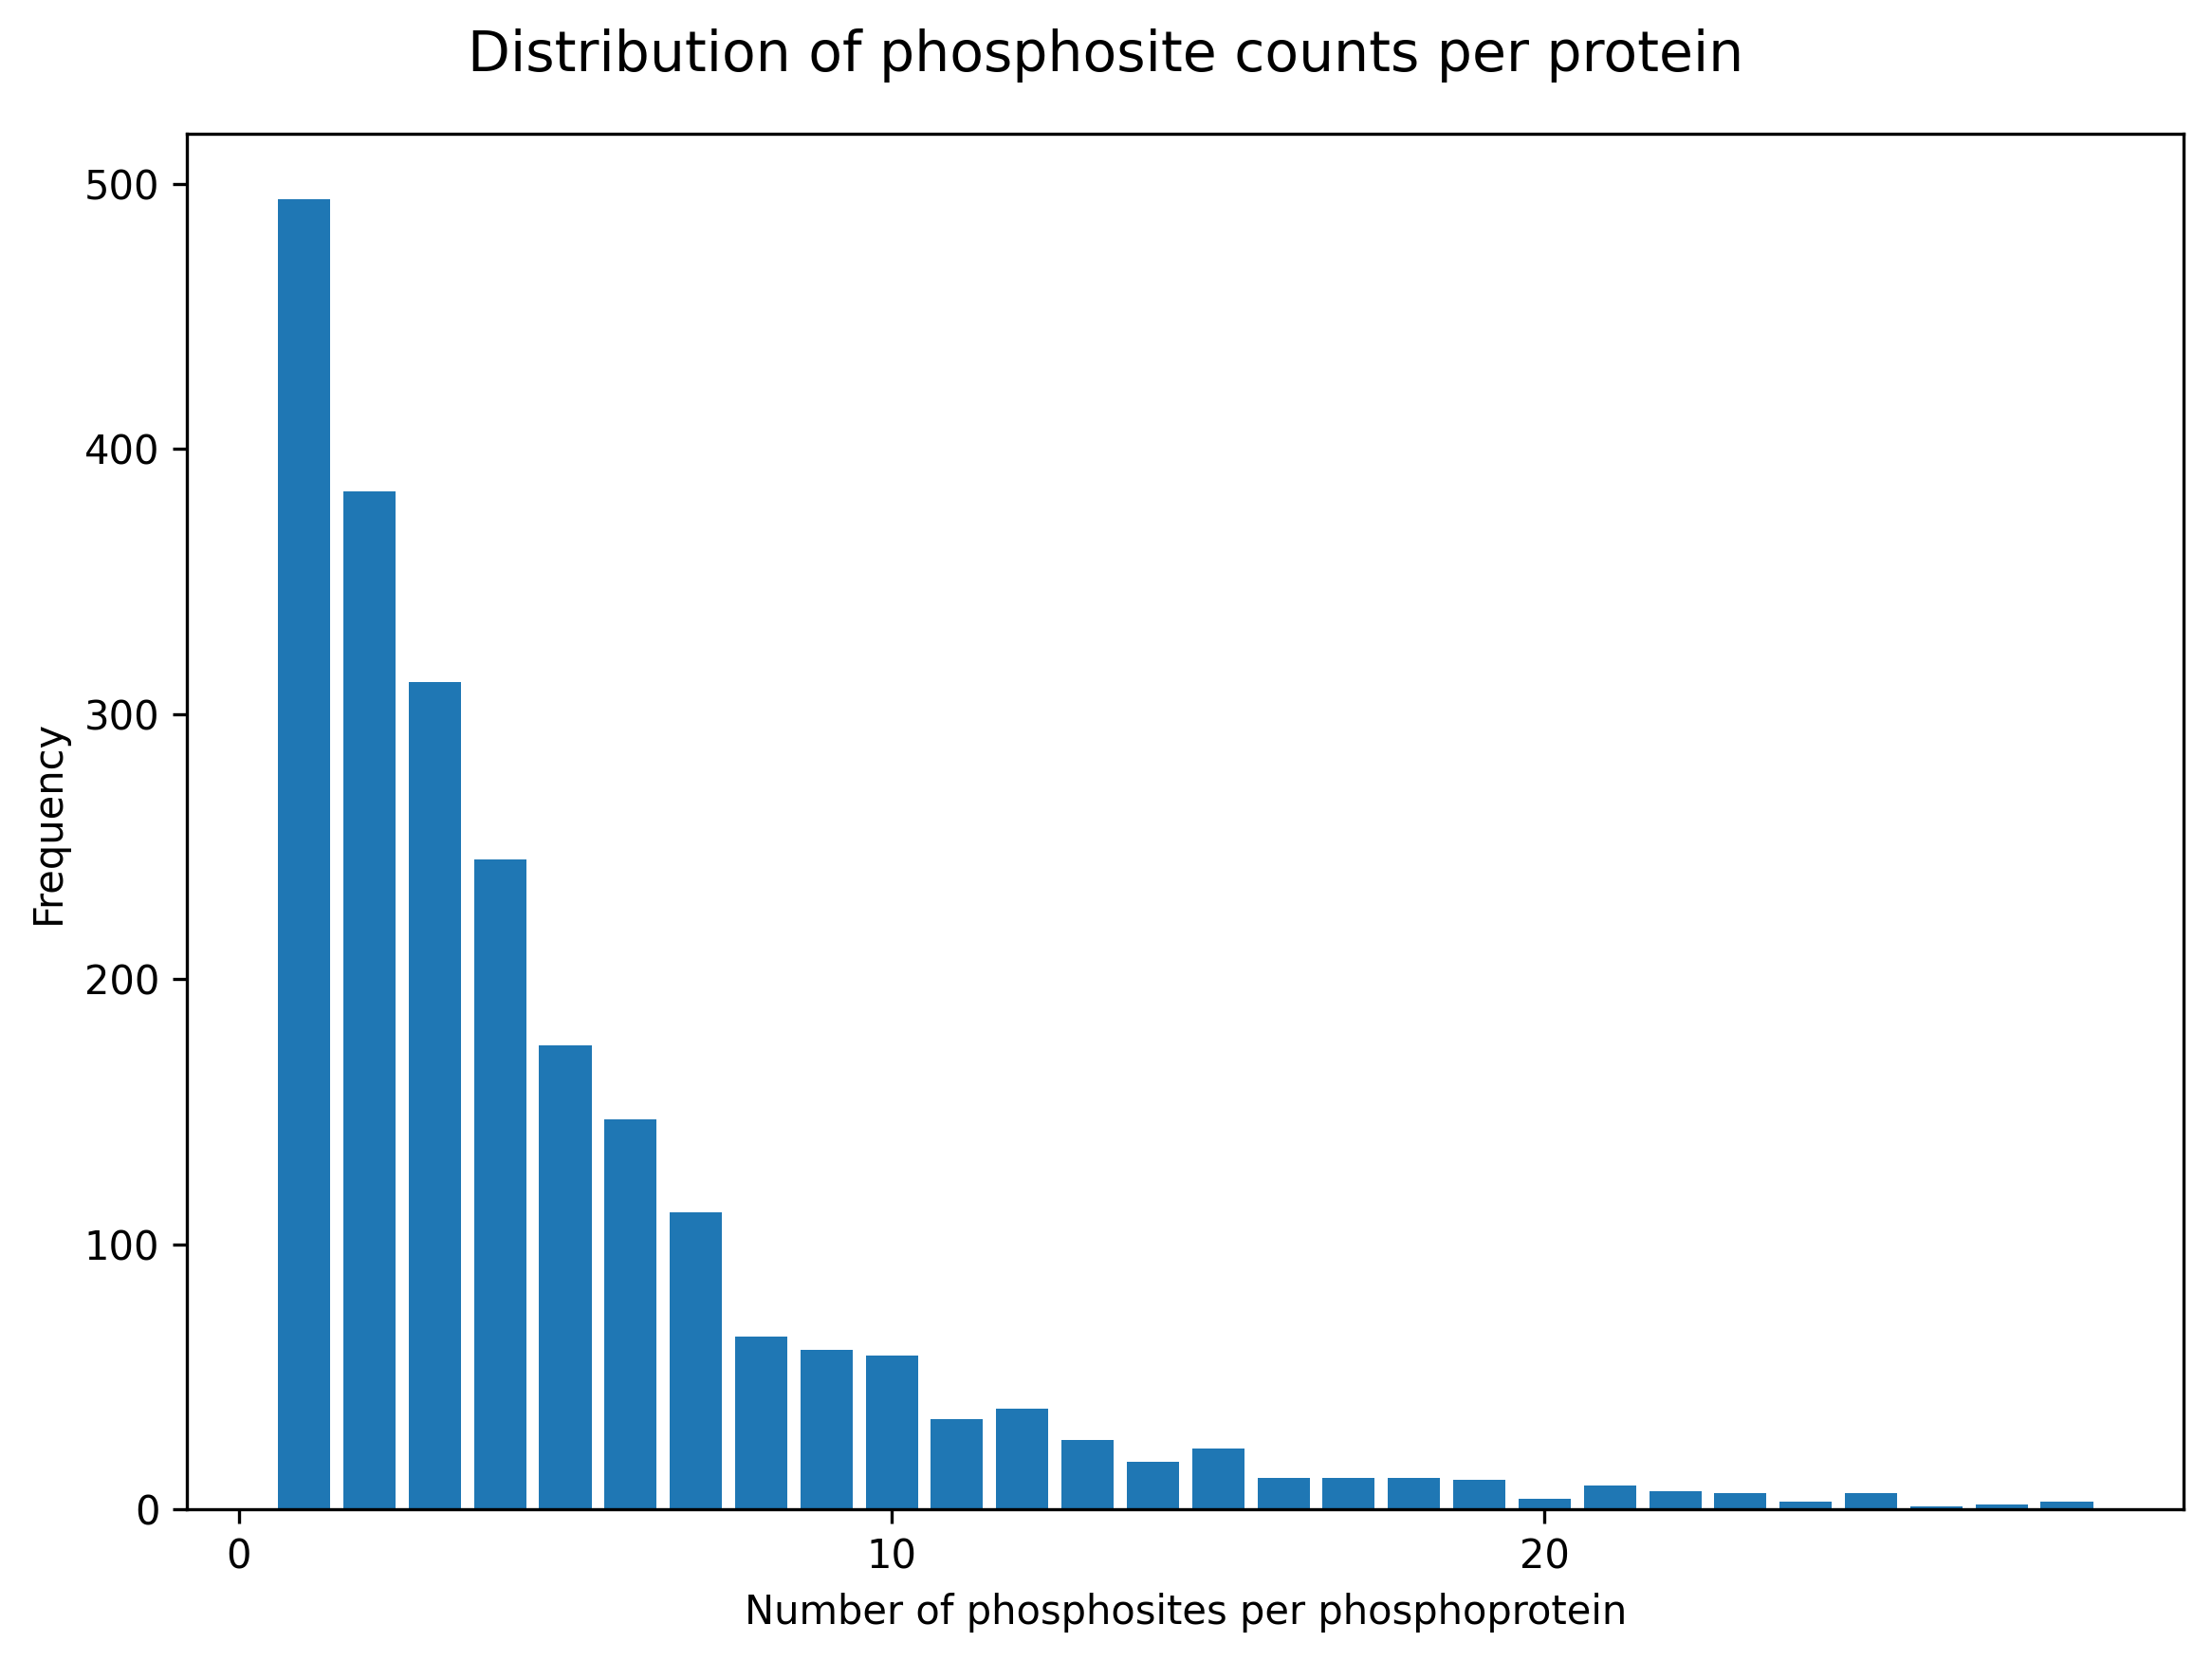

In [25]:
fig = phossite_dist(data4, cutoff=0.01)

## Completeness


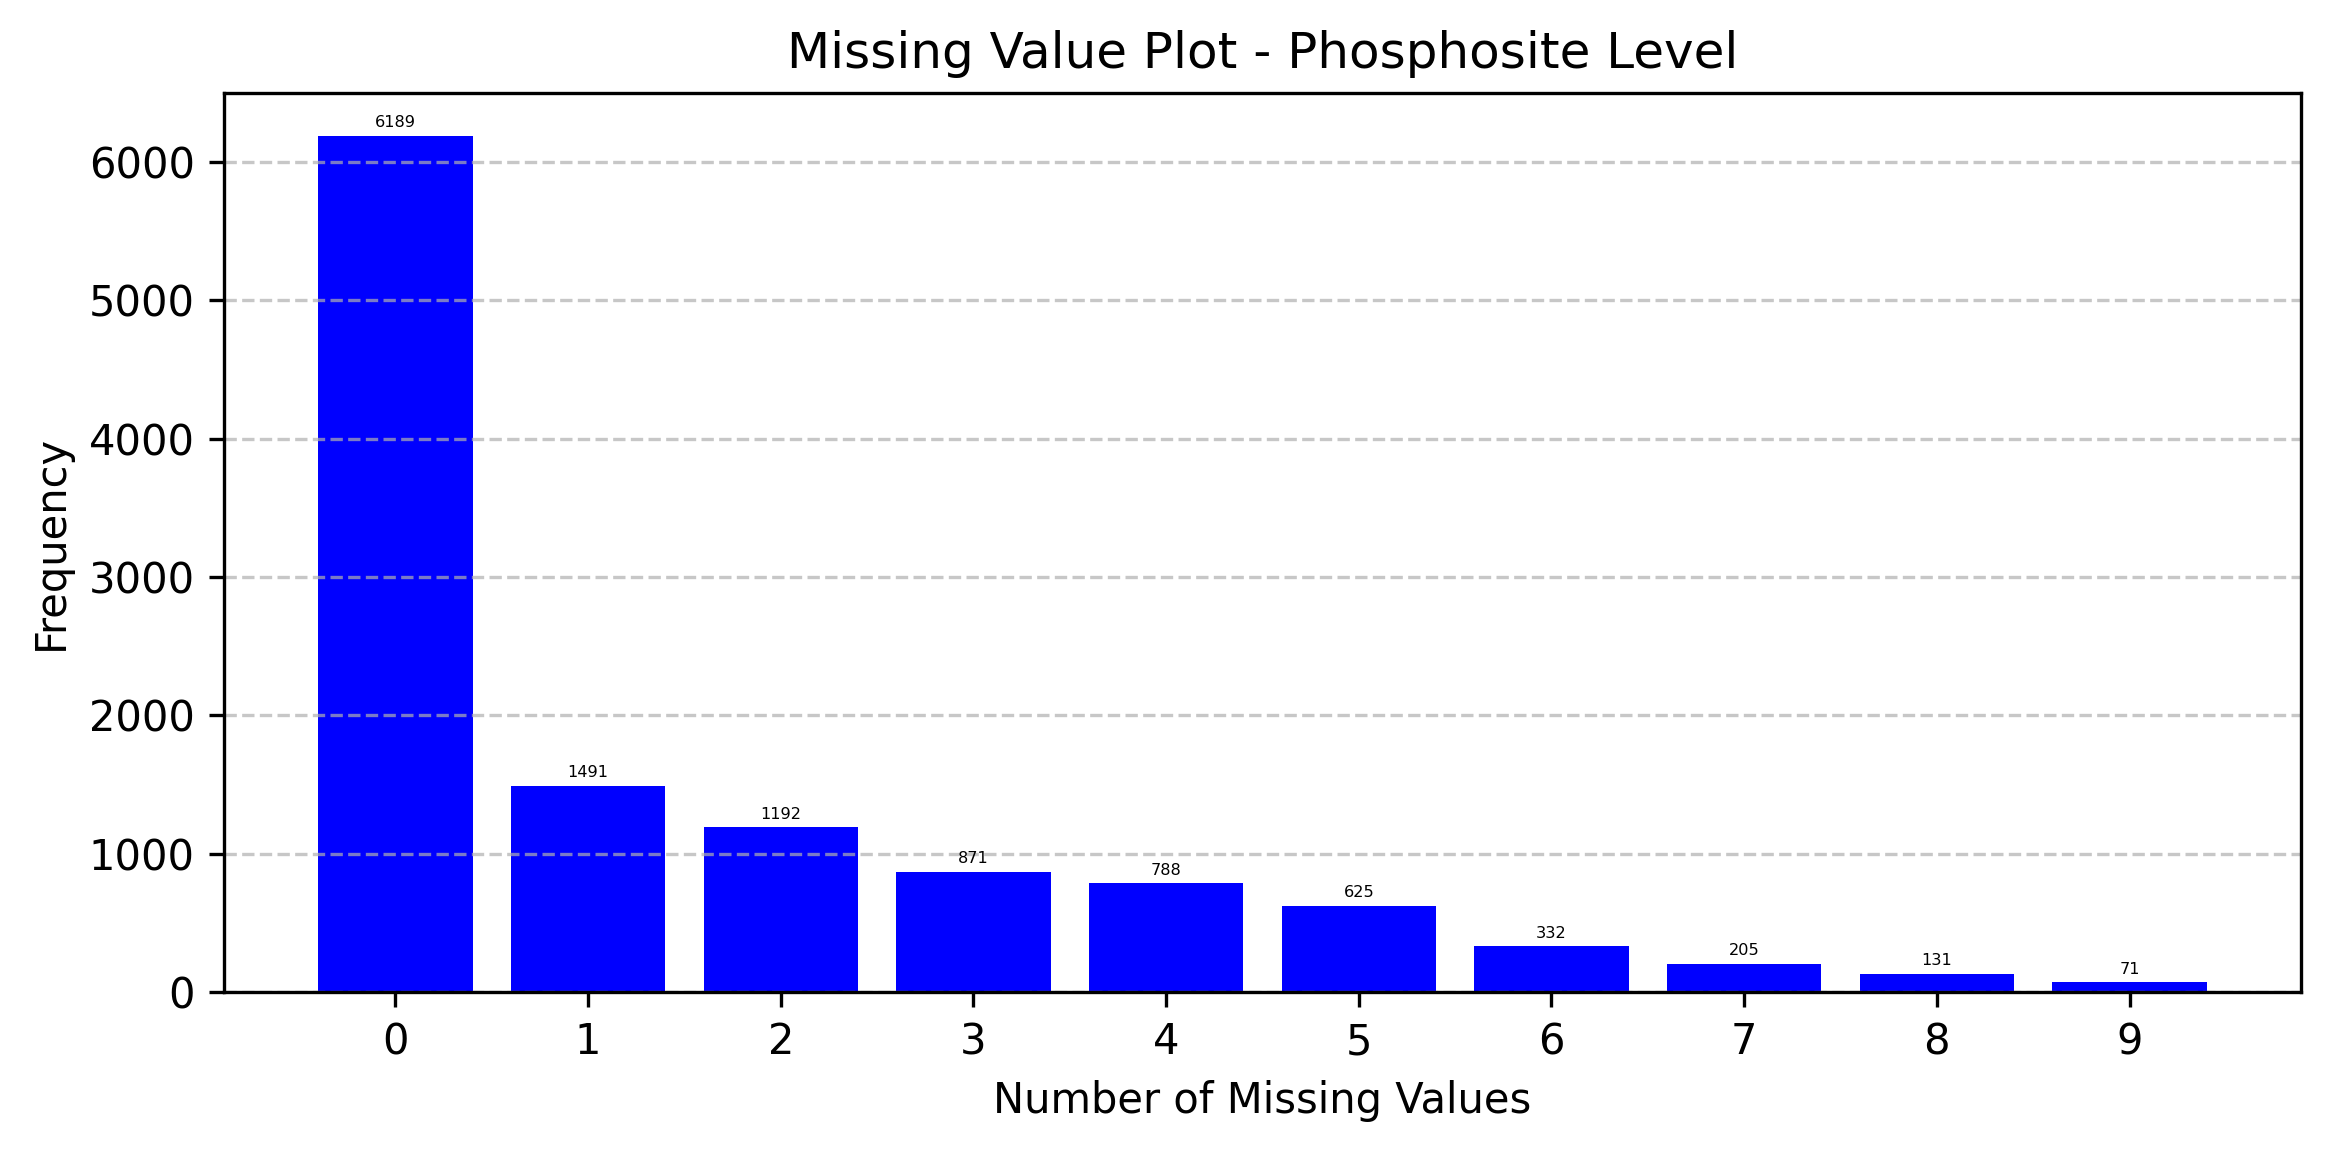

In [26]:
fig = missing_value_plot(data3, meta2)

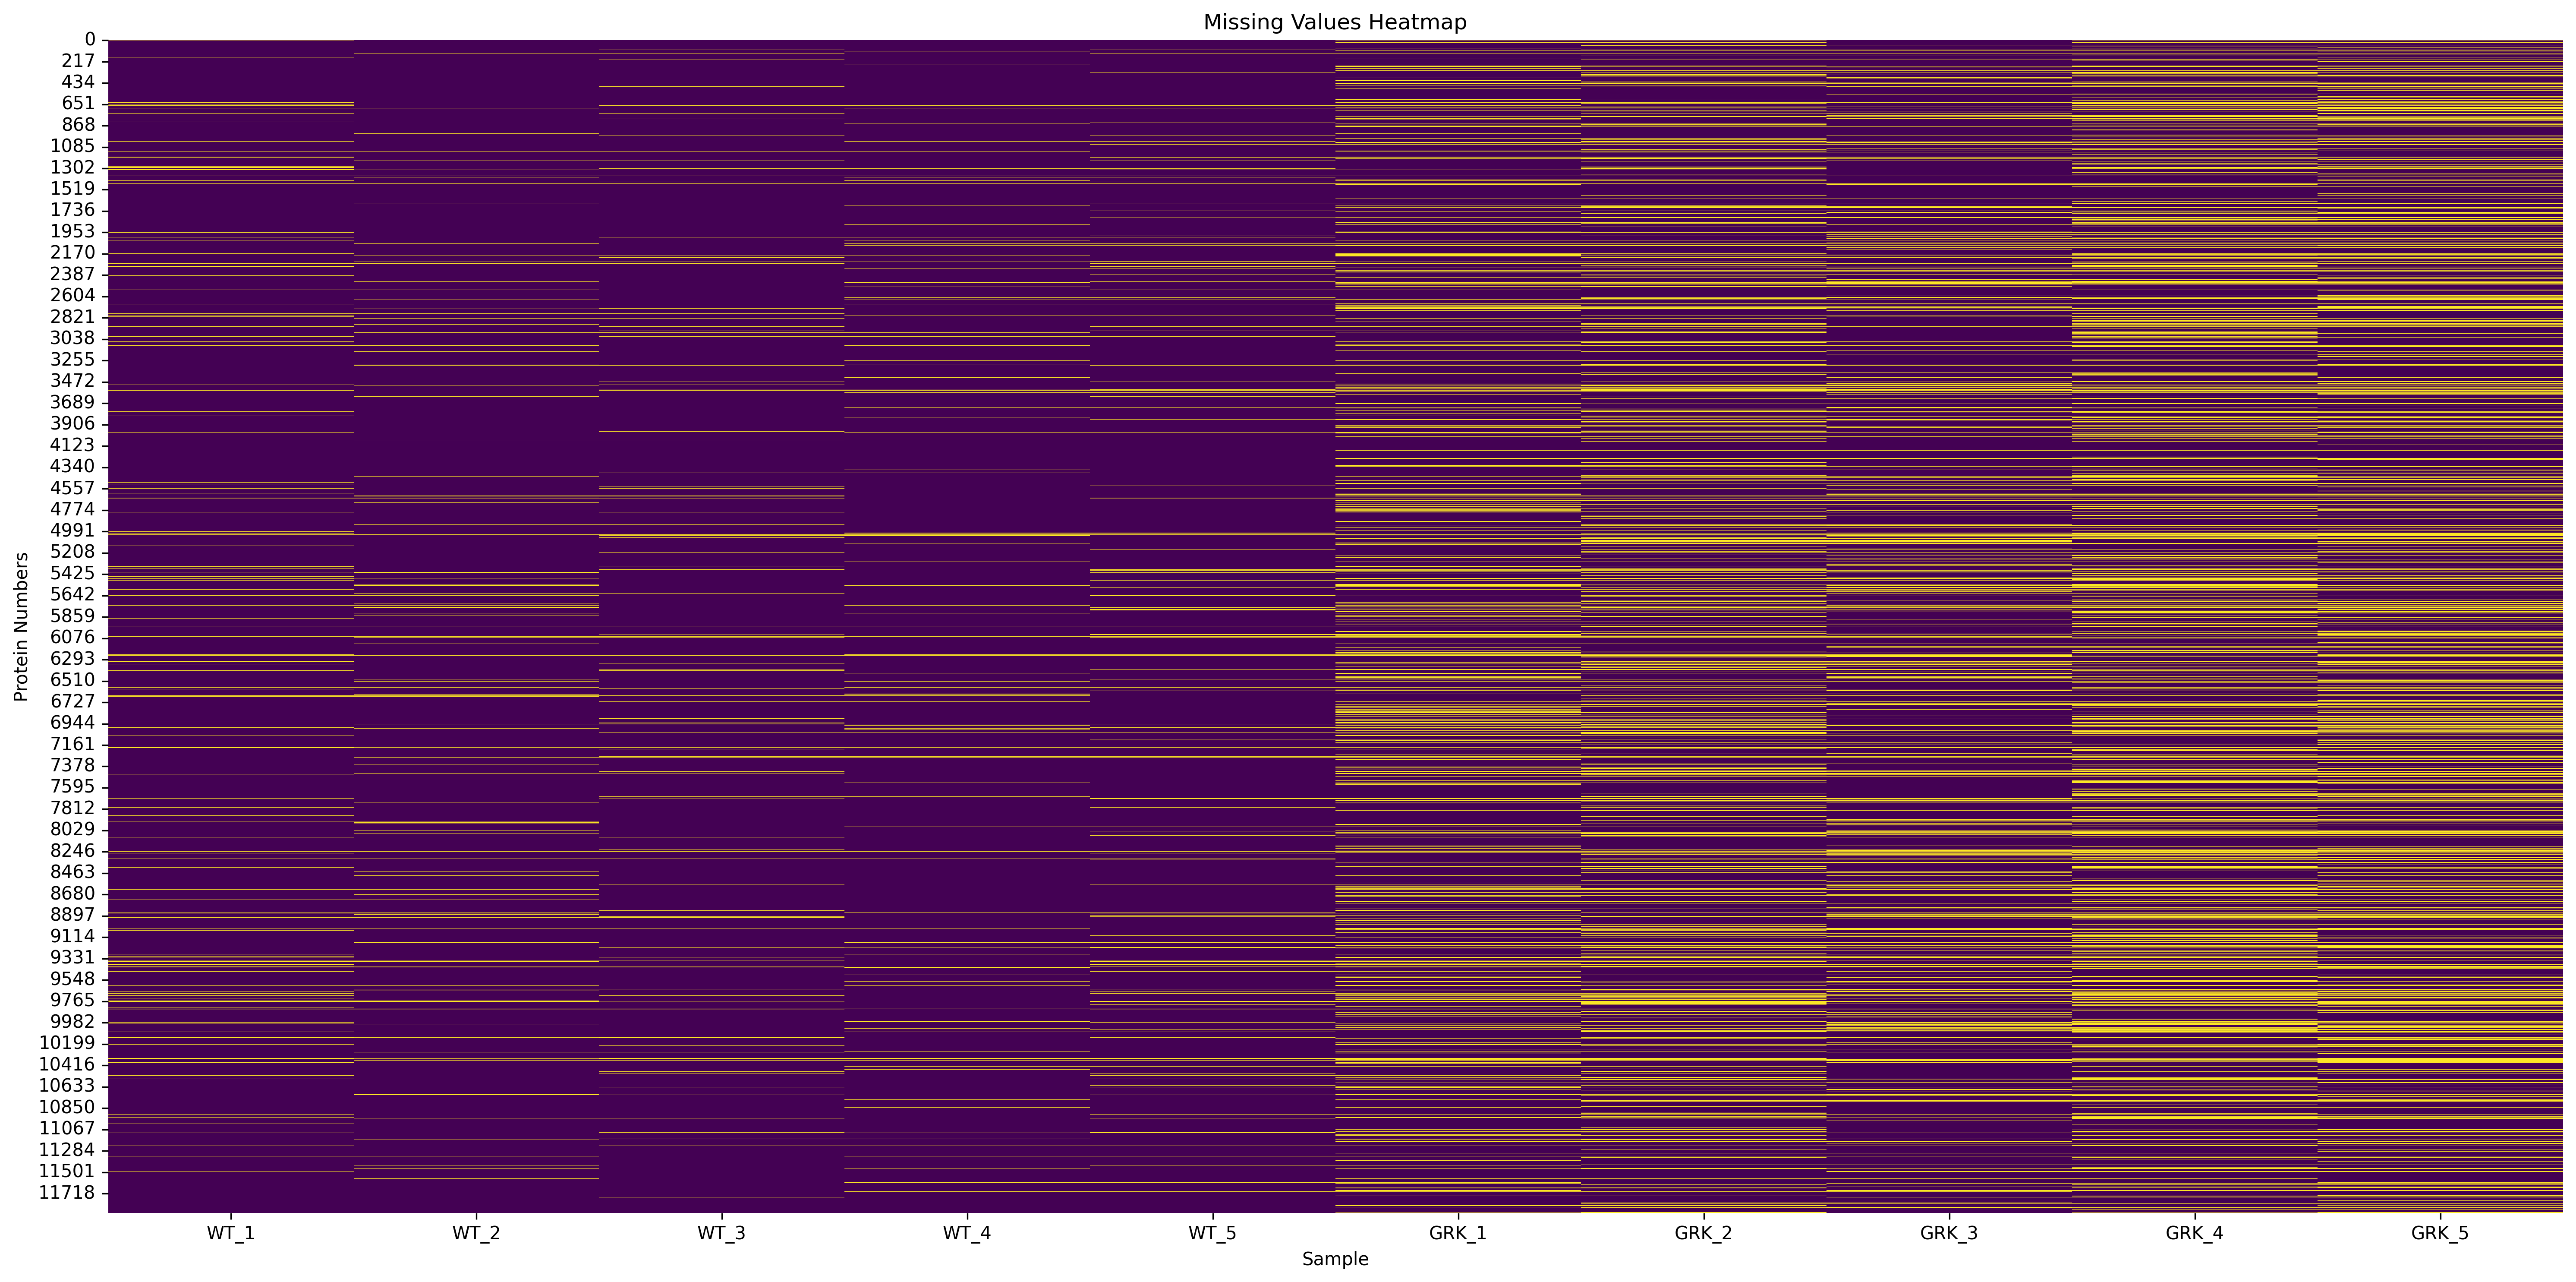

In [27]:
fig = missing_value_heatmap(data3, meta2, id=False)

In [28]:
missing_protein_table(data3, meta2, id=False)

,n_MissingProteinValues,Counts,%_missing_values
0,0,6189,51.938570
1,1,1491,12.512588
2,2,1192,10.003357
3,3,871,7.309500
4,4,788,6.612957
5,5,625,5.245049
6,6,332,2.786170
7,7,205,1.720376
8,8,131,1.099362
9,9,71,0.595838


In [29]:
missing_sample_table(data3, meta2, id=False)

,Sample,Counts,%_missing_values
0,WT_1,707,5.933199
1,WT_2,628,5.270225
2,WT_3,554,4.649211
3,WT_4,537,4.506546
4,WT_5,729,6.117825
5,GRK_1,2369,19.880832
6,GRK_2,2725,22.868412
7,GRK_3,2414,20.258476
8,GRK_4,3714,31.168177
9,GRK_5,3712,31.151393


## QC Pipeline


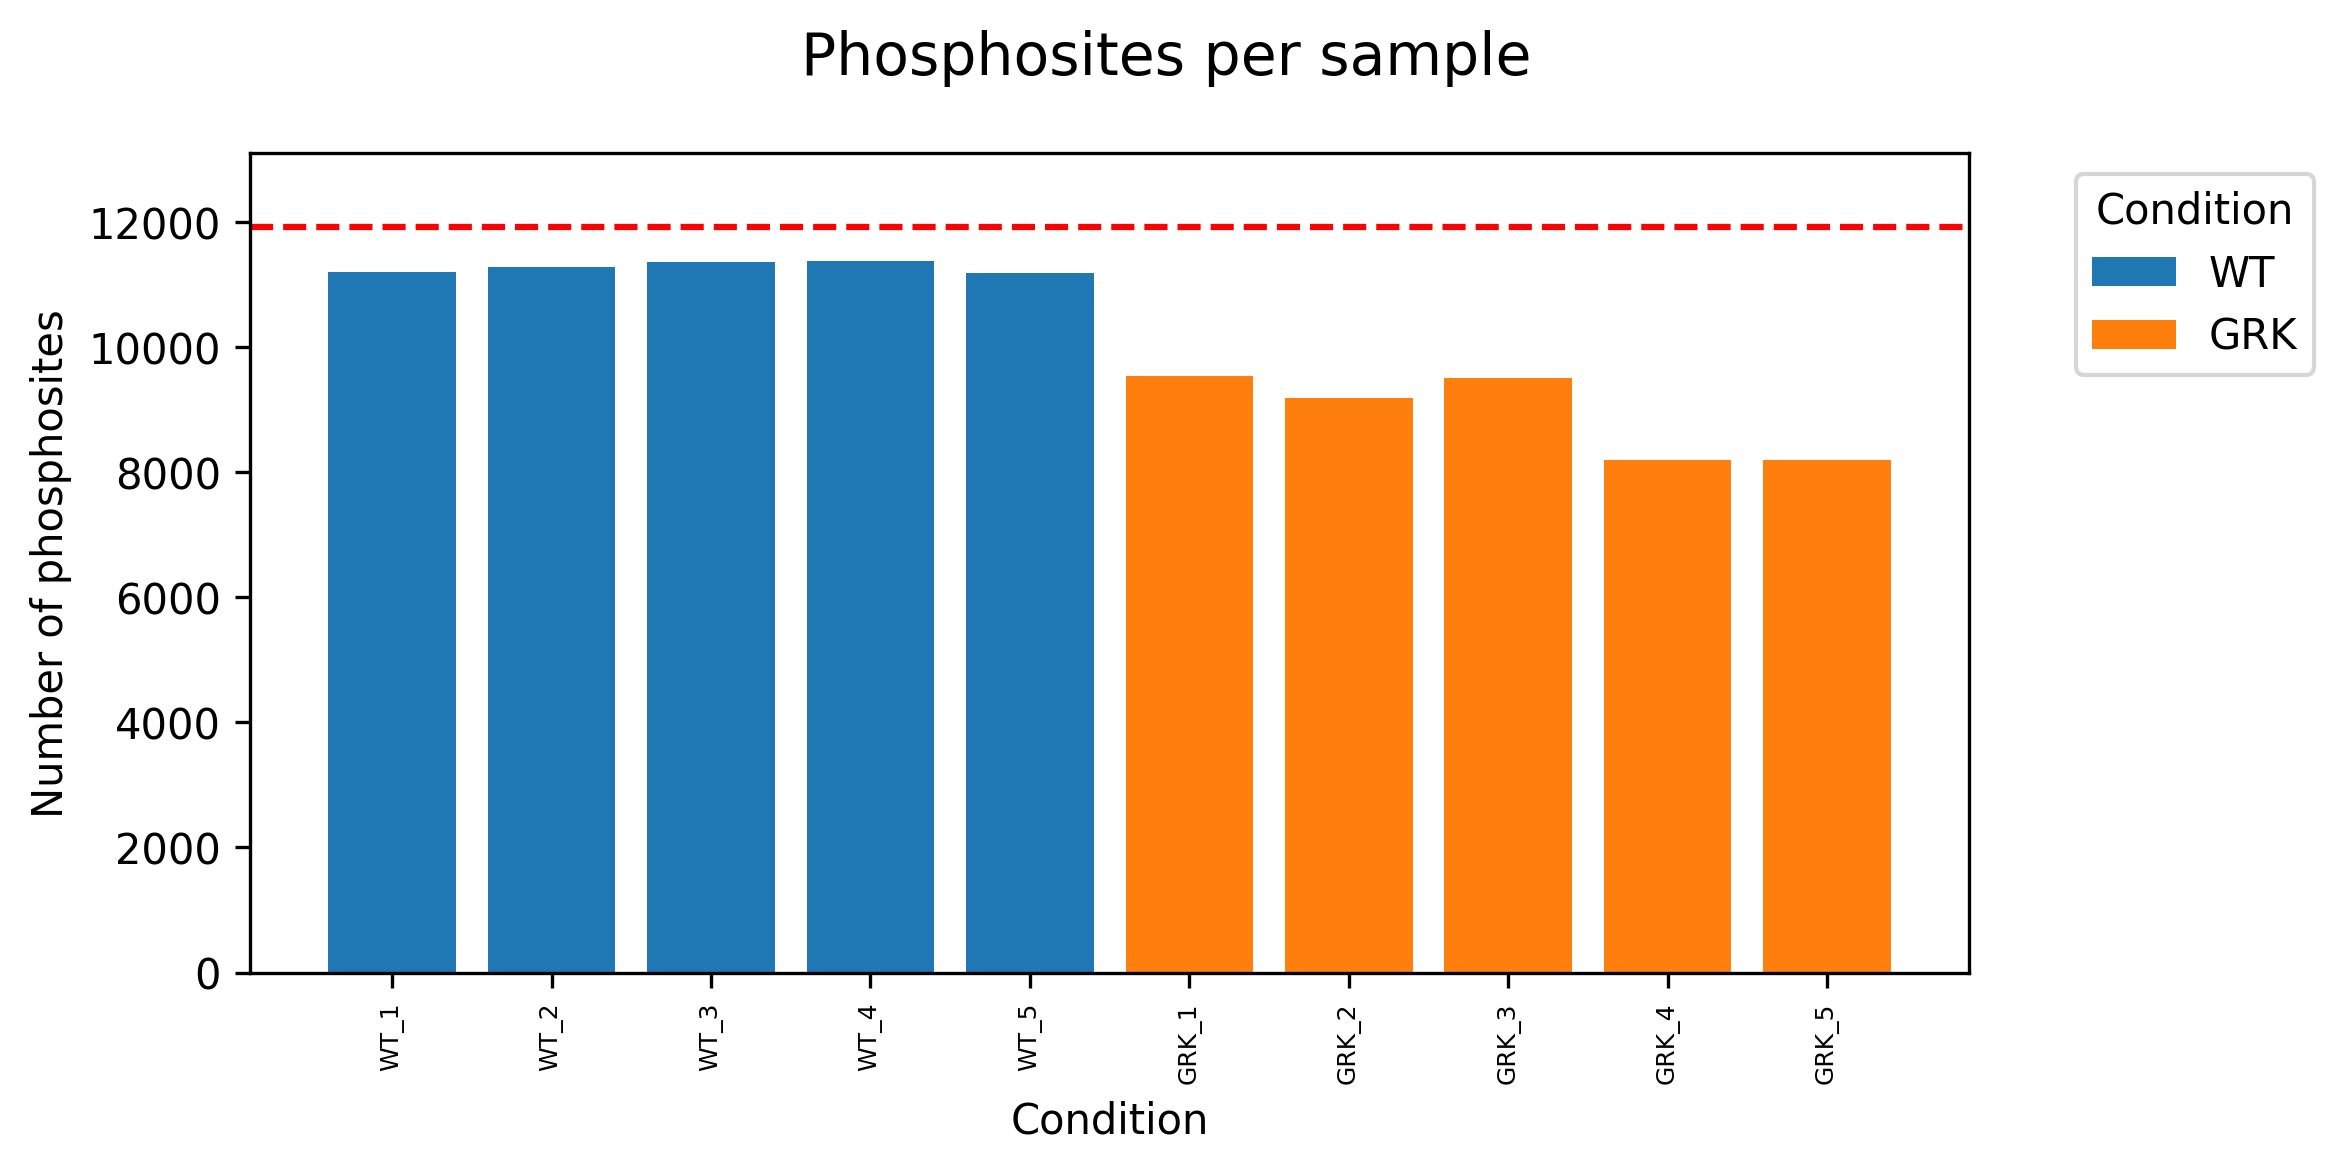

In [30]:
fig = coverage_plot(data3, meta2, id=False)

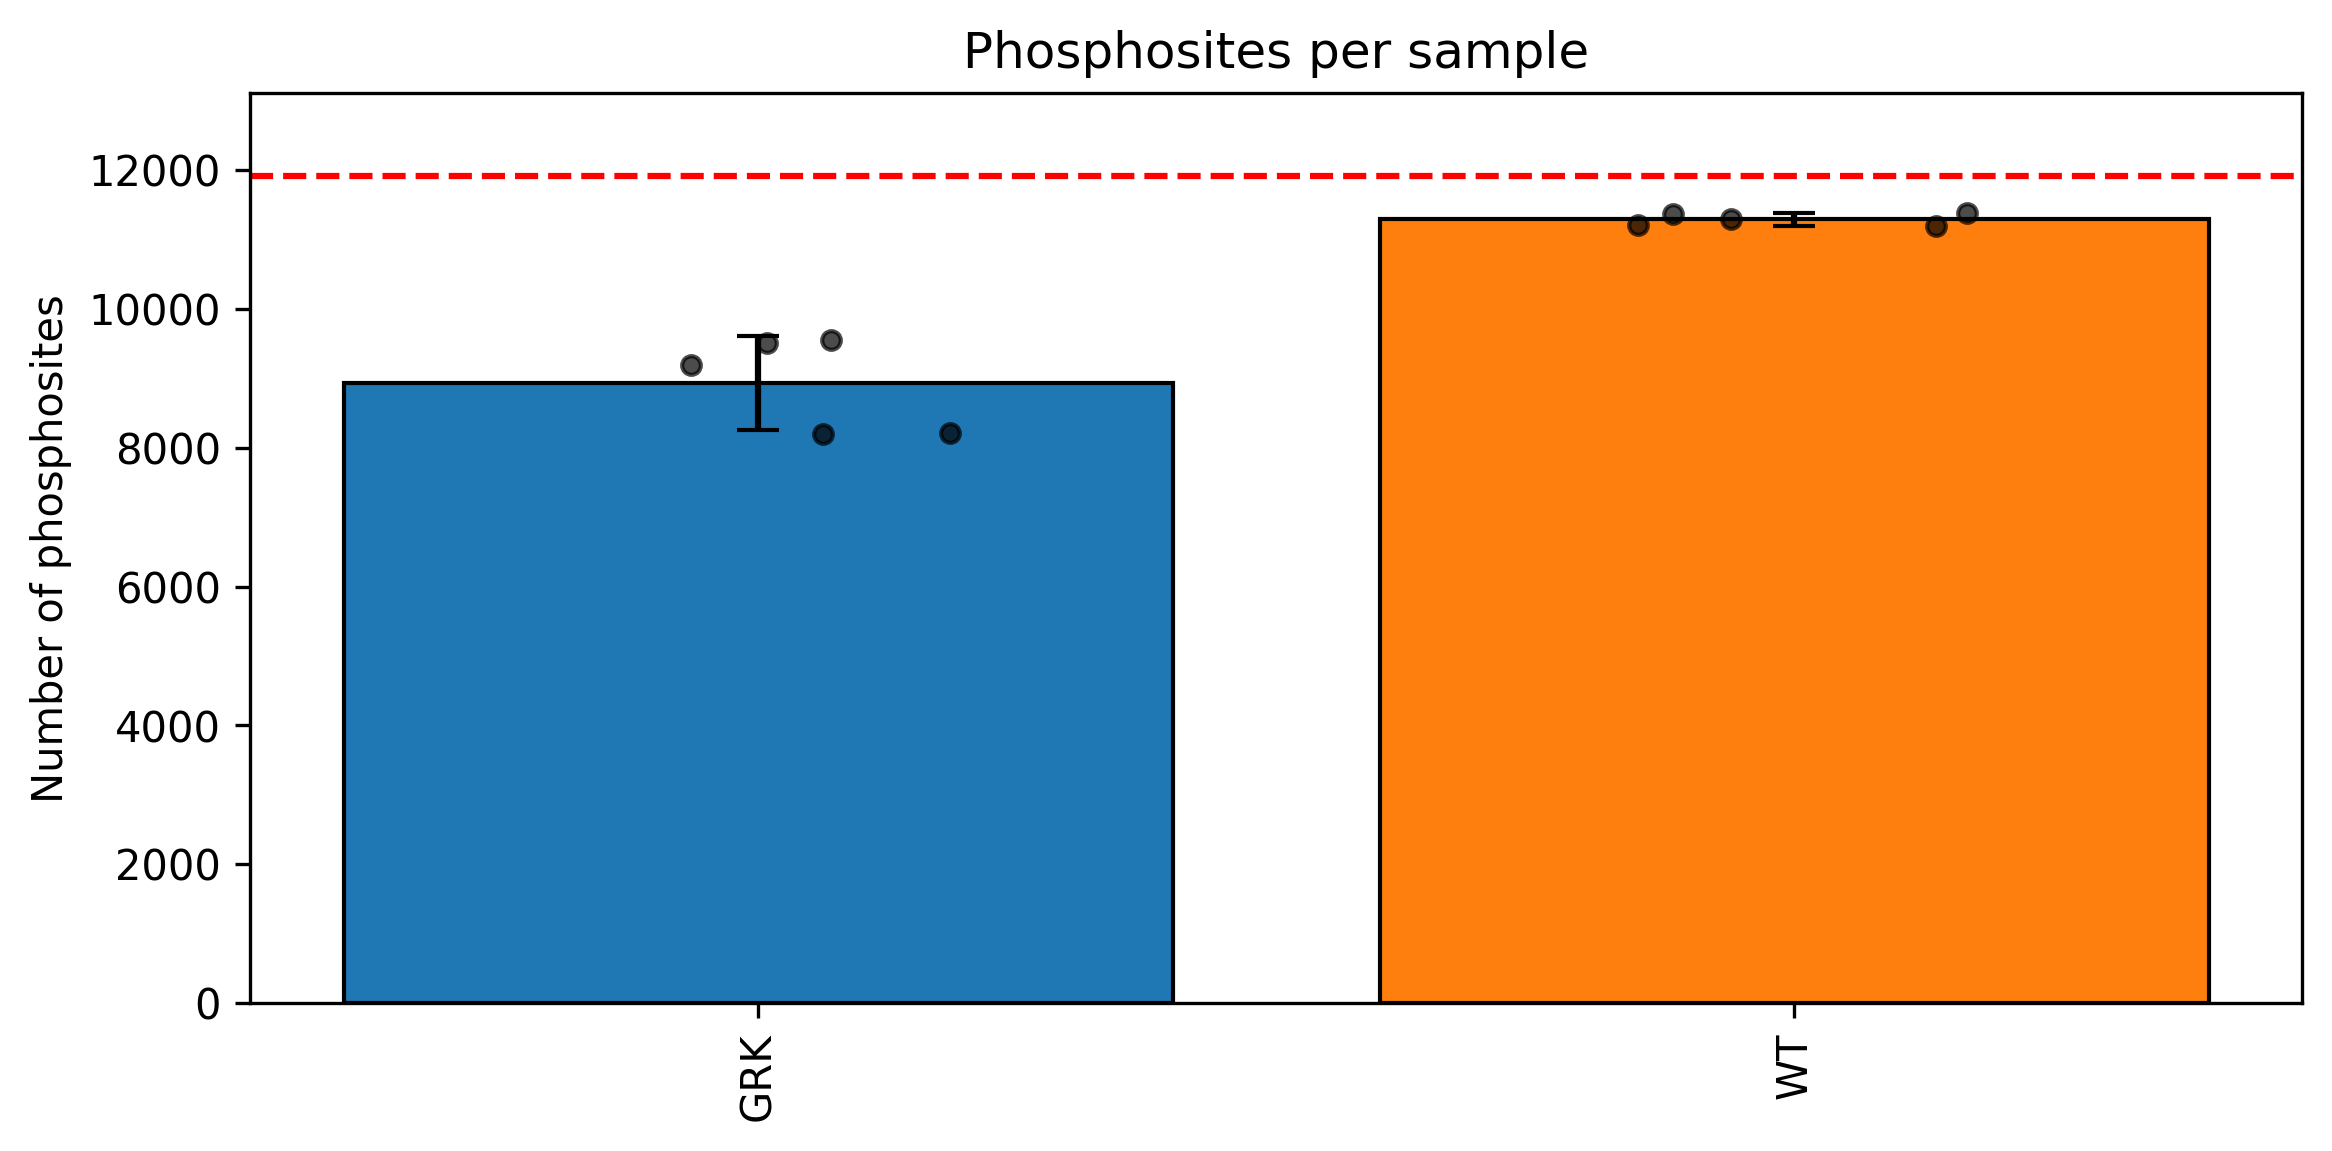

In [31]:
fig = coverage_plot_summary(data3, meta2)

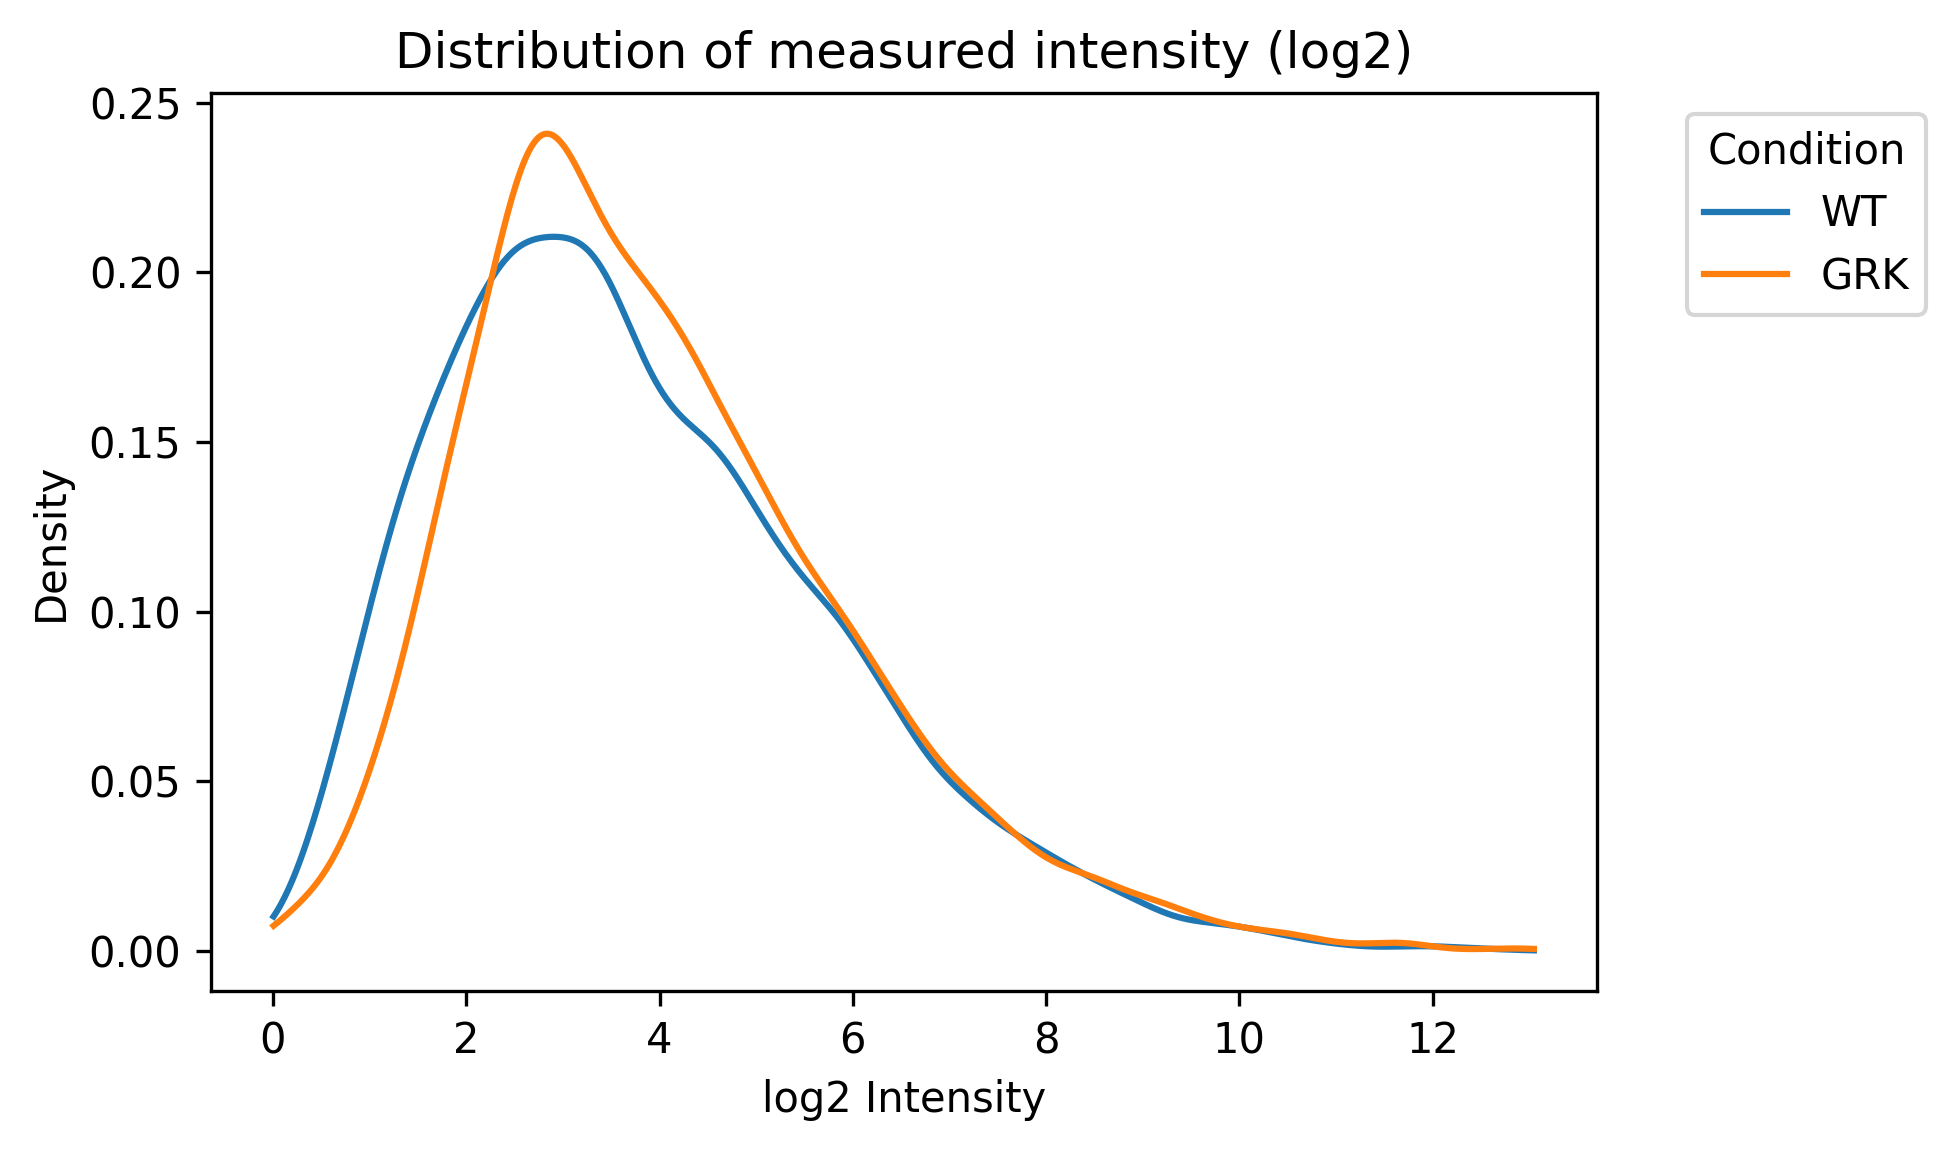

In [32]:
fig = histo_int(data3, meta2)

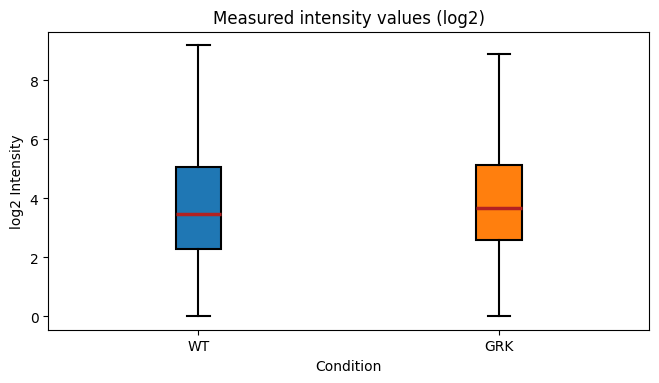

In [33]:
fig = boxplot_int(data3, meta2)

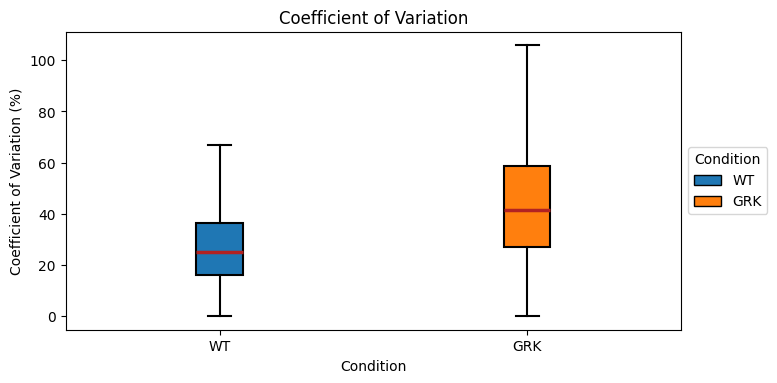

In [34]:
fig = cov_plot(org_data3, meta2)

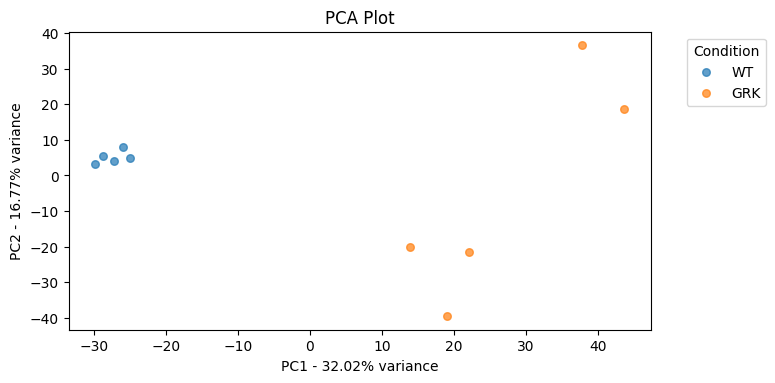

In [35]:
fig = pca_plot(data3, meta2)

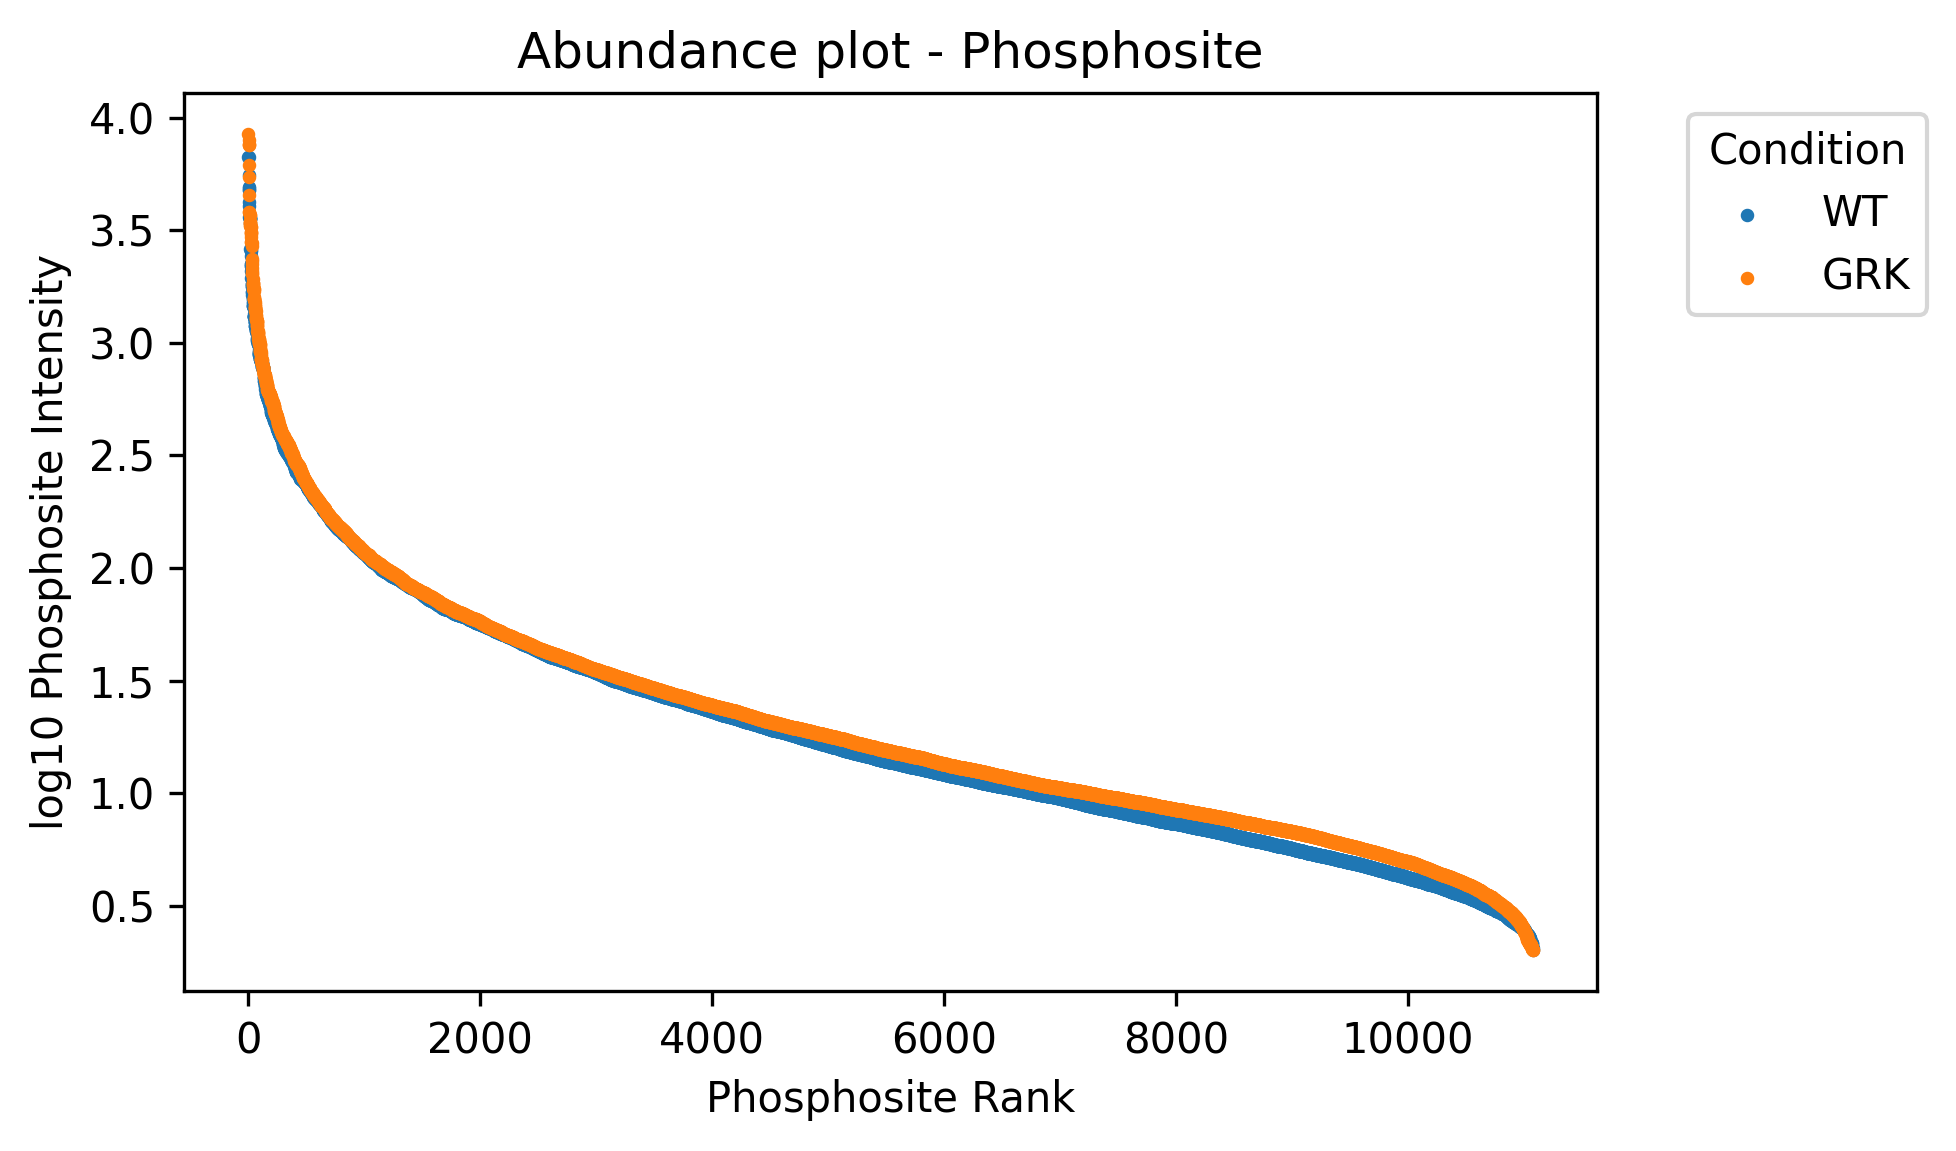

In [36]:
fig = abundance_plot(org_data3, meta2, workflow="Phosphosite")

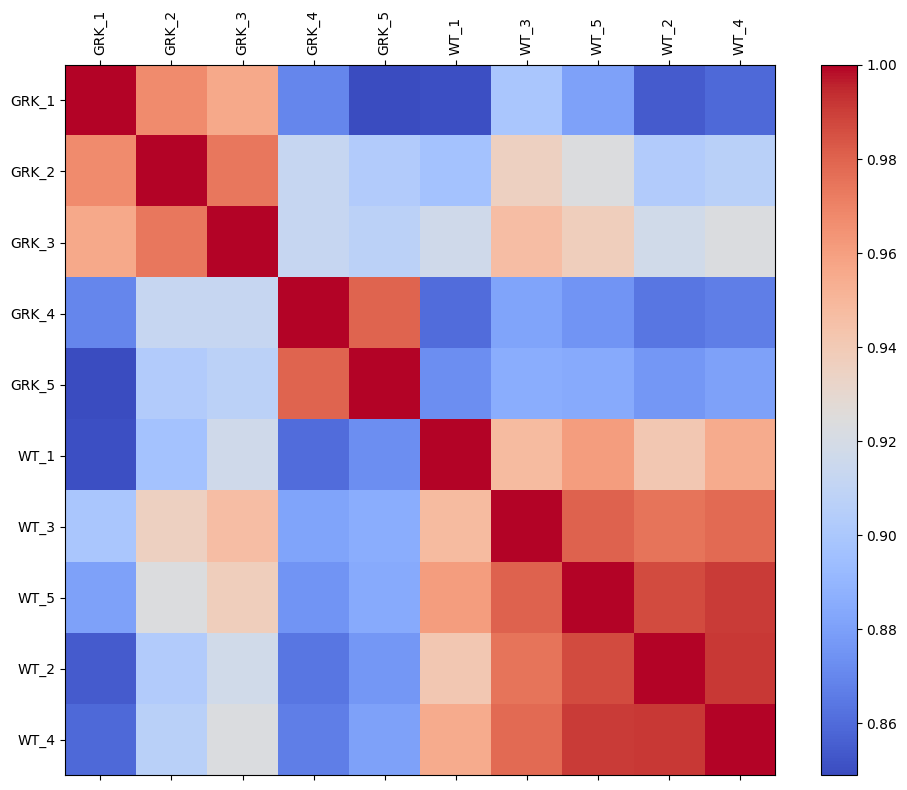

In [37]:
fig = corr_plot(org_data3, meta2, id=False)

## Volcano Plot


In [38]:
volcano_data = volcano_data_f(data3, meta2, "WT", "GRK", workflow="Phosphosite")
volcano_data.head()

,PTM_Collapse_key,log2FC,pval,adj_pval,significance,neg_log10_adj_pval
0,A0A590UK10~ARHGEF18_S1035_M1,-0.277869,0.457396,0.681601,Not significant,0.166470
1,A0A590UK10~ARHGEF18_S1037_M1,-0.362651,0.439661,0.667106,Not significant,0.175805
2,A0JLT2~MED19_S226_M1,0.502388,0.033772,0.162974,Not significant,0.787881
3,A0JNW5~BLTP3B_S414_M1,-1.331050,0.296512,0.535248,Not significant,0.271445
4,A0JNW5~BLTP3B_S418_M1,0.385220,0.607367,0.782341,Not significant,0.106604


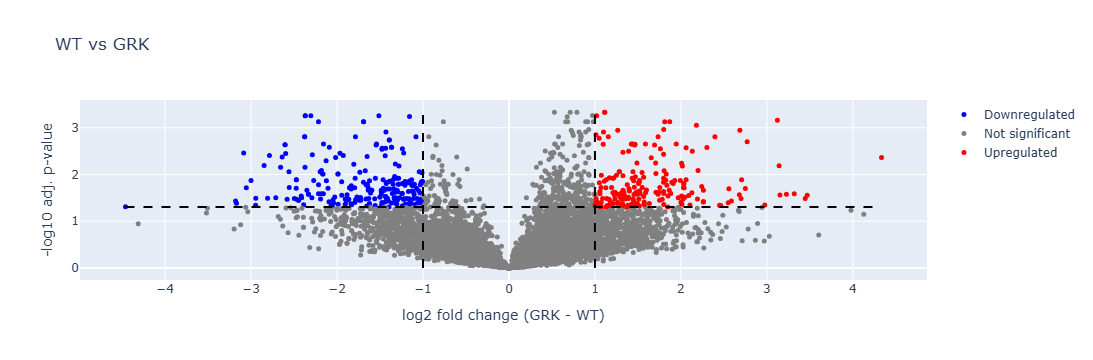

In [39]:
fig = volcano_plot(volcano_data, "WT", "GRK")
fig.show()

## Single Protein


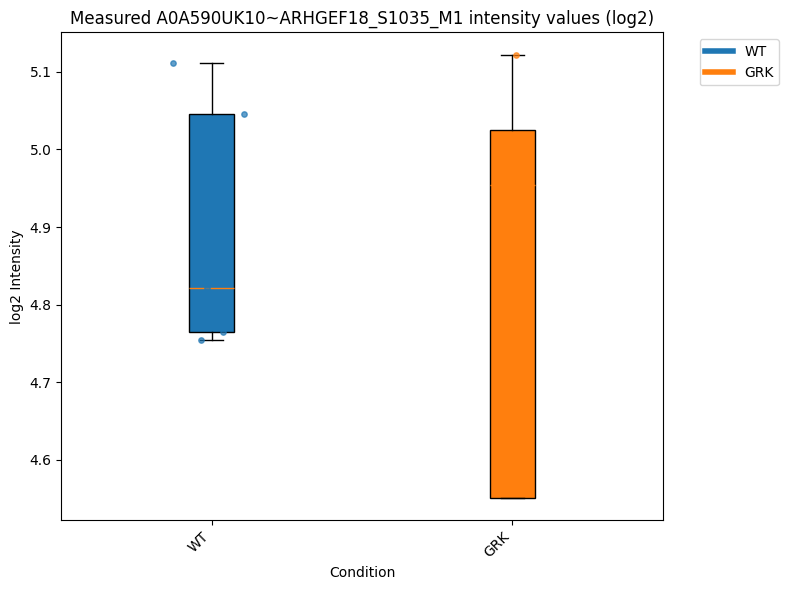

In [40]:
fig = boxplot_int_single_prot(data3_by_site, meta2, phosphosite_id, dots=True)

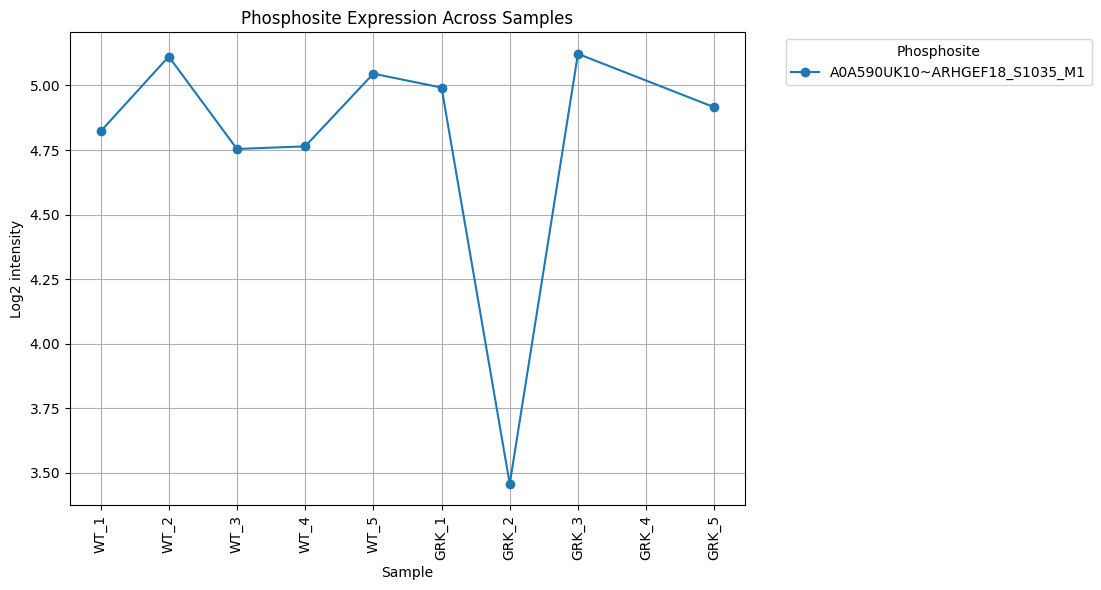

In [41]:
fig = compare_prot_line(data3, meta2, conditions, [phosphosite_id], workflow="Phosphosite", id=False)

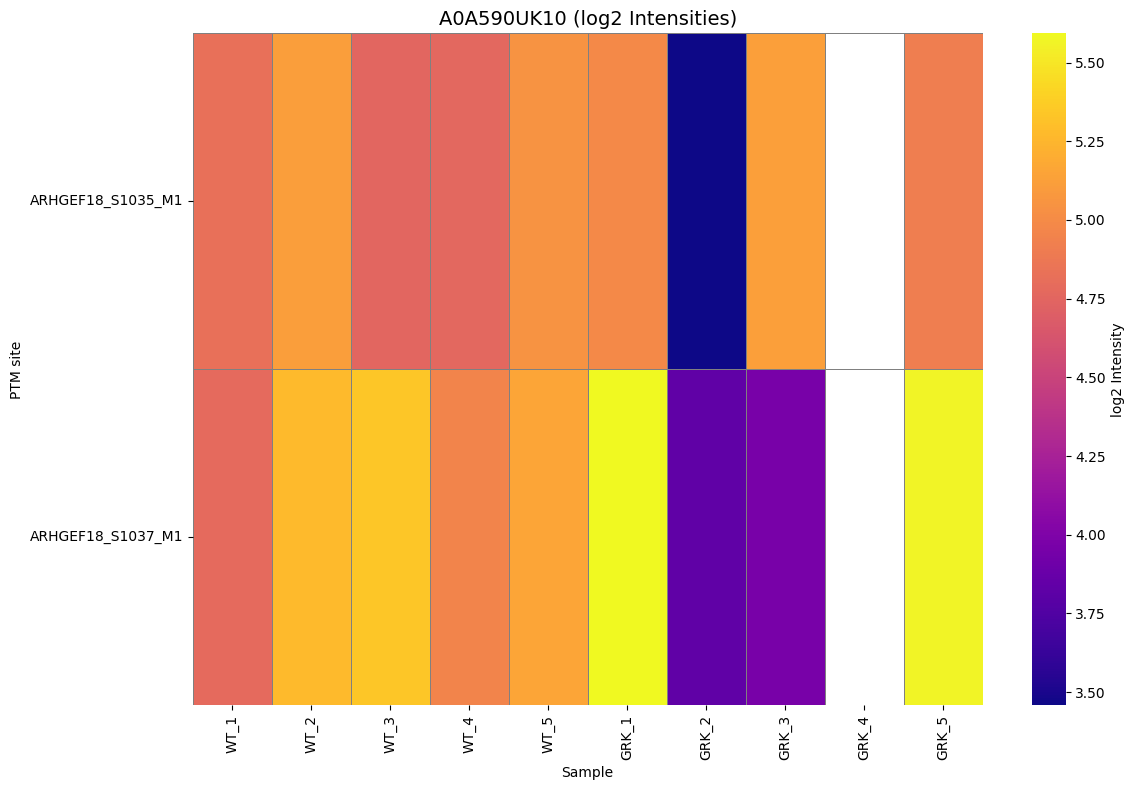

In [42]:
fig = phossite_on_prot_regulation(data3, meta2, phospho_protein_id, conditions=conditions, id=False)

## Comparison


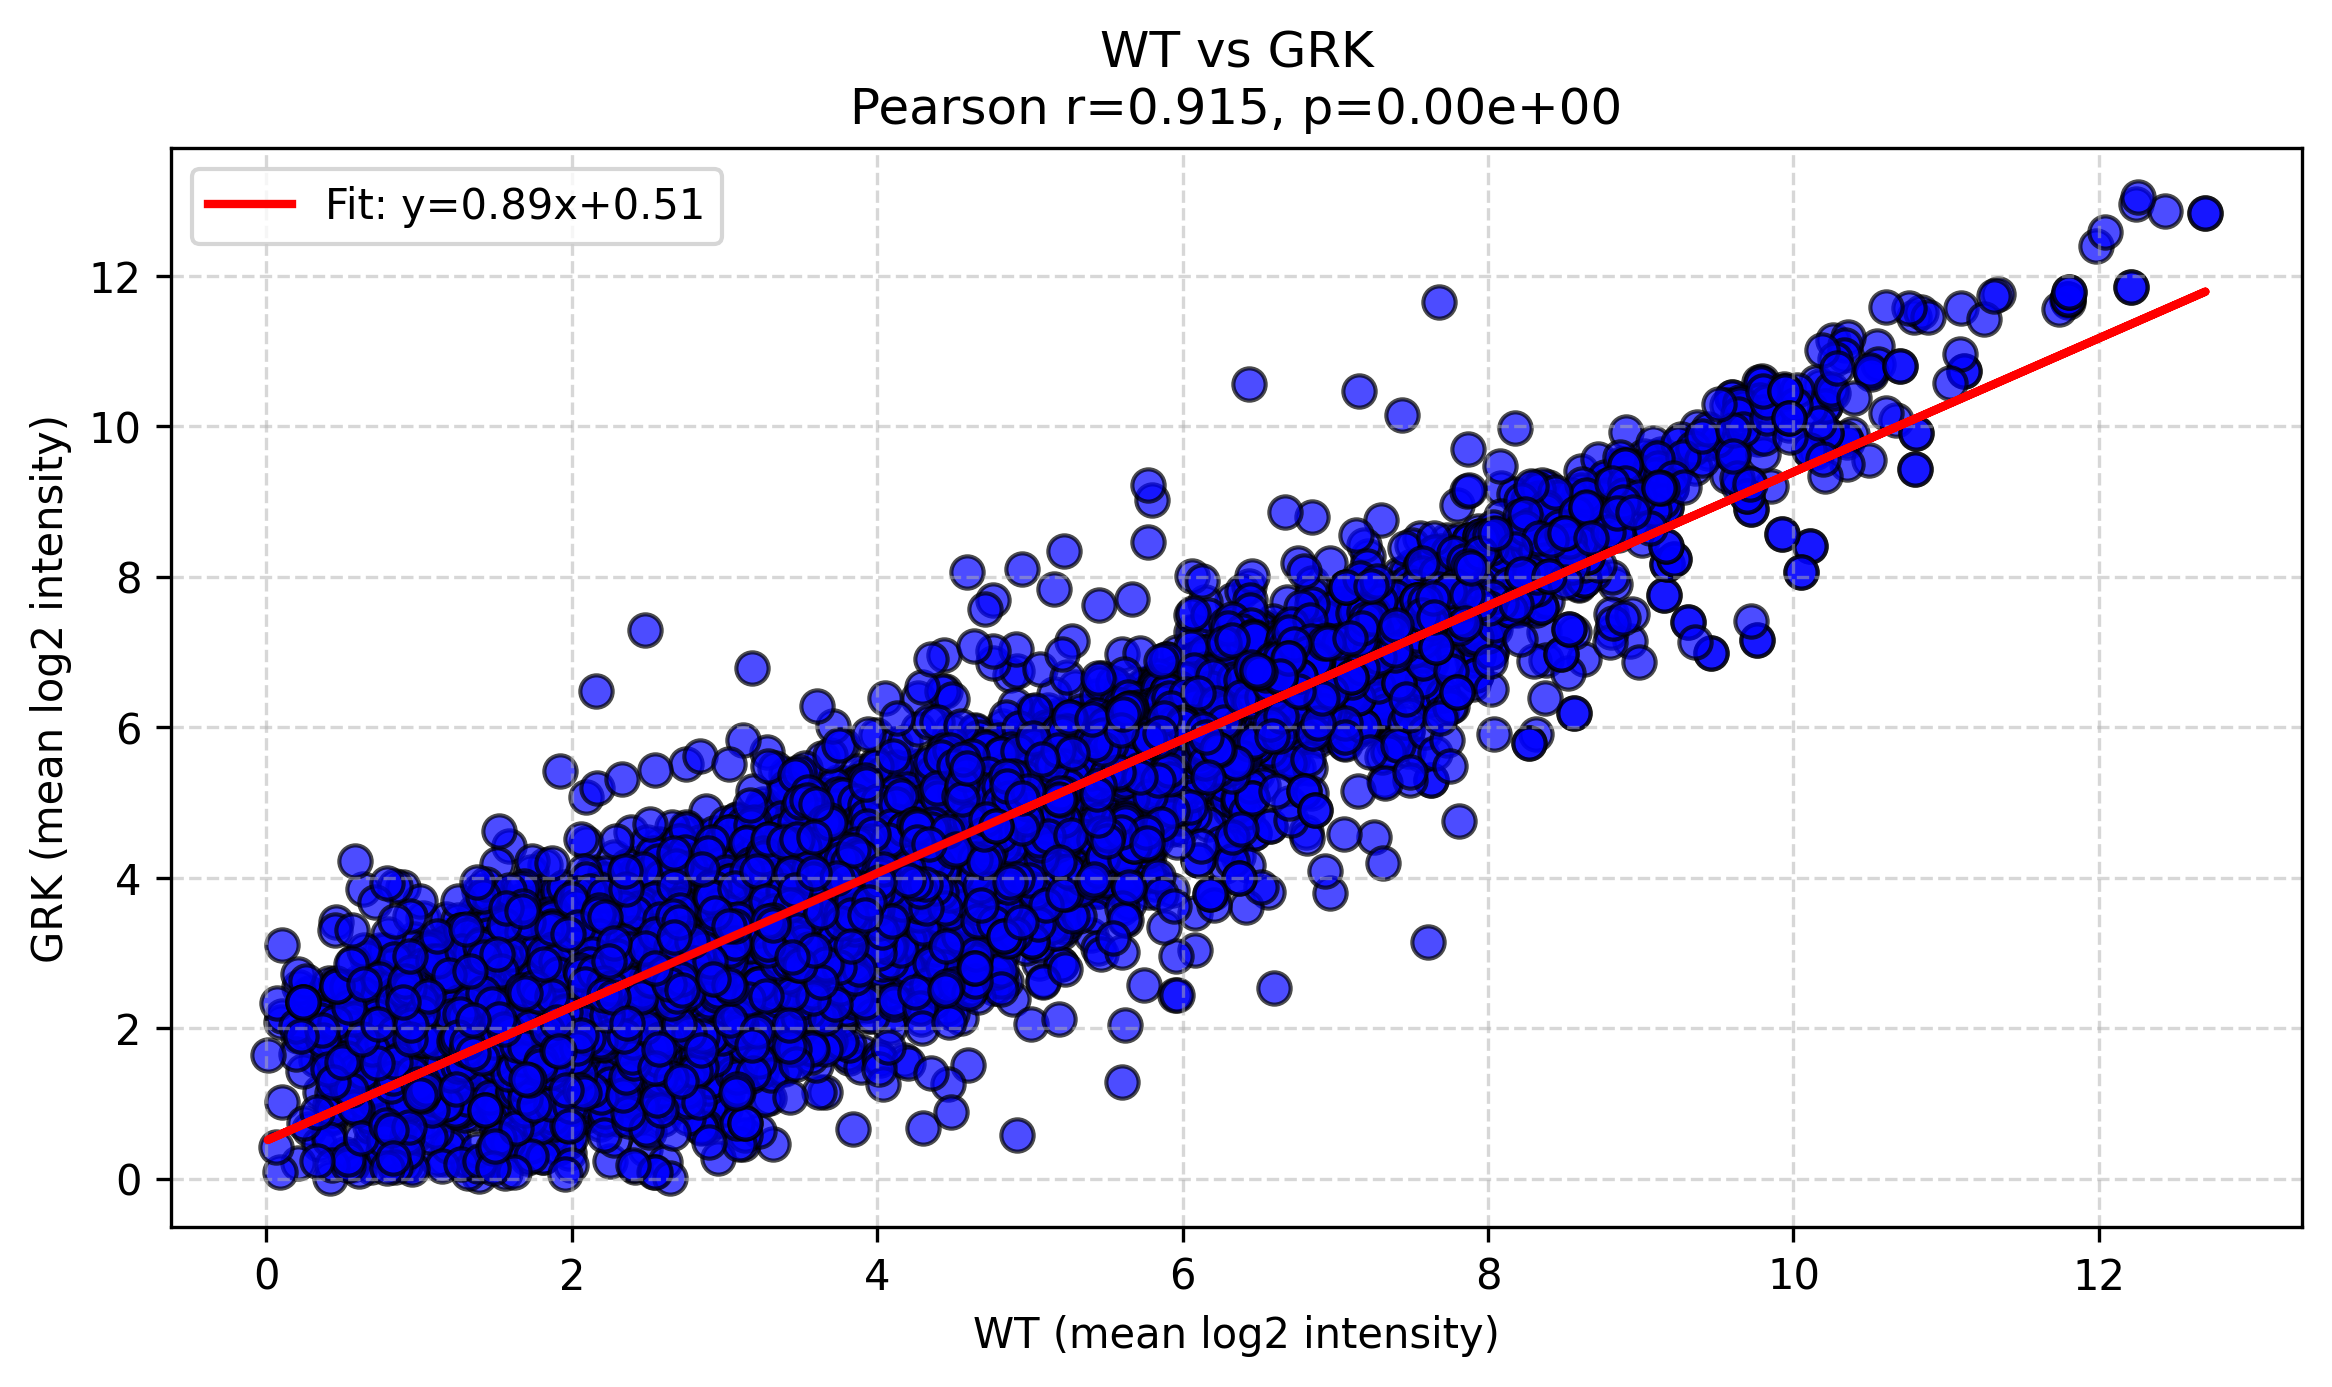

In [43]:
fig = correlation_xy_intensity(data3, meta2, "WT", "GRK")

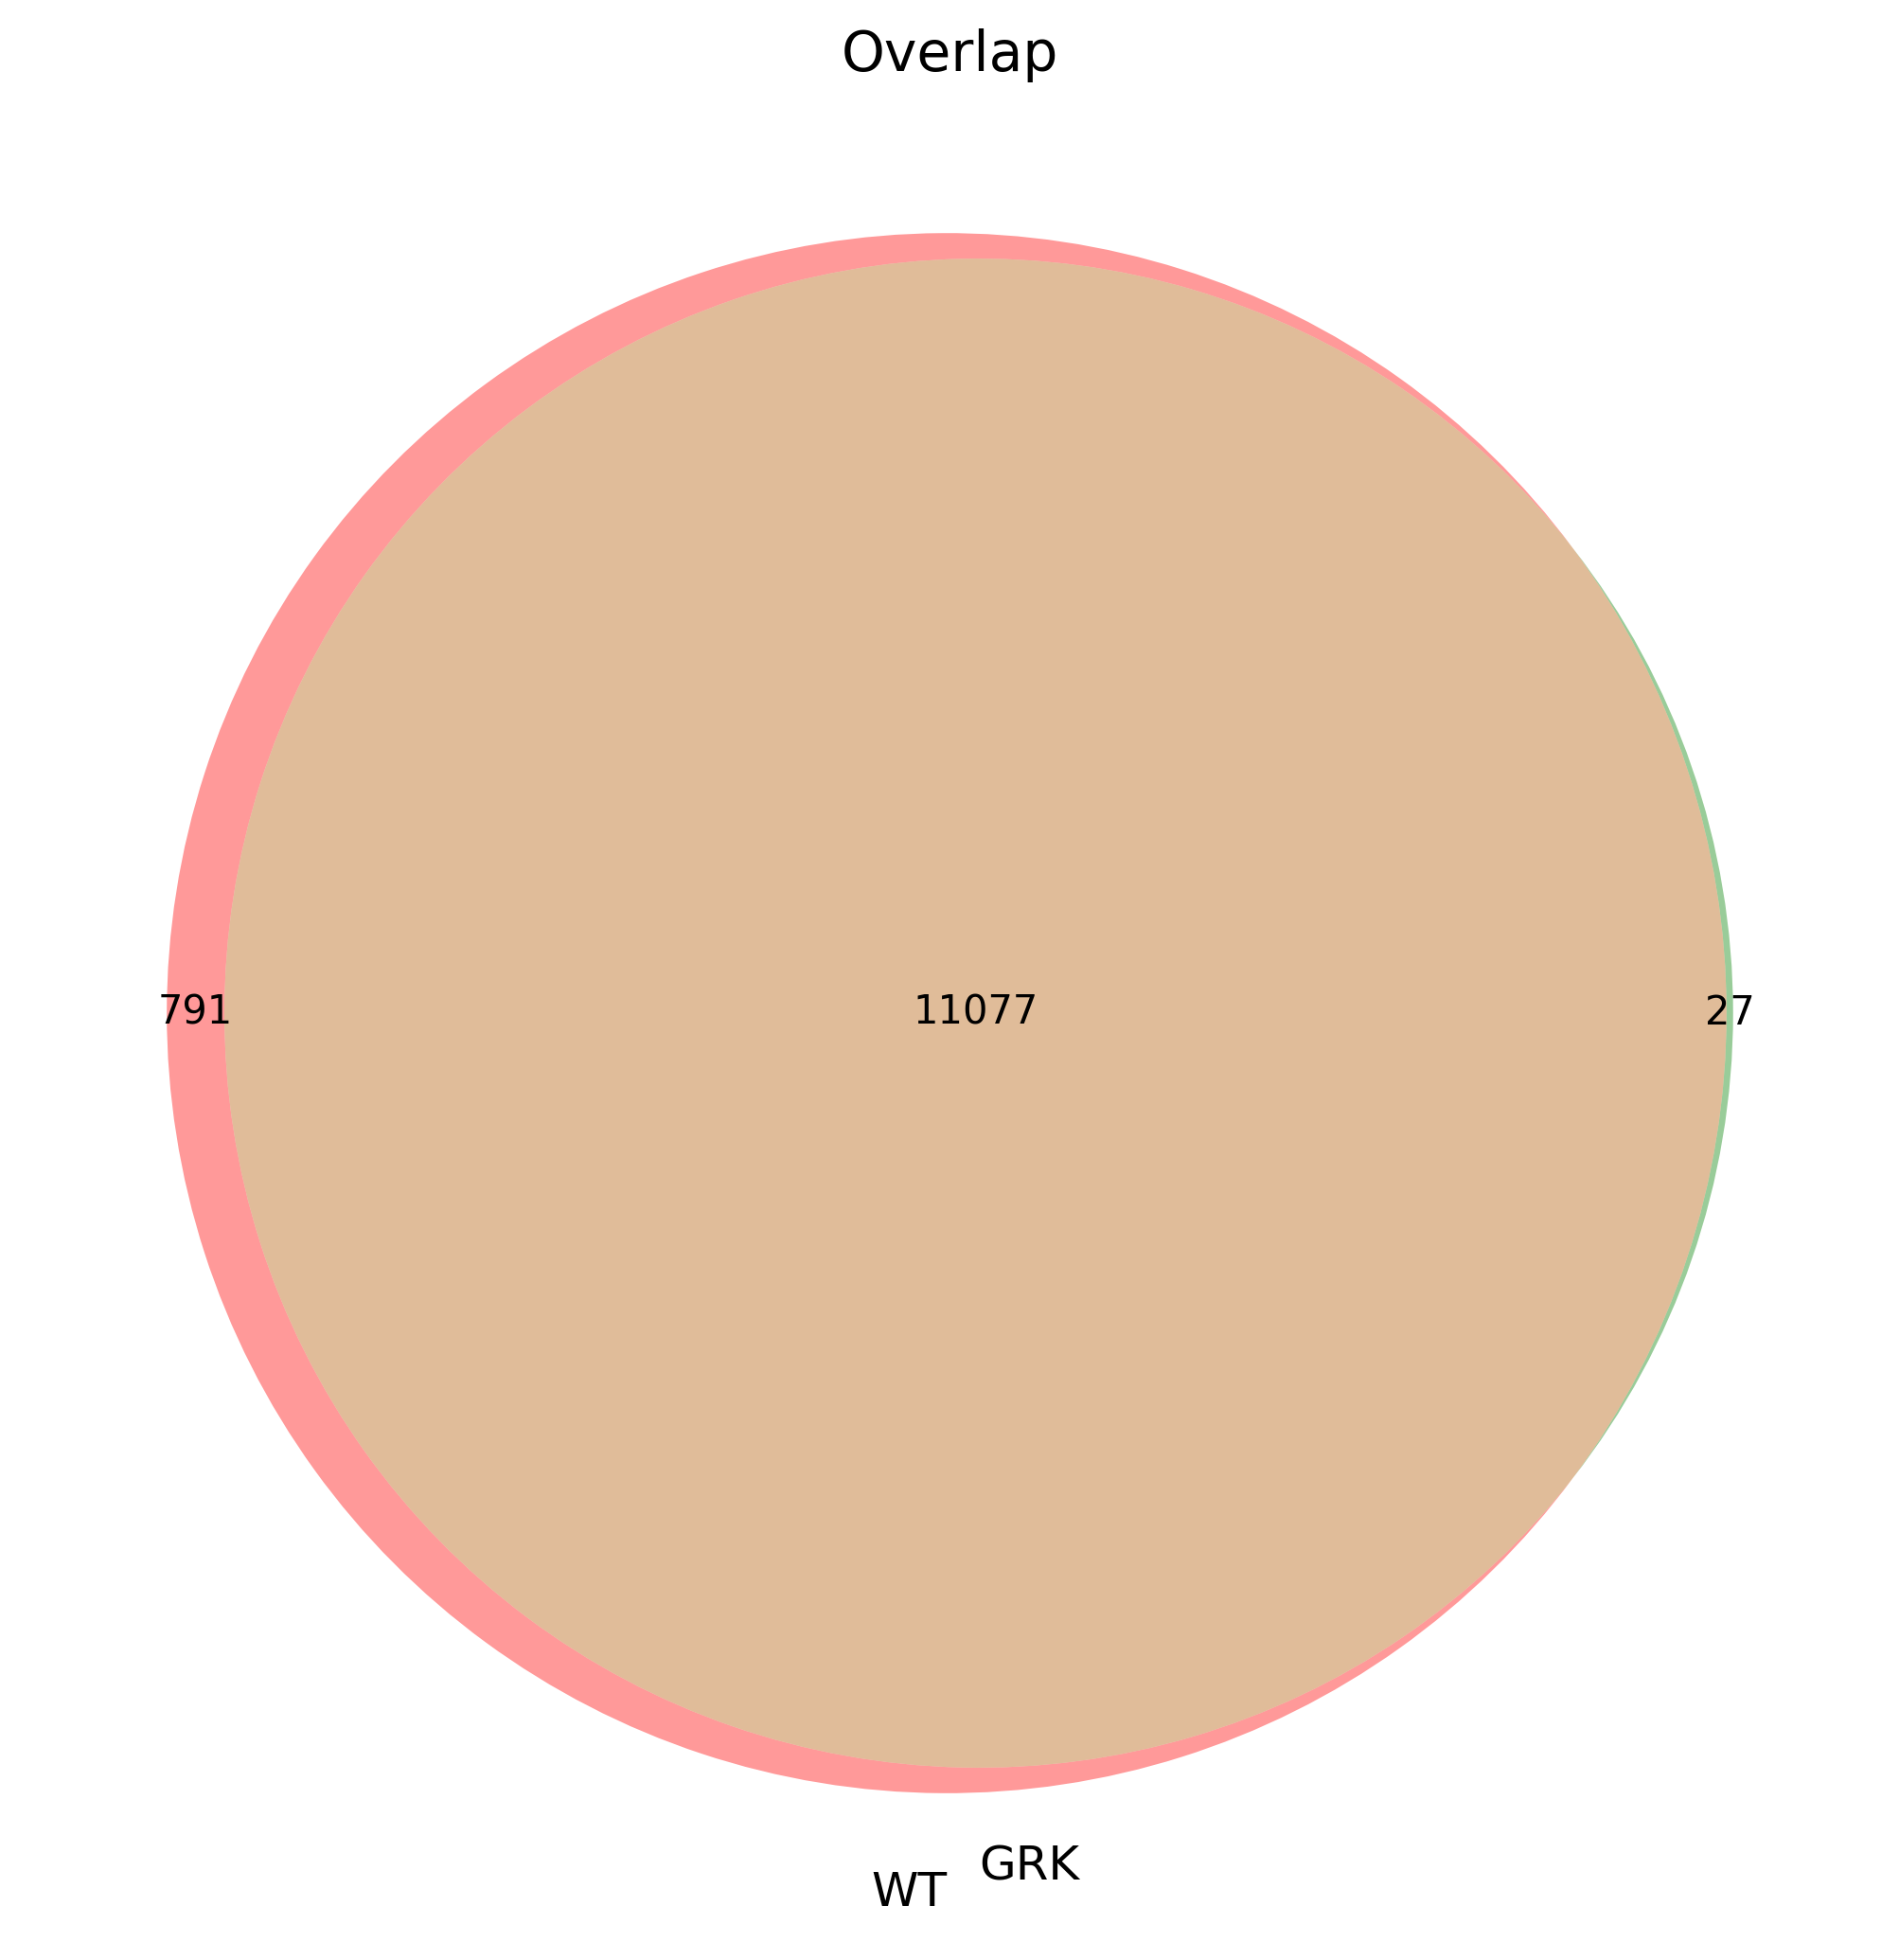

In [44]:
fig = overlap_plot_condition(data3_by_site, meta2, "WT", "GRK")

# Phosphoprotein


## Completeness


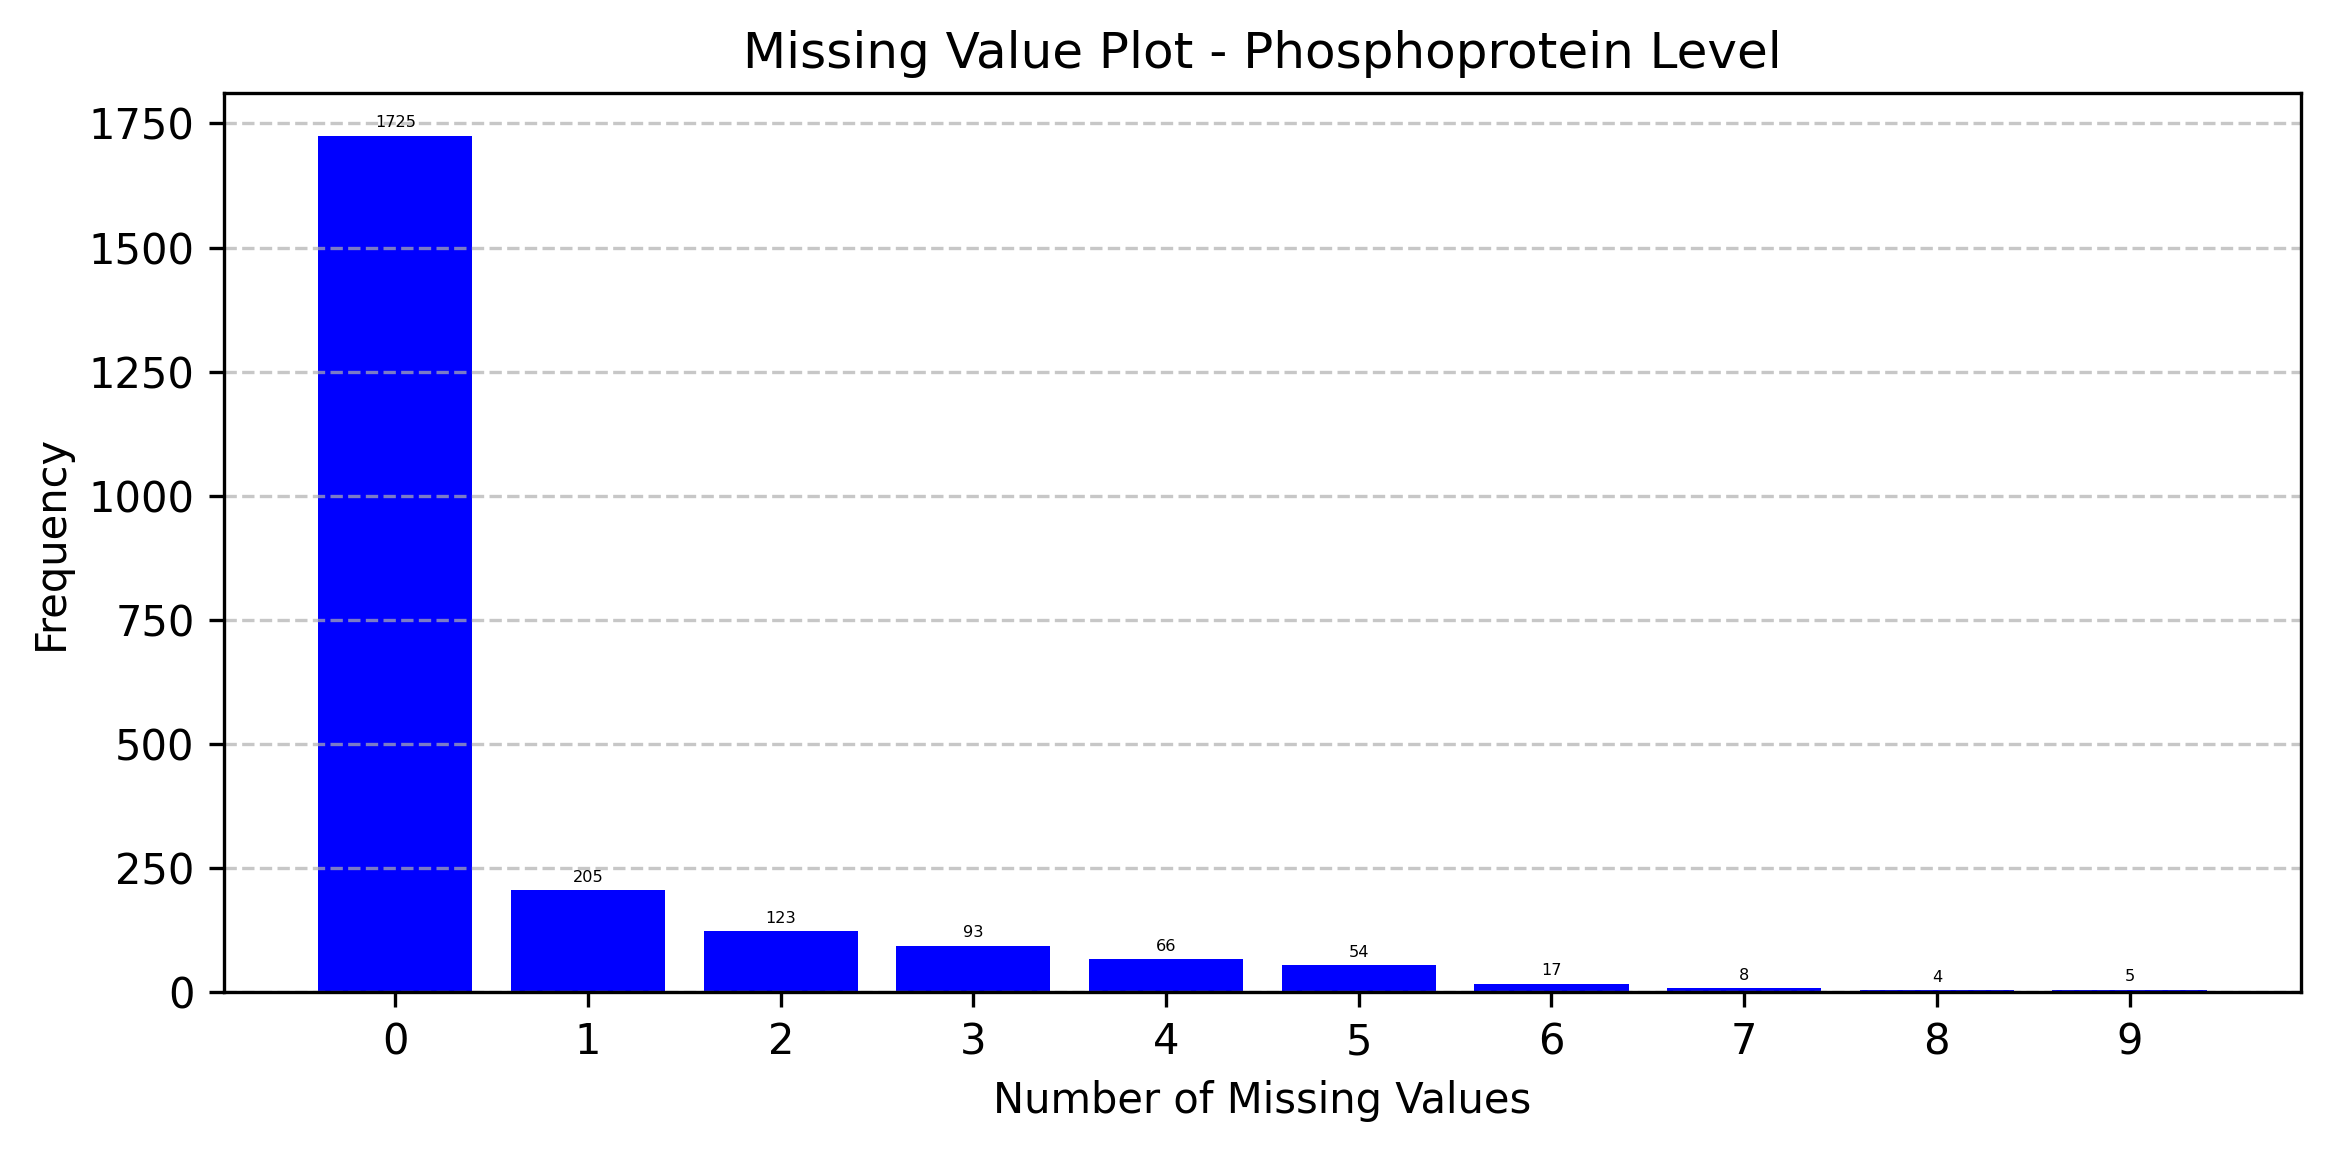

In [45]:
fig = missing_value_plot(data4, meta2)

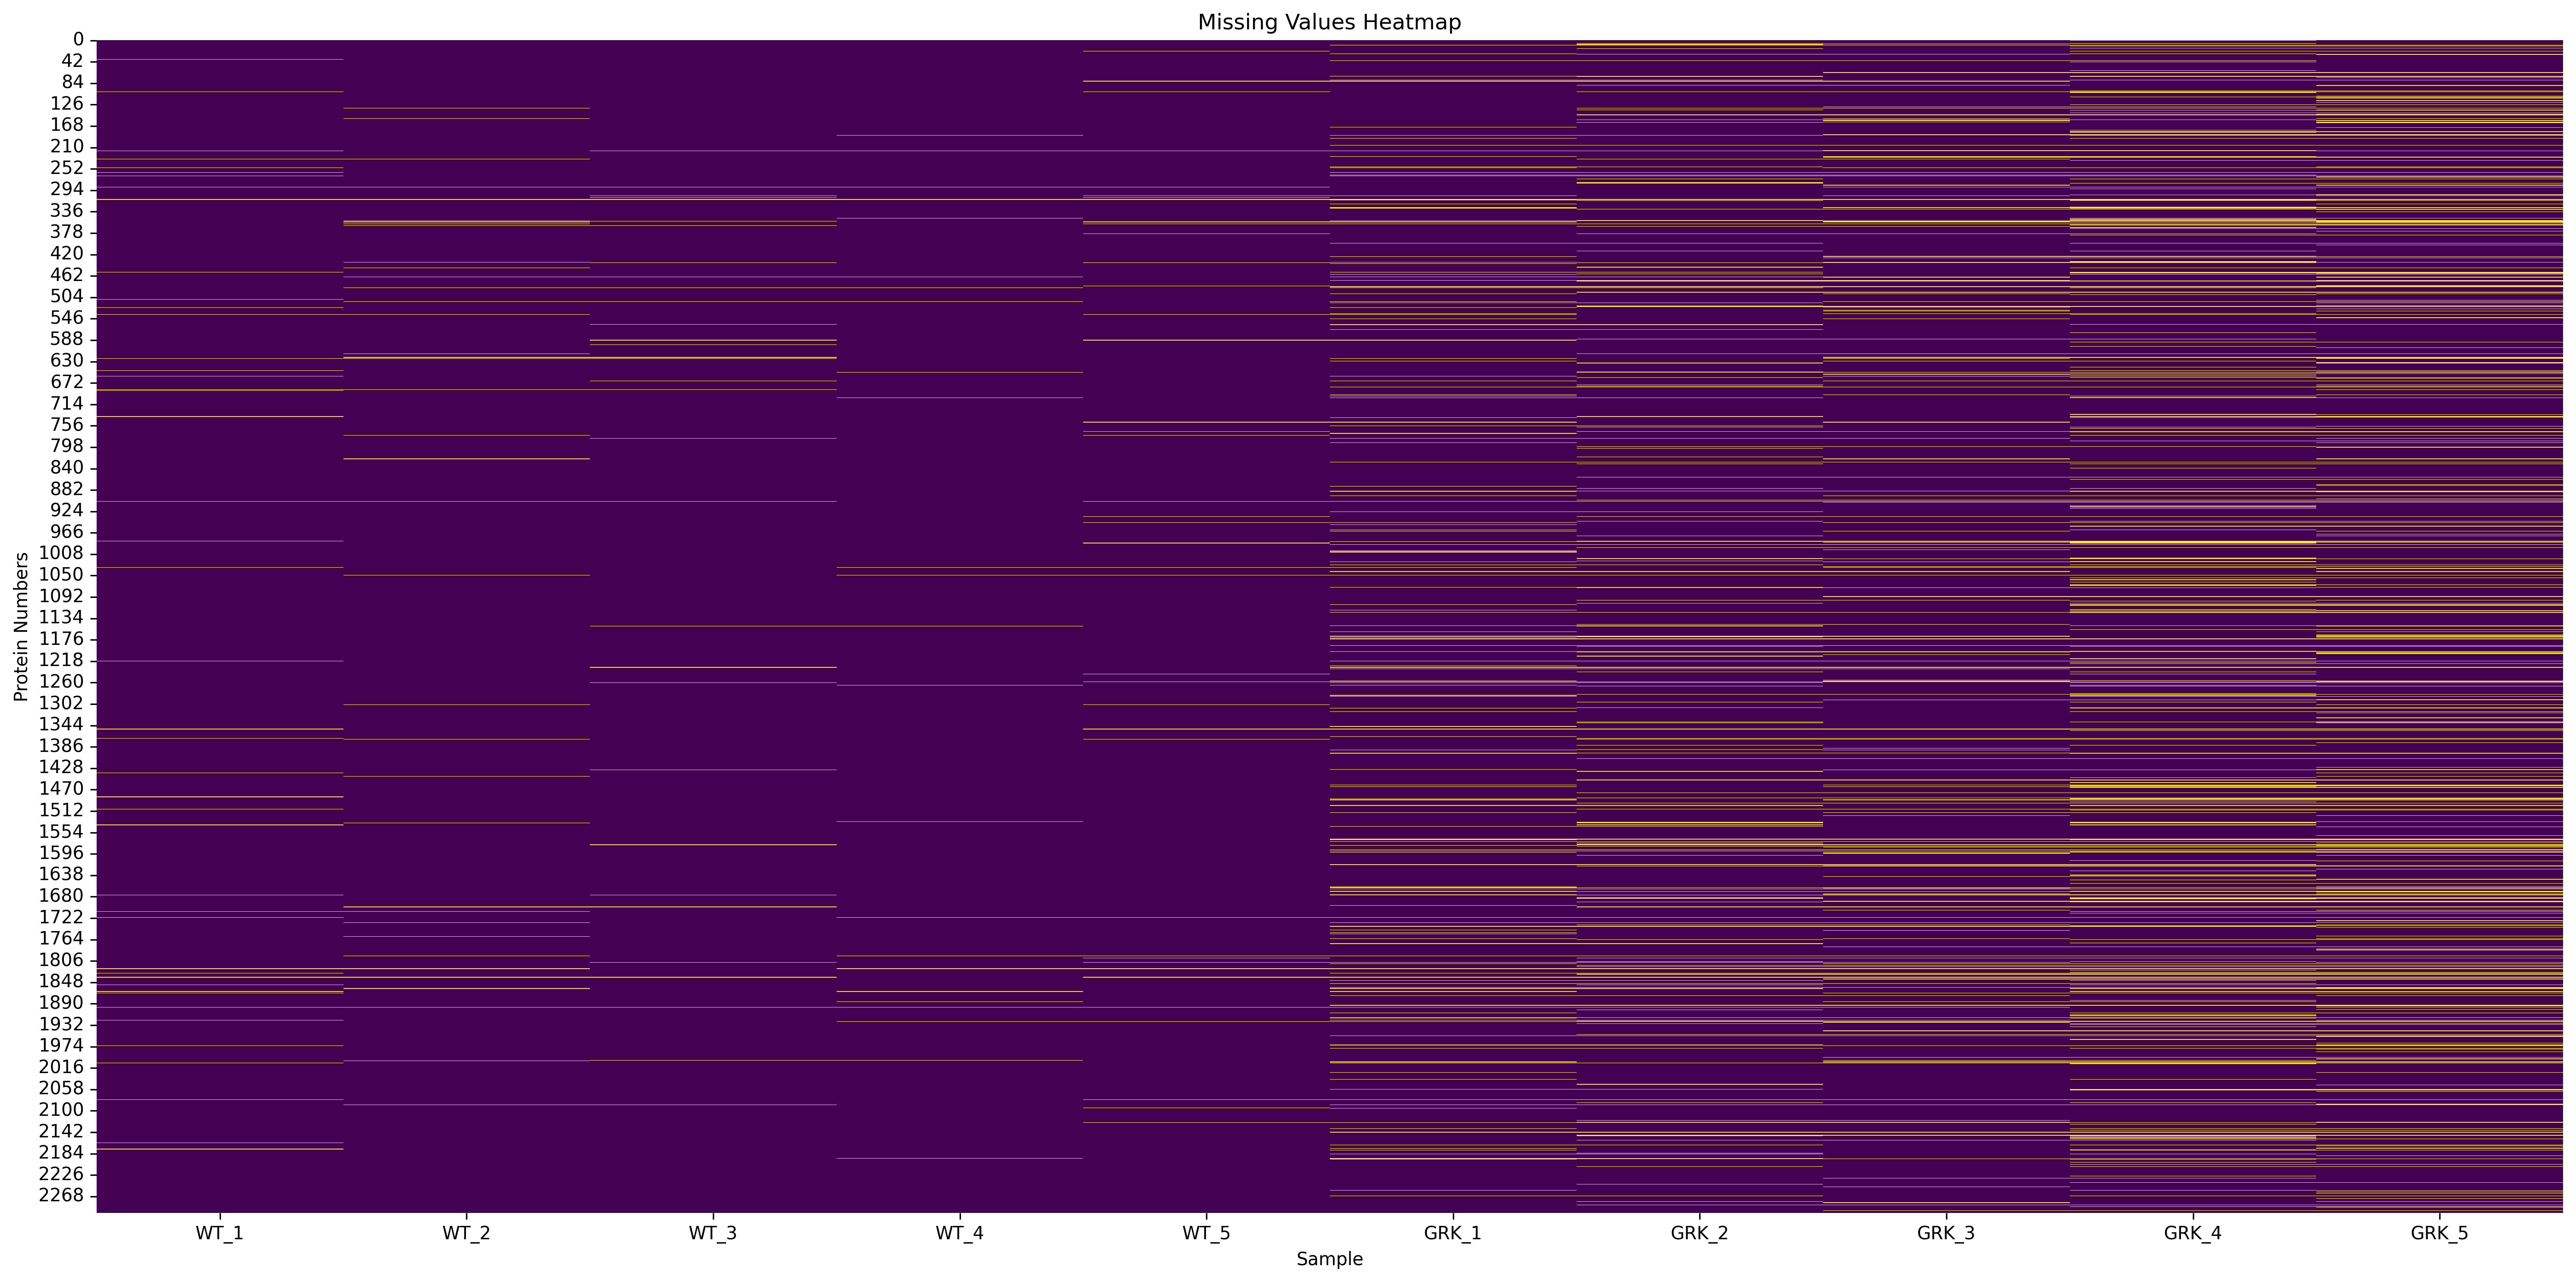

In [46]:
fig = missing_value_heatmap(data4, meta2, id=False)

In [47]:
missing_protein_table(data4, meta2, id=False)

,n_MissingProteinValues,Counts,%_missing_values
0,0,1725,74.967405
1,1,205,8.909170
2,2,123,5.345502
3,3,93,4.041721
4,4,66,2.868318
5,5,54,2.346806
6,6,17,0.738809
7,7,8,0.347675
8,8,4,0.173837
9,9,5,0.217297


In [48]:
missing_sample_table(data4, meta2, id=False)

,Sample,Counts,%_missing_values
0,WT_1,45,1.955671
1,WT_2,38,1.651456
2,WT_3,32,1.390700
3,WT_4,24,1.043025
4,WT_5,40,1.738375
5,GRK_1,184,7.996523
6,GRK_2,215,9.343764
7,GRK_3,207,8.996089
8,GRK_4,350,15.210778
9,GRK_5,374,16.253803


## QC Pipeline


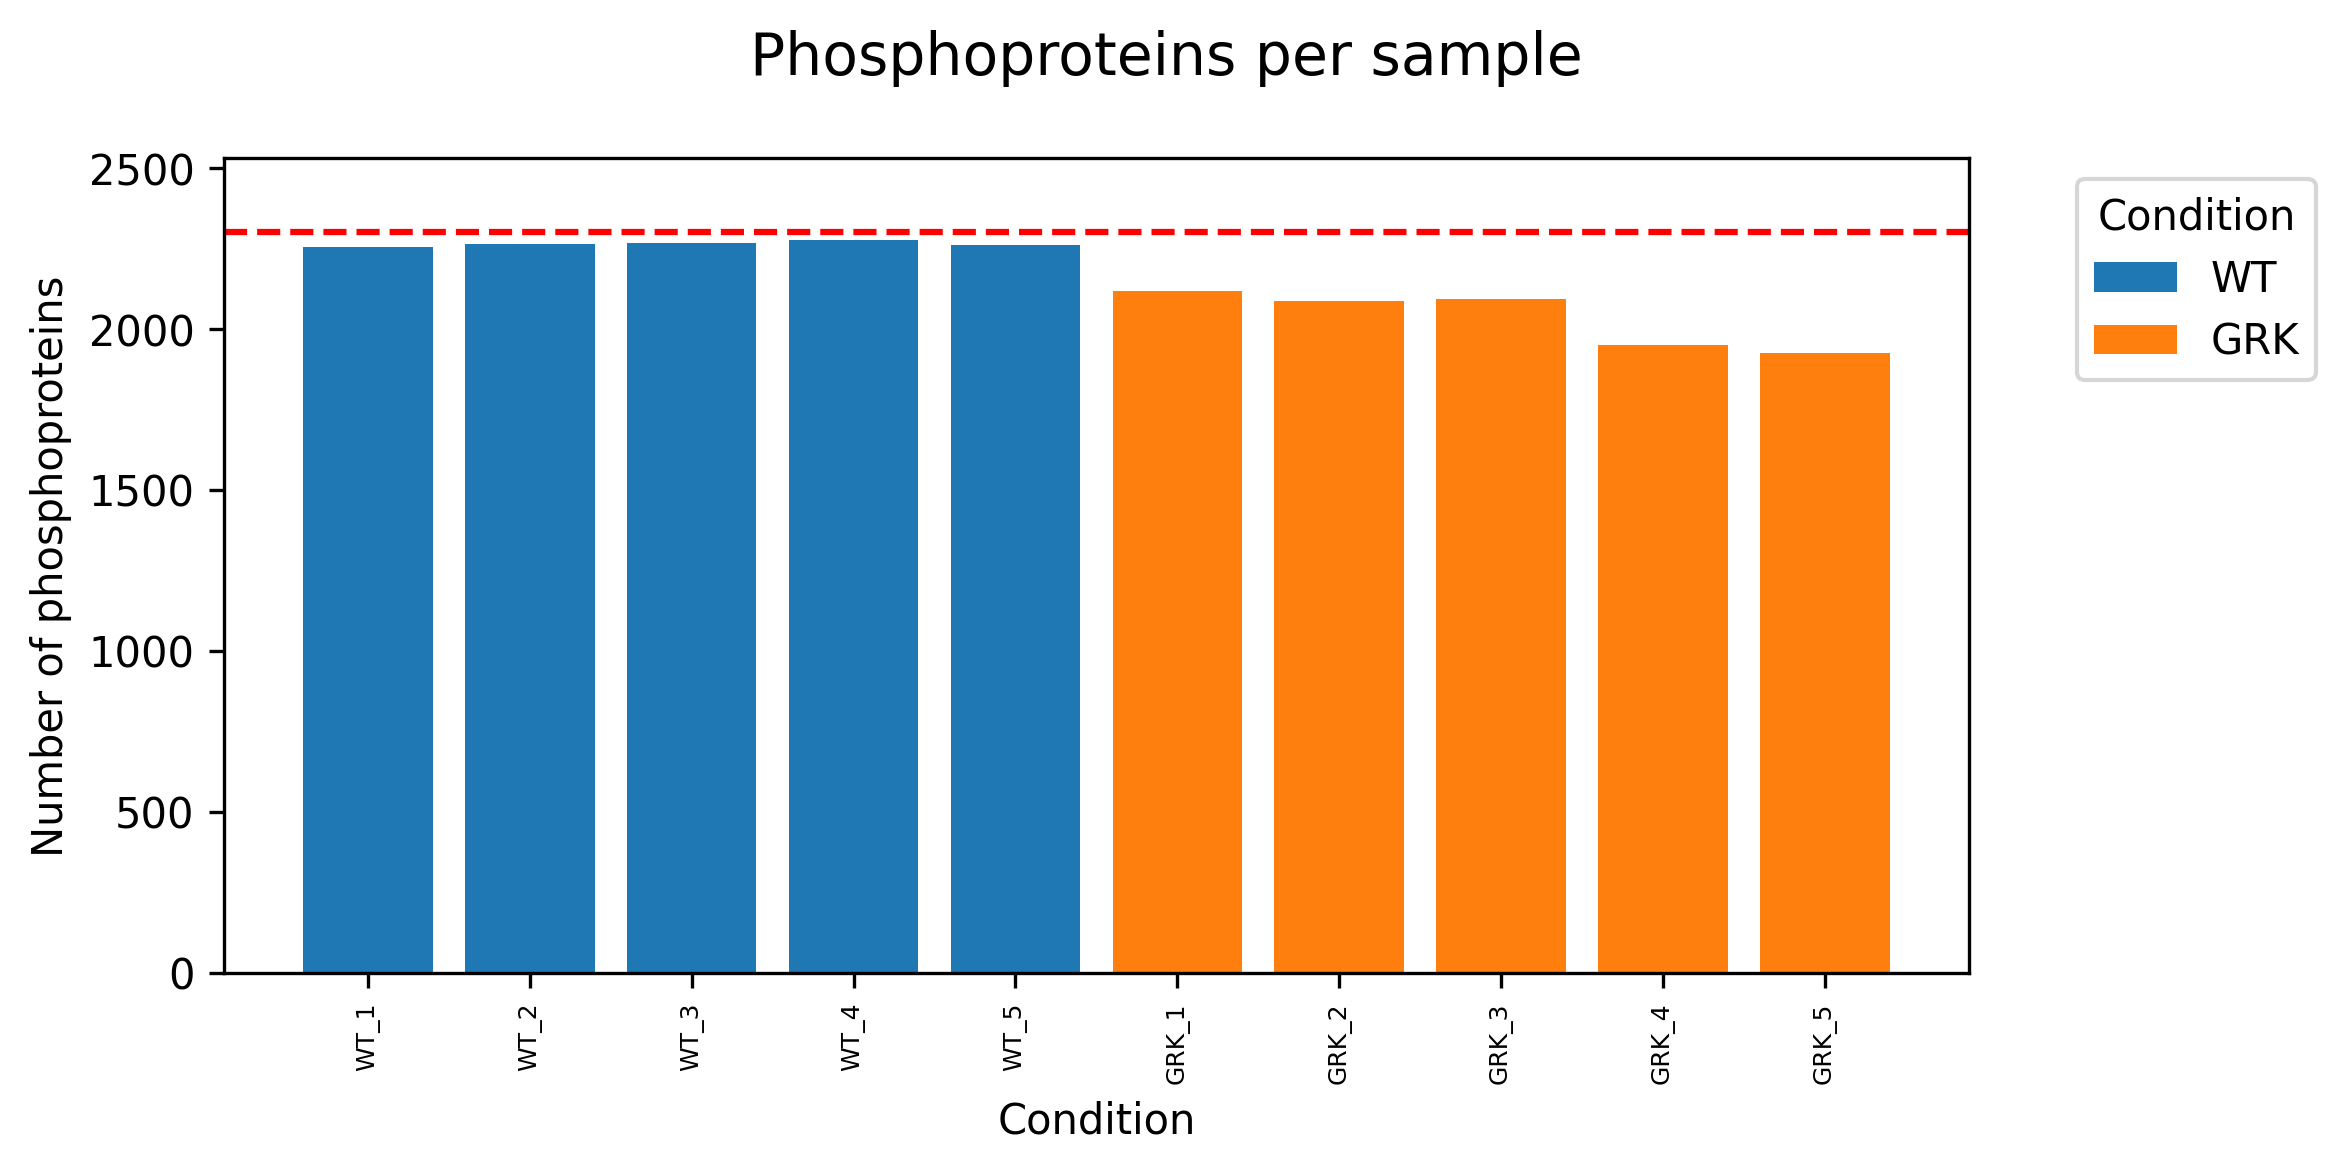

In [49]:
fig = coverage_plot(data4, meta2, id=False)

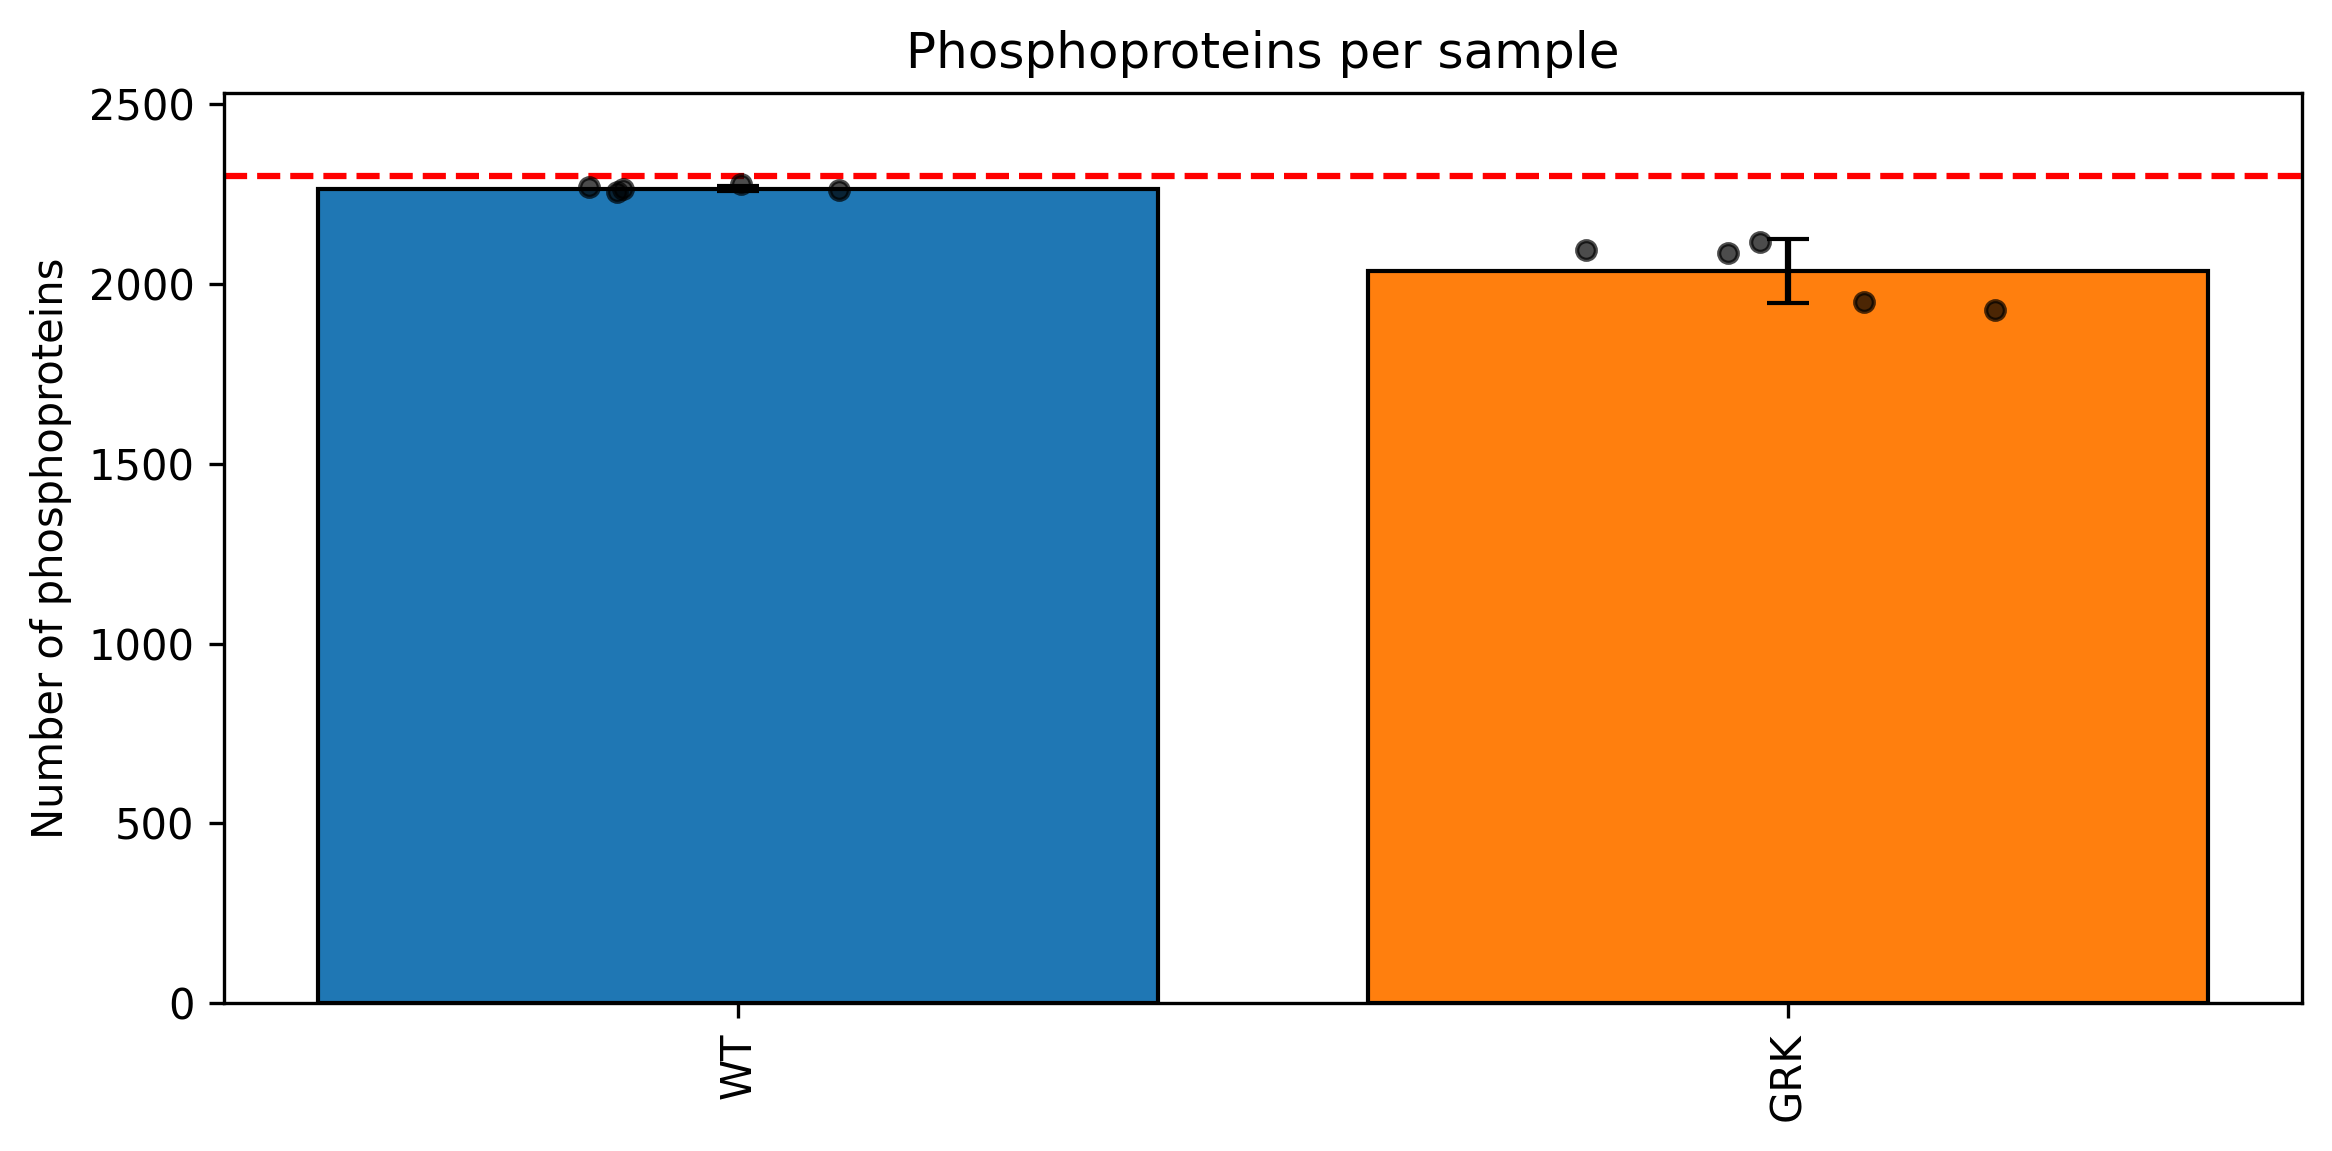

In [50]:
fig = coverage_plot_summary(data4, meta2)

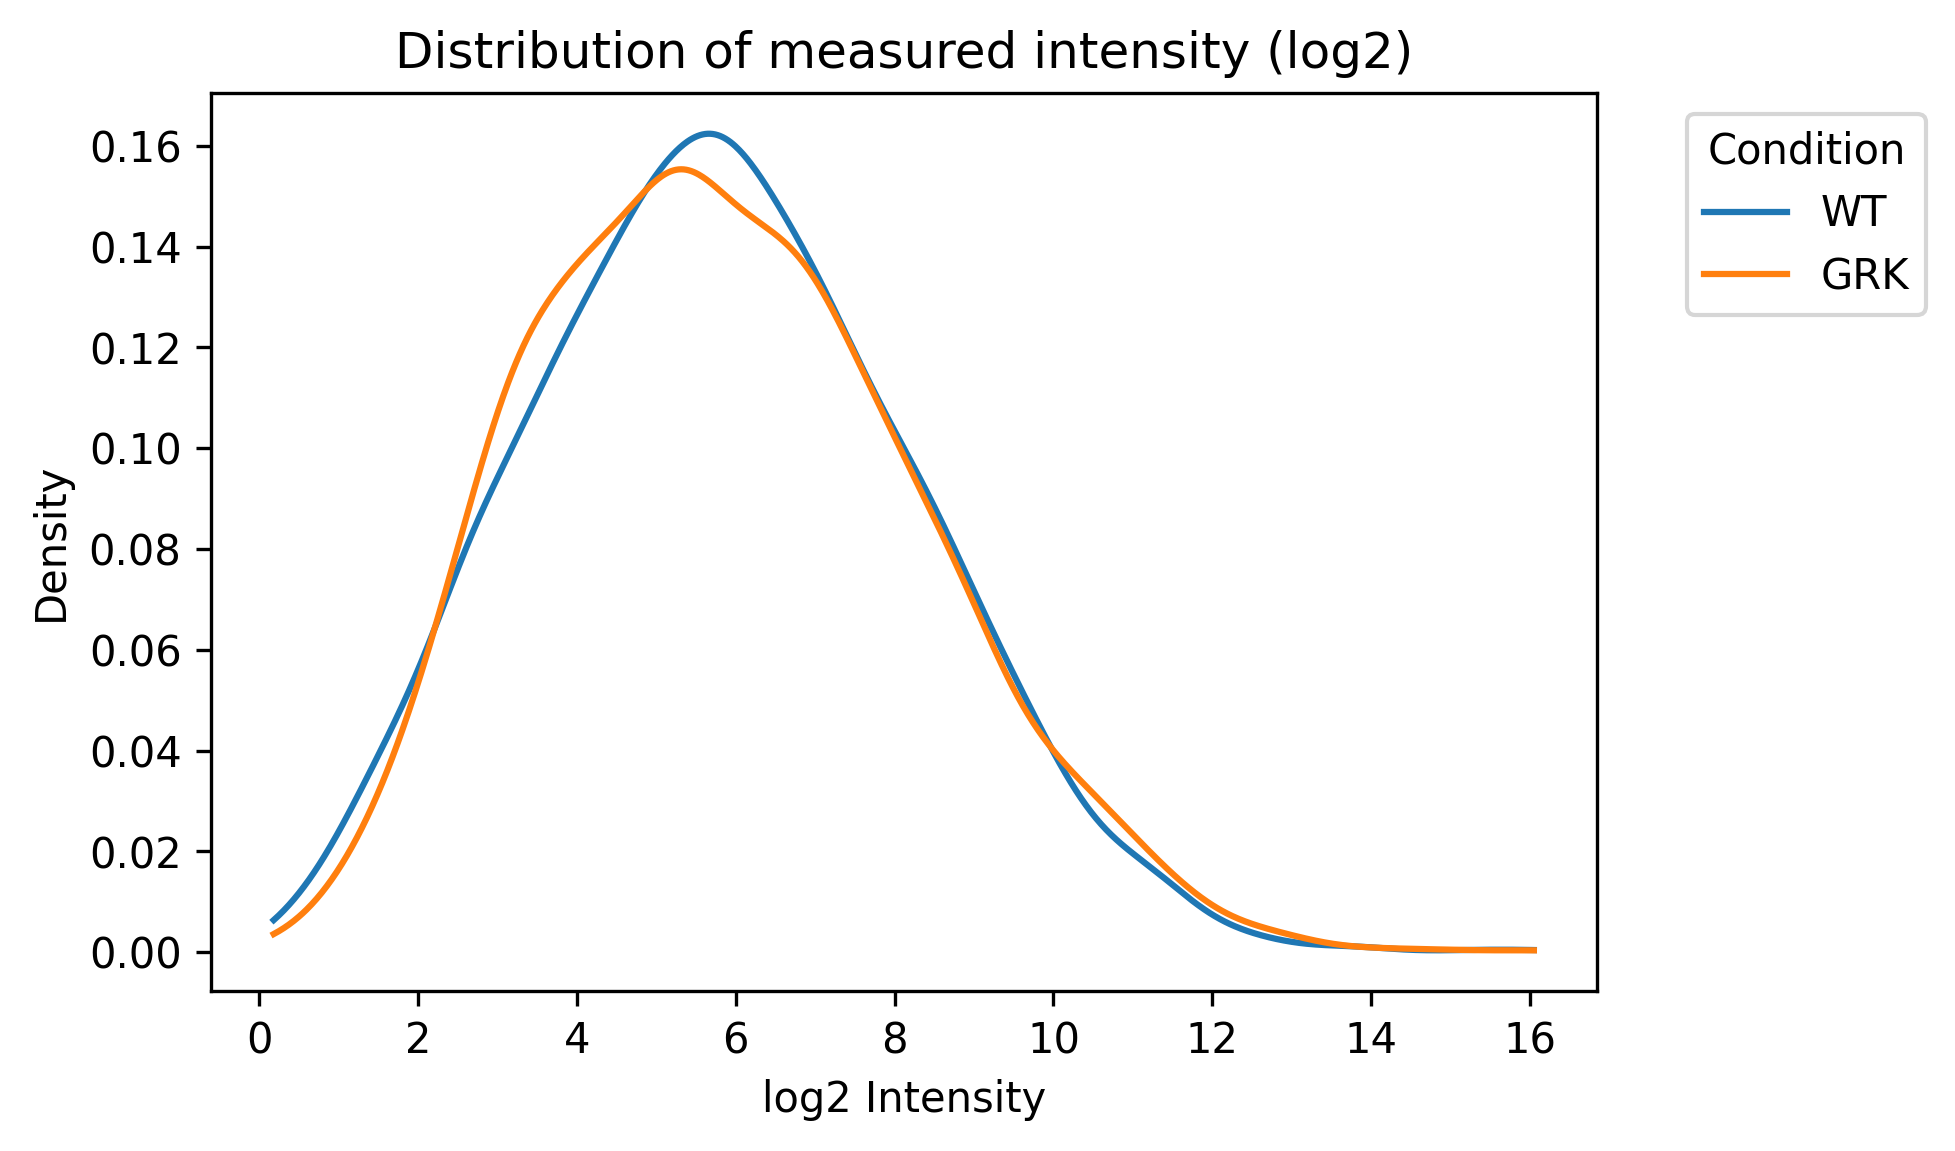

In [51]:
fig = histo_int(data4, meta2)

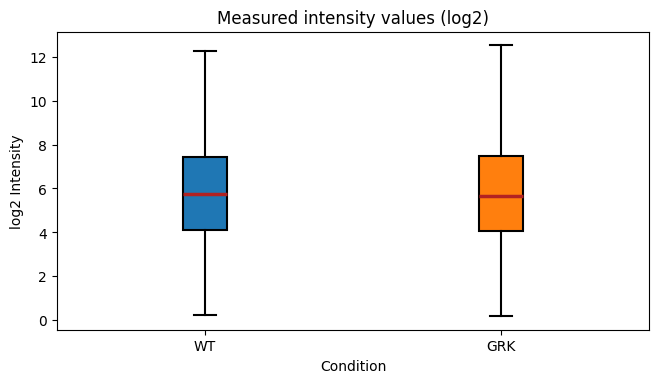

In [52]:
fig = boxplot_int(data4, meta2)

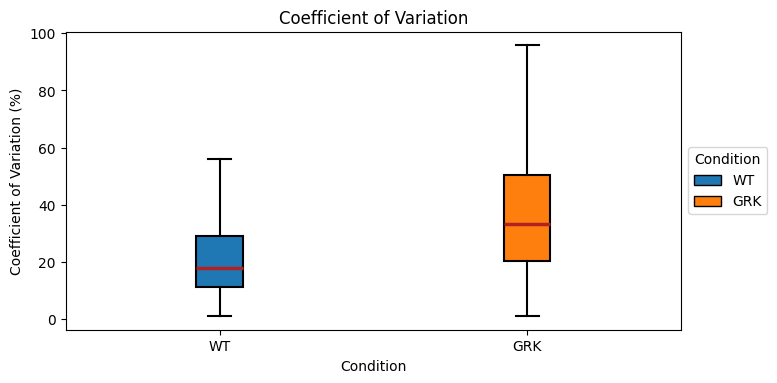

In [53]:
fig = cov_plot(org_data4, meta2)

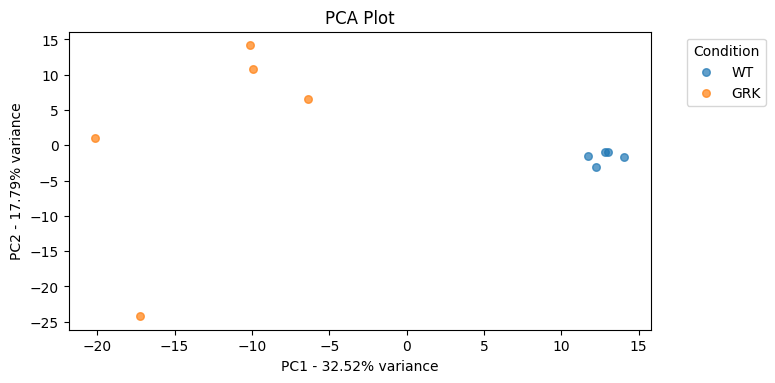

In [54]:
fig = pca_plot(data4, meta2)

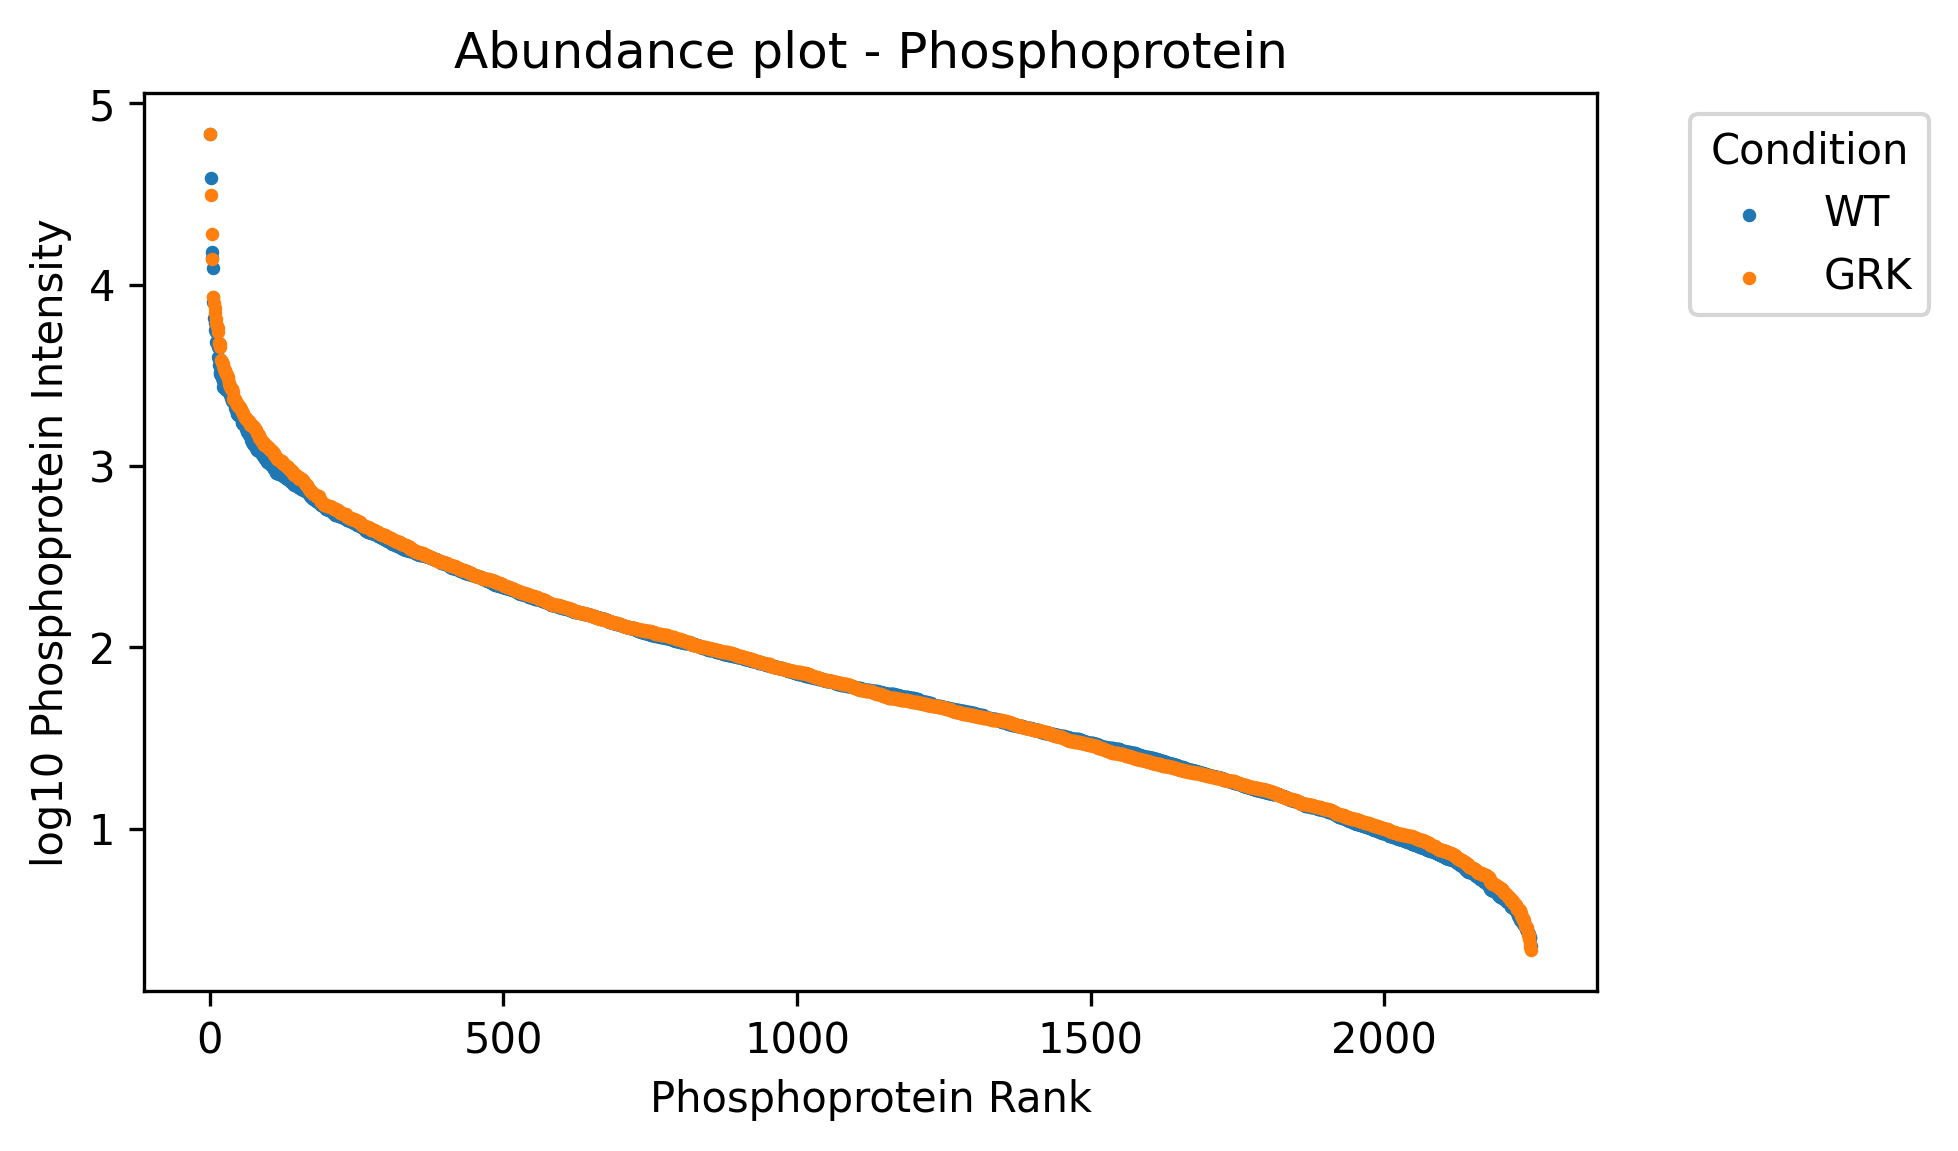

In [55]:
fig = abundance_plot(org_data4, meta2, workflow="Phosphoprotein")

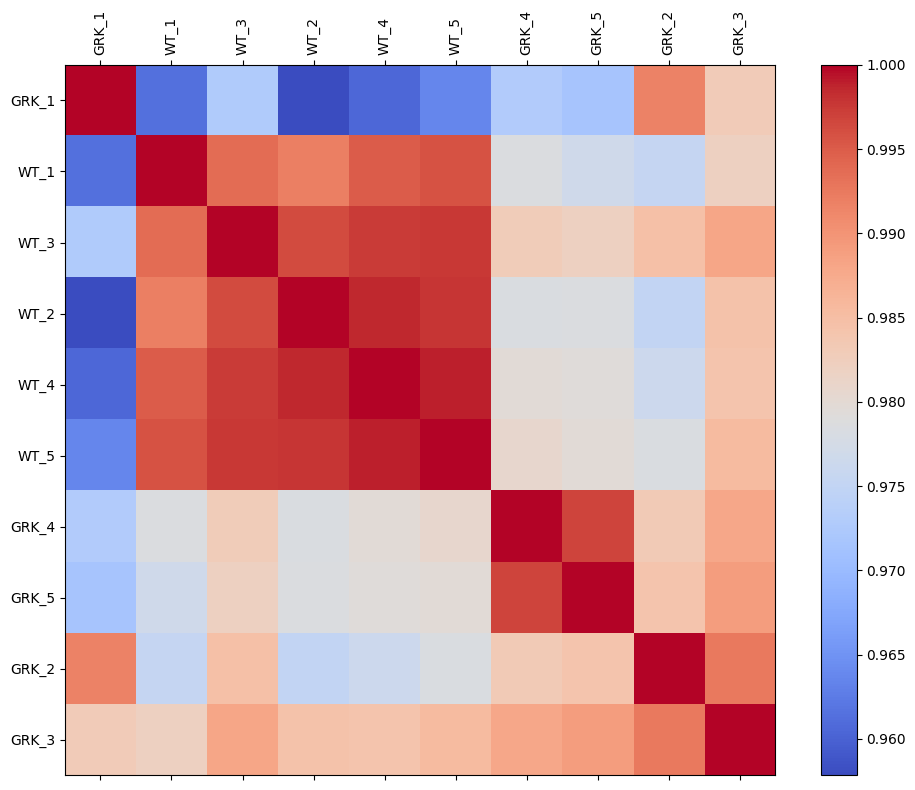

In [56]:
fig = corr_plot(org_data4, meta2, id=False)

## Volcano Plot


In [57]:
volcano_data = volcano_data_f(data4, meta2, "WT", "GRK", workflow="Phosphoprotein")
volcano_data.head()

,Phosphoprotein,log2FC,pval,adj_pval,significance,neg_log10_adj_pval,site_num,PTM_Collapse_keys
0,A0A590UK10,-0.279388,0.452782,0.646004,Not significant,0.189765,2,A0A590UK10~ARHGEF18_S1035_M1;A0A590UK10~ARHGEF...
1,A0JLT2,0.502388,0.033772,0.134715,Not significant,0.870584,1,A0JLT2~MED19_S226_M1
2,A0JNW5,-0.390386,0.718425,0.837712,Not significant,0.076905,7,A0JNW5~BLTP3B_S414_M1;A0JNW5~BLTP3B_S418_M1;A0...
3,A0MZ66,0.262295,0.057693,0.180917,Not significant,0.742522,7,A0MZ66~SHTN1_S492_M1;A0MZ66~SHTN1_S493_M1;A0MZ...
4,A1L170,-0.919726,0.072906,0.206267,Not significant,0.685569,2,A1L170~C1orf226_S18_M1;A1L170~C1orf226_S223_M1


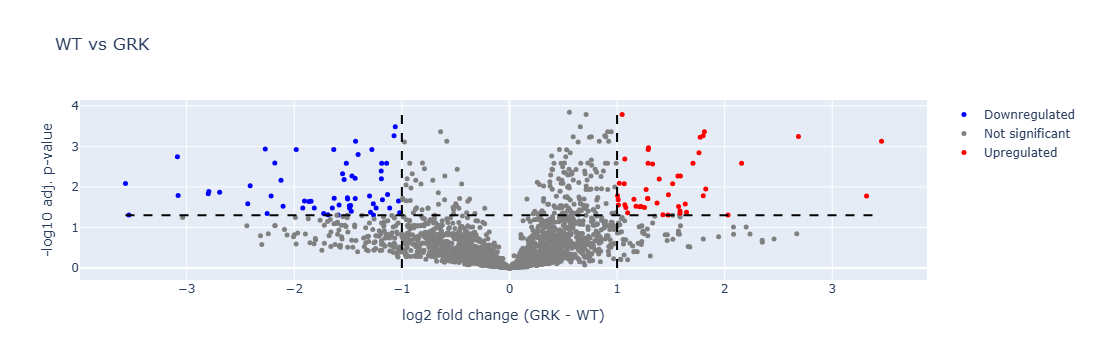

In [58]:
fig = volcano_plot(volcano_data, "WT", "GRK")
fig.show()

## Single Protein


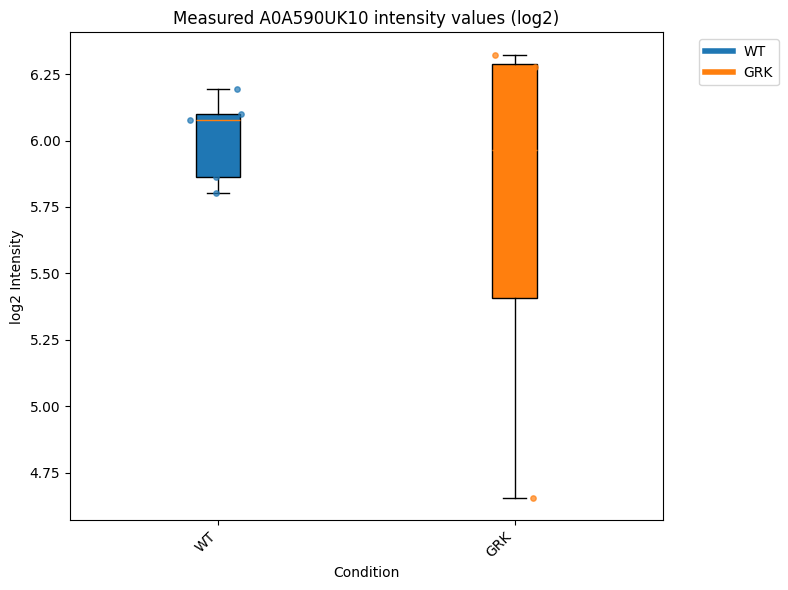

In [59]:
fig = boxplot_int_single_prot(data4_by_phosprot, meta2, phosphoprotein_id, dots=True)

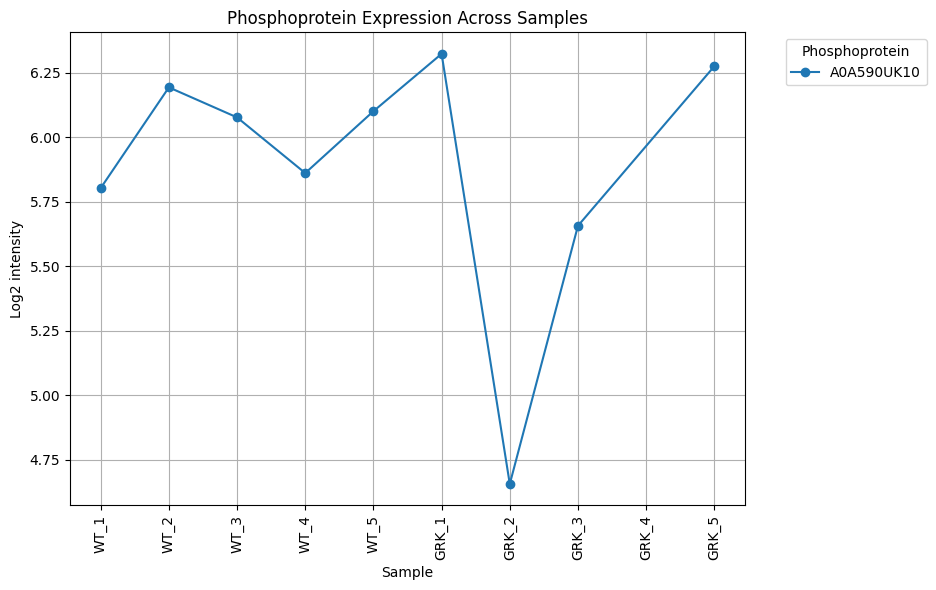

In [60]:
fig = compare_prot_line(data4, meta2, conditions, [phosphoprotein_id], workflow="Phosphoprotein", id=False)

## Comparison


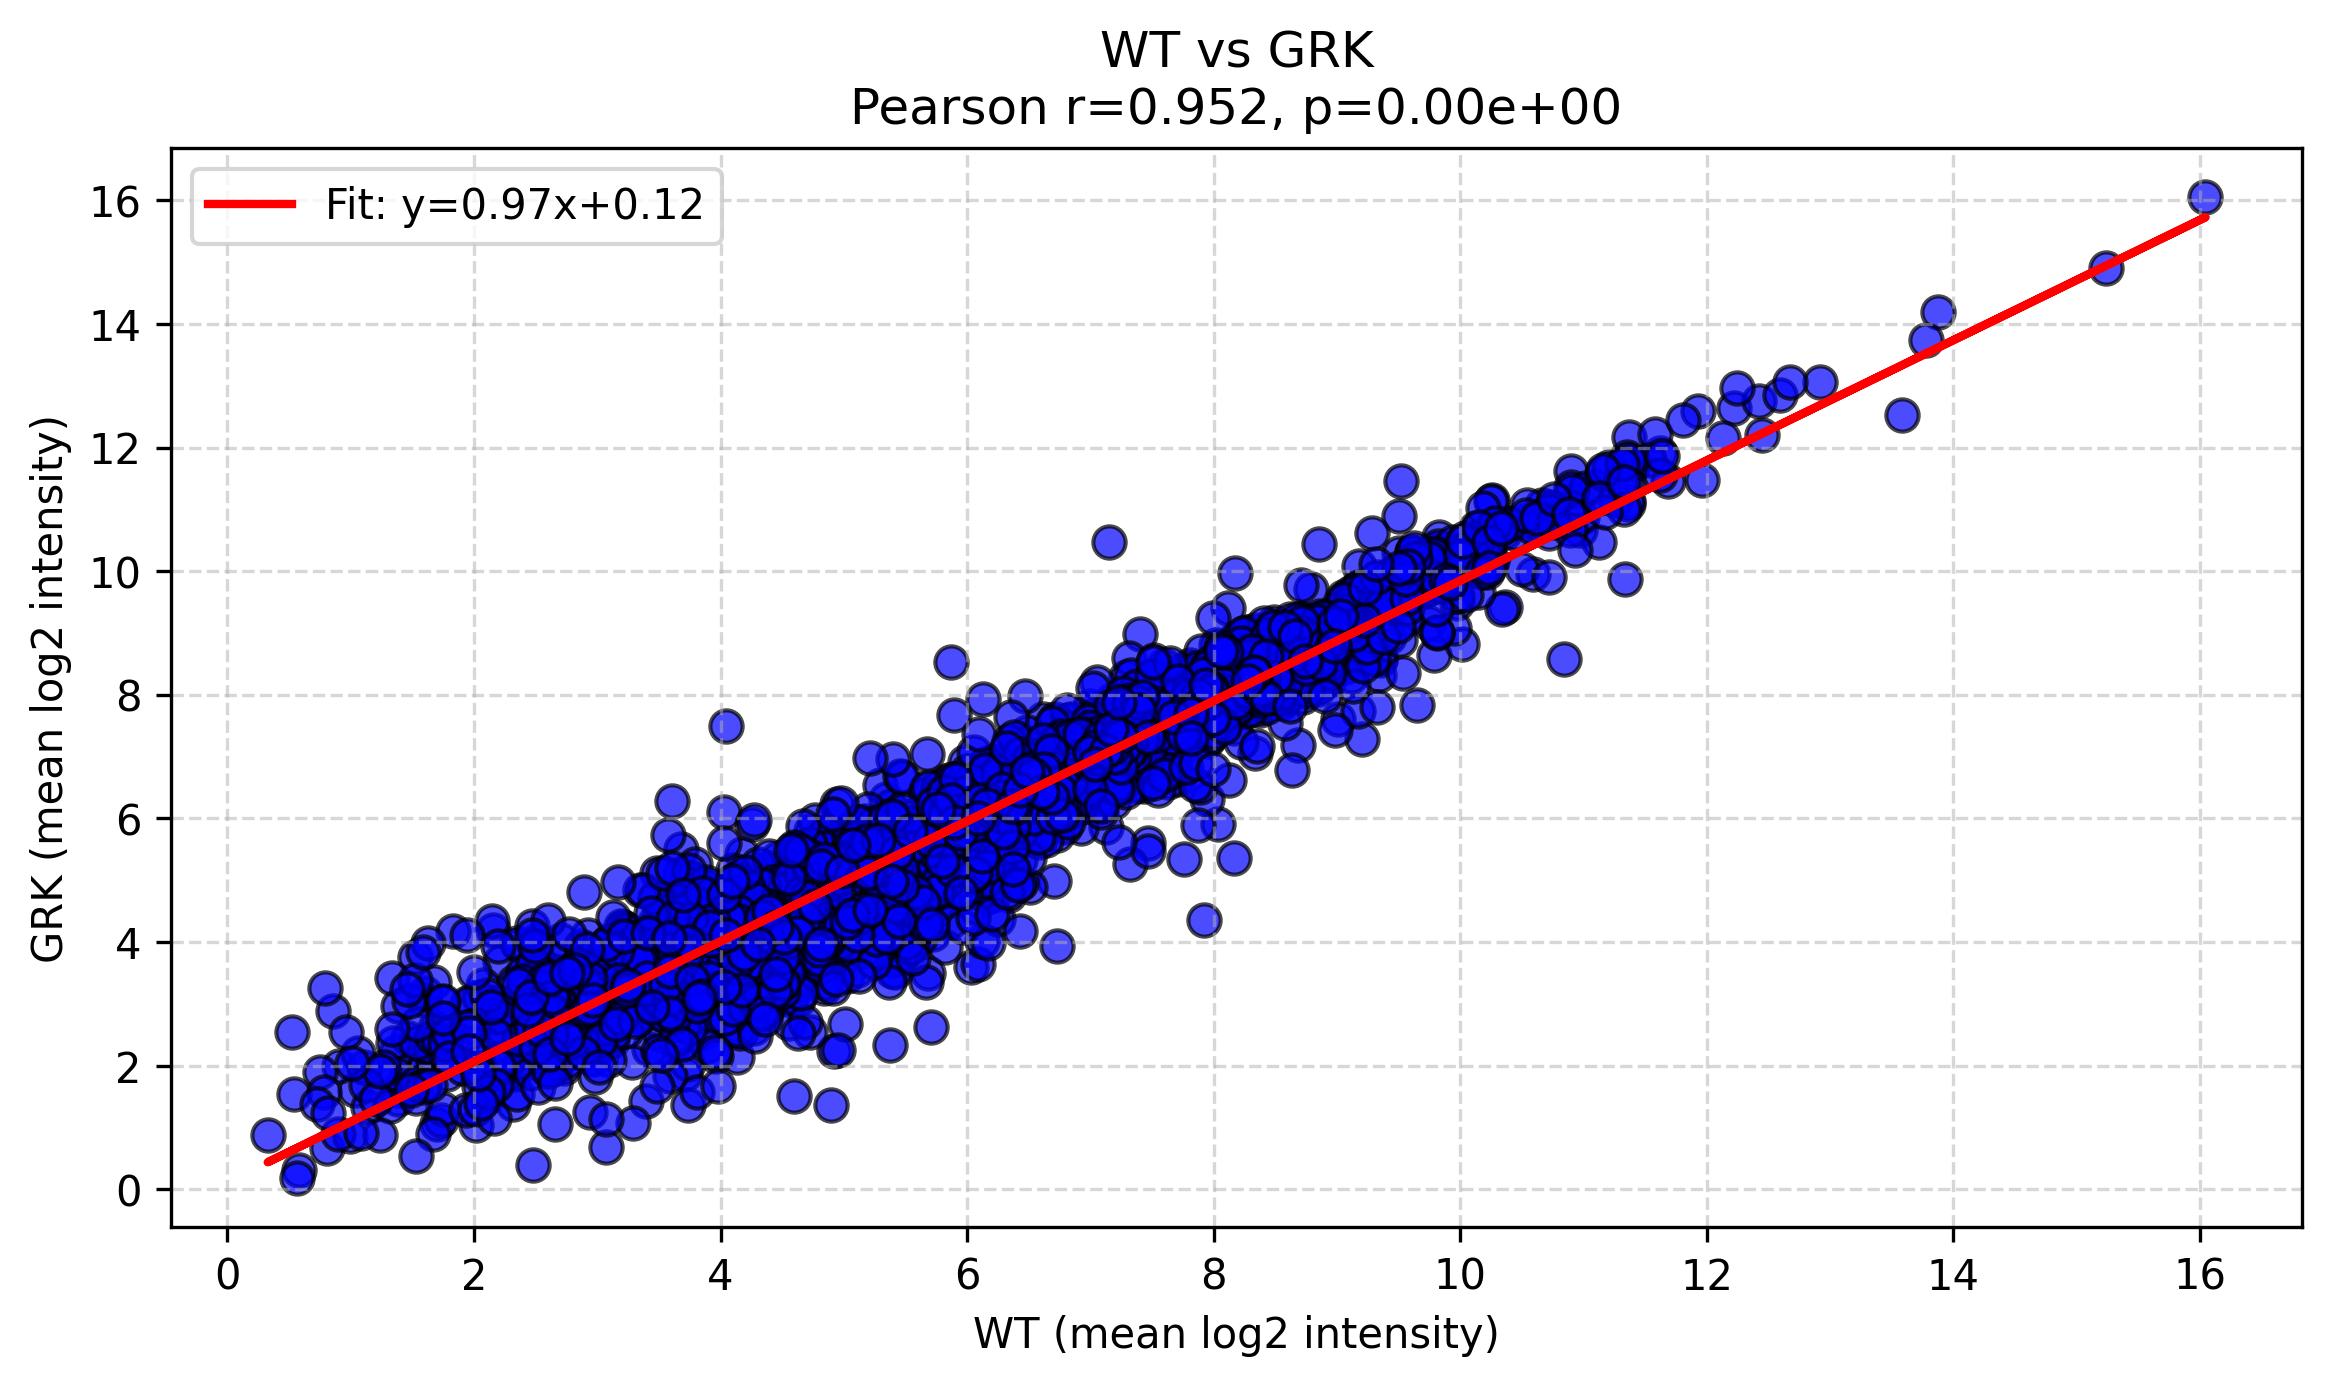

In [61]:
fig = correlation_xy_intensity(data4, meta2, "WT", "GRK")

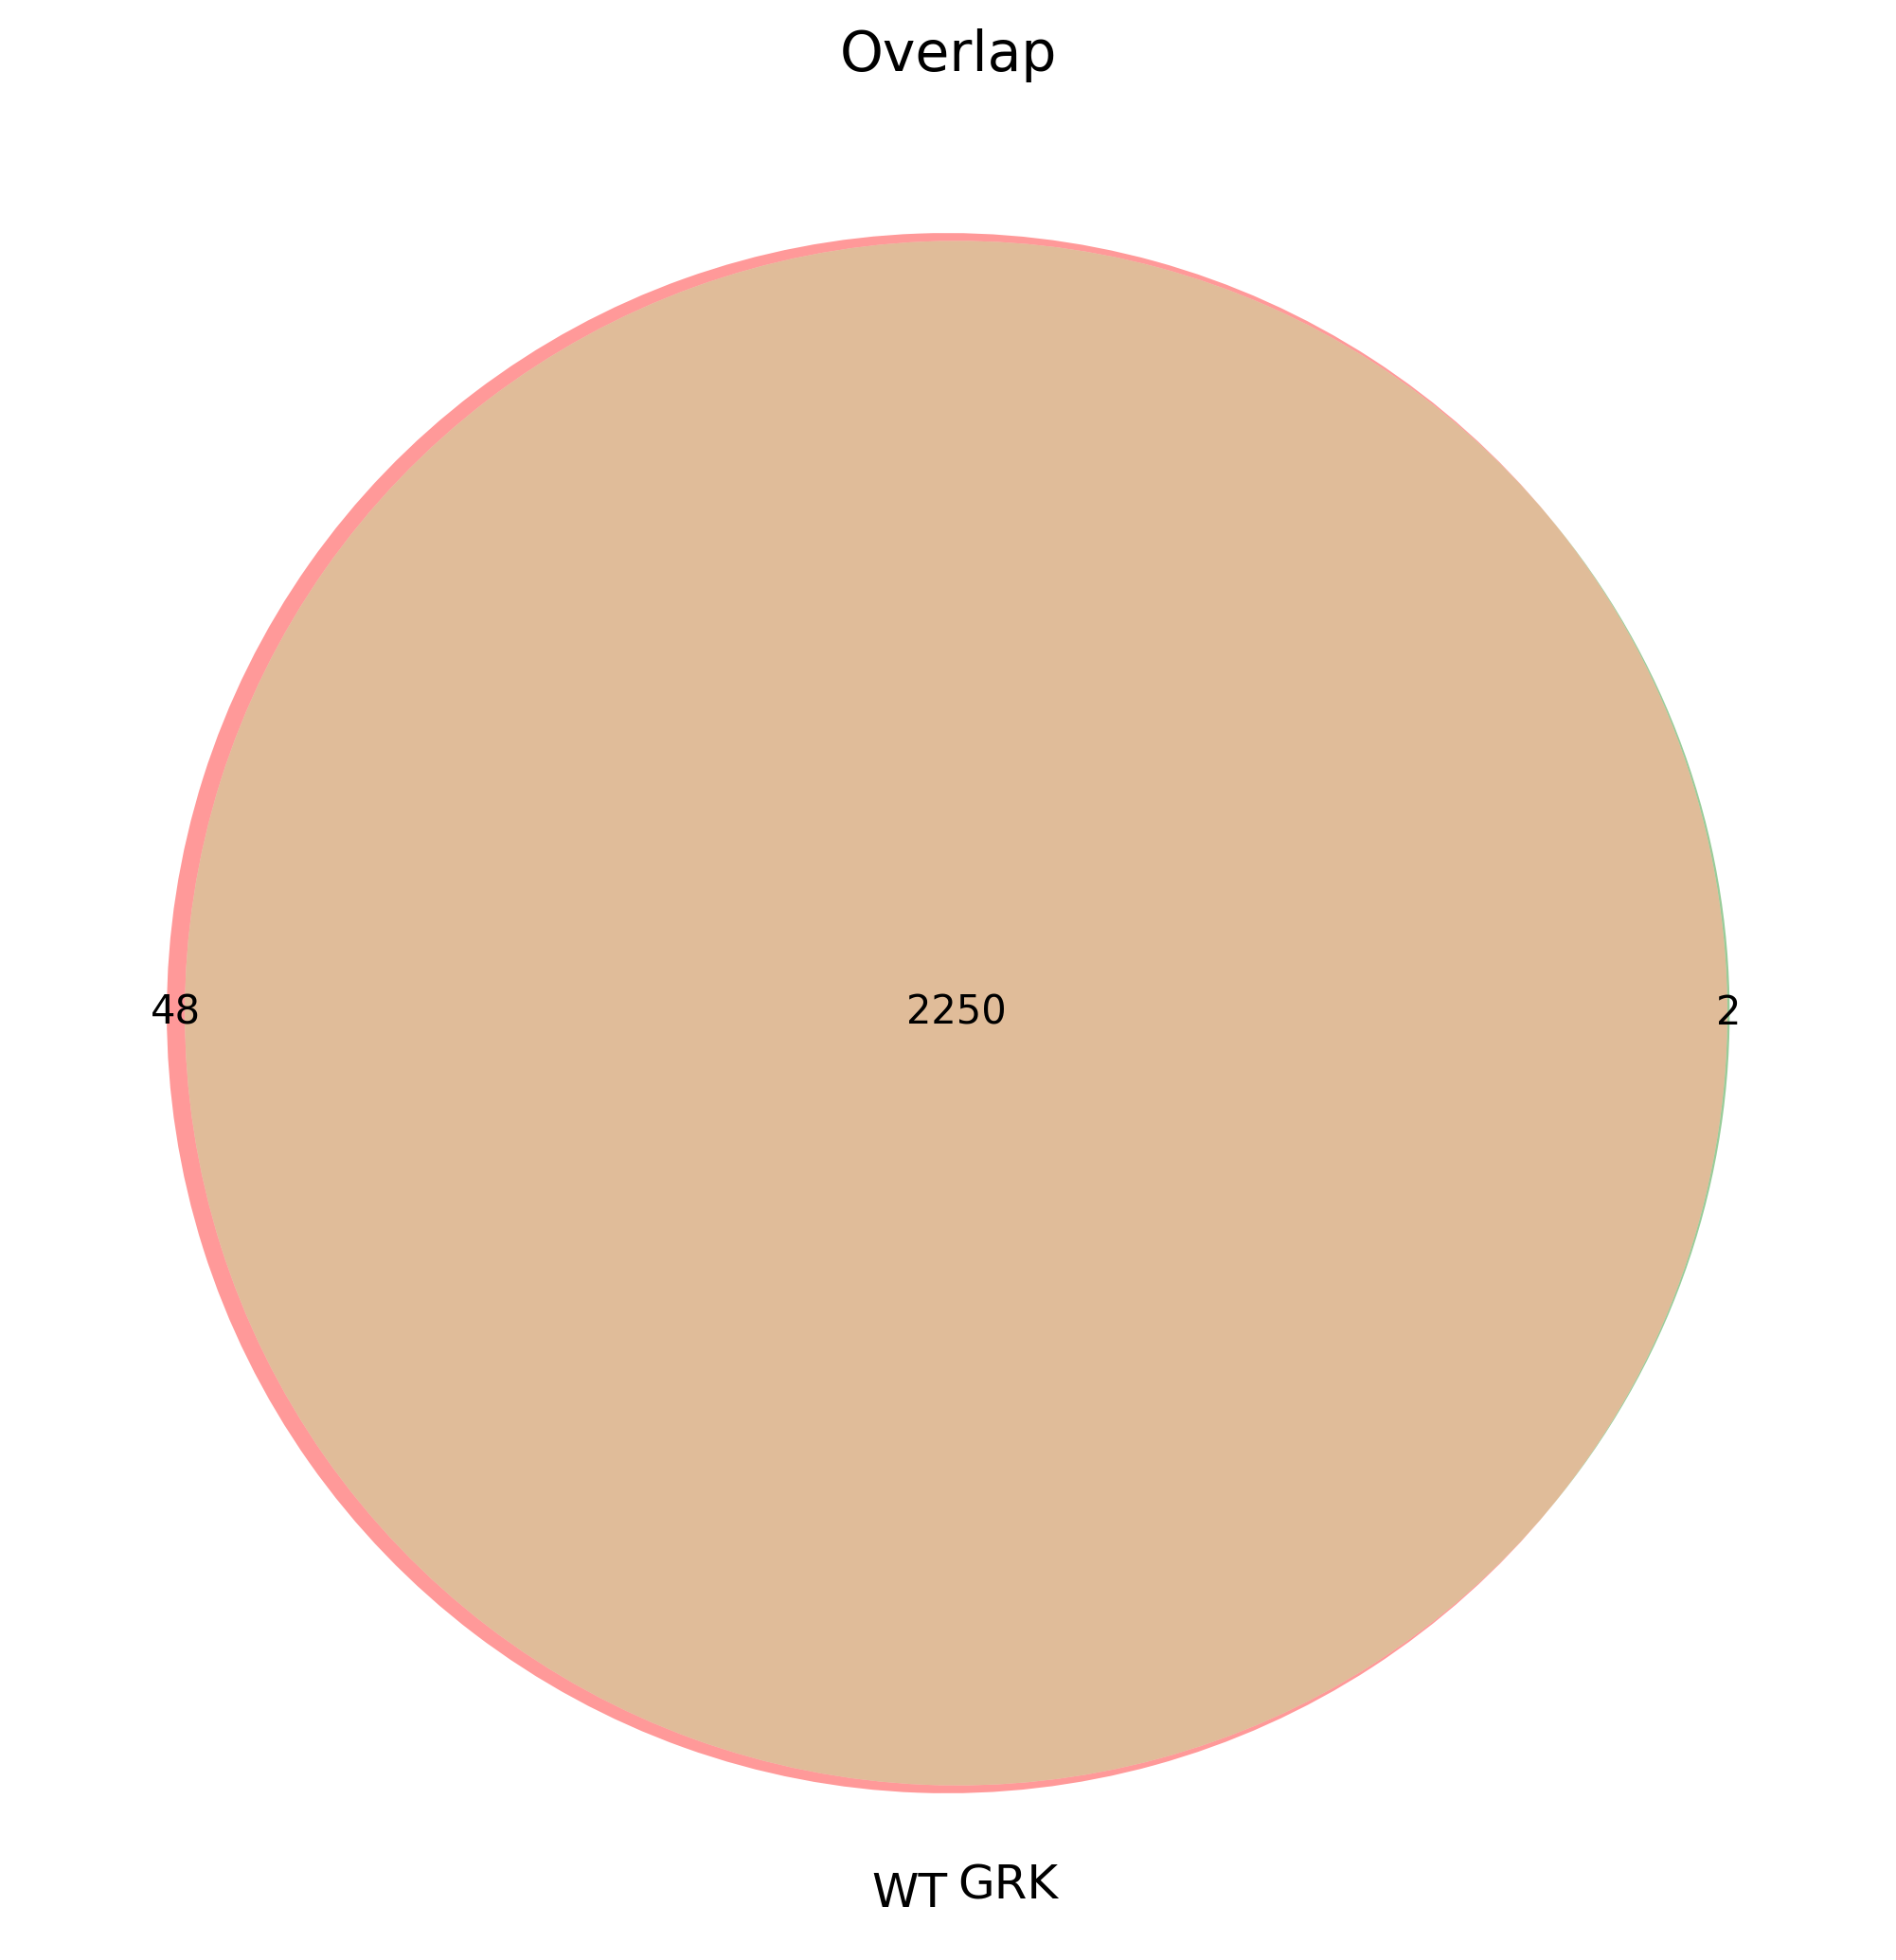

In [62]:
fig = overlap_plot_condition(data4_by_phosprot, meta2, "WT", "GRK")